
&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;[<img align ="left" width="400px" height="400px" src="https://case.edu.jm/wp-content/uploads/2020/05/CASE-LOGO-WHITE-1.png">](https://case.edu.jm/wp-content/uploads/2020/05/CASE-LOGO-WHITE-1.png)


# <center> Aerosol and chemical compounds in the Atmosphere over Mérida, Yucatàn State, Mexico </c>
### <center> Scientific Research Council Jamaica - 32nd Science and Technology Conference </c>


##### <center> $^{1}$ Jullian C.B. Williams </c>
##### <center> $^{1}$ College of Agriculture, Science and Education </c>
##### <center> Faculty of Applied Science, Engineering and Technology </c>
##### <center> P.O. BOX 170, Port Antonio, Portland, Jamaica </c>
###### <center> jullian.williams@case.edu.jm </c>

##### Install packages

In [1]:
# Pip installs for package updates etc. Hidden because it's annoying to look at.
# !pip install xarray
# !pip install hvplot
# !pip install rasterio
# !pip install rioxarray
# !pip install scikit-image
# !pip install matplotlib-scalebar
# !pip install openaq 
# !pip install matplotlib==3.4.2
# !pip install matplotlib
# !pip install seaborn
# !pip install shapely
# !pip install matplotlib
# !pip install geopandas
# !pip install fiona
# Imports have started giving problems in jupyterlab.. moved to notebook
# Printing now has to happen at jupyterlab.. Here we go.. again
# Printing now has to be done with specific - "Save to PDF" instead of "Print to MS PDF" -_-
# Printing will now delete itself from the desktop
# Printing now reverted back to "Print to MS PDF" - may have a delay
# Lin-reg work isn't necessary, just wanted to see how it looks. Not updating to git notebook since, not relevant. Everything else stays the same.

##### Importing packages

In [3]:
import os
import sys
import scipy
import openaq
import pprint
import warnings
import datetime
import numpy as np
import pandas as pd
import seaborn as sns
from openaq import OpenAQ
from numpy import transpose
from datetime import timedelta

from scipy.stats import t
import matplotlib.pyplot as plt
from scipy.stats import probplot
from pandas import json_normalize
from scipy.stats import normaltest
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit

from mpl_toolkits.mplot3d import Axes3D
from sklearn.pipeline import make_pipeline
from statsmodels.graphics.gofplots import qqplot
from sklearn.linear_model import LinearRegression
from scipy.optimize import differential_evolution
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score


import fiona
import rioxarray
import rasterio as rio
import geopandas as gpd
from pathlib import Path
import matplotlib as mpl
from rasterio.plot import show # plotting raster data
from rasterio.mask import mask
from shapely.geometry import shape
from rasterio.plot import show_hist #histograms of raster data
import matplotlib.ticker as mticker
import matplotlib.patches as patches
from rasterio.enums import Resampling
from matplotlib.colors import ListedColormap
from matplotlib_scalebar.scalebar import ScaleBar

In [2]:
# pd.set_option("display.max_colwidth", None) just incase items are truncated and you want to see. Enable scrolling if anything. ^_^

##### API Key and client side access
###### Hidden because - Duh!

In [3]:
api = openaq.OpenAQ(api_key='API_KEY')
client = OpenAQ(api_key="INSERT YOUR LOGIN API KEY FROM THE OPENAQ WEBSITE") #create your account here and check profile for API key: https://explore.openaq.org/login?redirect=/

#### Begin code running from the cloud

##### Location information

In [4]:
locations = client.locations.list(
    coordinates=(20.973272222222,-89.624811111111 ),
    radius=10,
    limit=1000
)
pprint.pp(locations)

LocationsResponse(headers=Headers(x_ratelimit_limit=60,
                                  x_ratelimit_remaining=59,
                                  x_ratelimit_used=1,
                                  x_ratelimit_reset=60),
                  meta=Meta(name='openaq-api',
                            website='/',
                            page=1,
                            limit=1000,
                            found=1),
                  results=[Location(id=8010,
                                    name='SDS01',
                                    locality='Mérida',
                                    timezone='America/Merida',
                                    country=CountryBase(id=157,
                                                        code='MX',
                                                        name='Mexico'),
                                    owner=OwnerBase(id=4,
                                                    name='Unknown Governmental '
                

In [5]:
dt = locations.dict()
td = json_normalize(dt['results'])
td

,id,name,locality,timezone,is_mobile,is_monitor,instruments,sensors,bounds,distance,...,owner.id,owner.name,provider.id,provider.name,coordinates.latitude,coordinates.longitude,datetime_first.utc,datetime_first.local,datetime_last.utc,datetime_last.local
0,8010,SDS01,Mérida,America/Merida,False,True,"[{'id': 2, 'name': 'Government Monitor'}]","[{'id': 23297, 'name': 'co ppm', 'parameter': ...","(-89.624811111111, 20.973272222222, -89.624811...",8.079252,...,4,Unknown Governmental Organization,223,Sinaica Mexico,20.973272,-89.624811,2020-10-16T00:00:00Z,2020-10-15T19:00:00-05:00,2026-10-24T13:00:00Z,2026-10-24T07:00:00-06:00


In [6]:
td.sensors

0    [{'id': 23297, 'name': 'co ppm', 'parameter': ...
Name: sensors, dtype: object

In [7]:
sense = [x for sublist in td["sensors"] for x in sublist]
print(sense)

[{'id': 23297, 'name': 'co ppm', 'parameter': {'id': 8, 'name': 'co', 'units': 'ppm', 'display_name': 'CO'}}, {'id': 5973565, 'name': 'no ppm', 'parameter': {'id': 35, 'name': 'no', 'units': 'ppm', 'display_name': 'NO'}}, {'id': 23240, 'name': 'no2 ppm', 'parameter': {'id': 7, 'name': 'no2', 'units': 'ppm', 'display_name': 'NO₂'}}, {'id': 5973555, 'name': 'nox ppm', 'parameter': {'id': 19840, 'name': 'nox', 'units': 'ppm', 'display_name': 'NOx'}}, {'id': 23293, 'name': 'o3 ppm', 'parameter': {'id': 10, 'name': 'o3', 'units': 'ppm', 'display_name': 'O₃'}}, {'id': 23296, 'name': 'pm25 µg/m³', 'parameter': {'id': 2, 'name': 'pm25', 'units': 'µg/m³', 'display_name': 'PM2.5'}}, {'id': 23298, 'name': 'so2 ppm', 'parameter': {'id': 9, 'name': 'so2', 'units': 'ppm', 'display_name': 'SO₂'}}]


In [8]:
se = pd.DataFrame(sense)
print(se)

        id        name                                          parameter
0    23297      co ppm  {'id': 8, 'name': 'co', 'units': 'ppm', 'displ...
1  5973565      no ppm  {'id': 35, 'name': 'no', 'units': 'ppm', 'disp...
2    23240     no2 ppm  {'id': 7, 'name': 'no2', 'units': 'ppm', 'disp...
3  5973555     nox ppm  {'id': 19840, 'name': 'nox', 'units': 'ppm', '...
4    23293      o3 ppm  {'id': 10, 'name': 'o3', 'units': 'ppm', 'disp...
5    23296  pm25 µg/m³  {'id': 2, 'name': 'pm25', 'units': 'µg/m³', 'd...
6    23298     so2 ppm  {'id': 9, 'name': 'so2', 'units': 'ppm', 'disp...


In [9]:
# pm1 = se.parameter[0]
# pm25 = se.parameter[1]
# relhum = se.parameter[2]
# temp = se.parameter[3]
# pm03 = se.parameter[4]

In [10]:
sx = se.parameter.T.tolist()

In [11]:
print(sx)

[{'id': 8, 'name': 'co', 'units': 'ppm', 'display_name': 'CO'}, {'id': 35, 'name': 'no', 'units': 'ppm', 'display_name': 'NO'}, {'id': 7, 'name': 'no2', 'units': 'ppm', 'display_name': 'NO₂'}, {'id': 19840, 'name': 'nox', 'units': 'ppm', 'display_name': 'NOx'}, {'id': 10, 'name': 'o3', 'units': 'ppm', 'display_name': 'O₃'}, {'id': 2, 'name': 'pm25', 'units': 'µg/m³', 'display_name': 'PM2.5'}, {'id': 9, 'name': 'so2', 'units': 'ppm', 'display_name': 'SO₂'}]


In [12]:
sx = pd.DataFrame(sx)
print(sx)

      id  name  units display_name
0      8    co    ppm           CO
1     35    no    ppm           NO
2      7   no2    ppm          NO₂
3  19840   nox    ppm          NOx
4     10    o3    ppm           O₃
5      2  pm25  µg/m³        PM2.5
6      9   so2    ppm          SO₂


In [13]:
clsfk = pd.concat([se['id'],sx],axis = 1)
print(clsfk)

end_date20= "2020-12-31T23:00:00Z"	
start_date20= "2020-01-01T23:00:00Z"	
end_date21= "2021-12-31T23:00:00Z"	
start_date21= "2021-01-01T23:00:00Z"
end_date22= "2022-12-31T23:00:00Z"	
start_date22= "2022-01-01T23:00:00Z"
end_date23= "2023-12-31T23:00:00Z"	
start_date23= "2023-01-01T23:00:00Z"
end_date24= "2024-12-31T23:00:00Z"	
start_date24= "2024-01-01T23:00:00Z"
end_date25= "2025-12-31T23:00:00Z"	
start_date25= "2025-01-01T23:00:00Z"
country = "Mexico"
city = "Merida"
lat = "20.973272222222"
long ="-89.624811111111"
# lat = "18.493461"
# long = "-67.086151"

        id     id  name  units display_name
0    23297      8    co    ppm           CO
1  5973565     35    no    ppm           NO
2    23240      7   no2    ppm          NO₂
3  5973555  19840   nox    ppm          NOx
4    23293     10    o3    ppm           O₃
5    23296      2  pm25  µg/m³        PM2.5
6    23298      9   so2    ppm          SO₂


#### Air years

#### 2020 (Df3 is null)

In [14]:
air = client.measurements.list(sensors_id=23297, datetime_from=start_date20, datetime_to=end_date20) #15351906
data = air.dict()
df = json_normalize(data['results'])

In [15]:
air1 = client.measurements.list(sensors_id=5973565, datetime_from=start_date20, datetime_to=end_date20) #15351907
data1 = air1.dict()
df1 = json_normalize(data['results'])

In [16]:
air2 = client.measurements.list(sensors_id=23240, datetime_from=start_date20, datetime_to=end_date20) #15351908
data2 = air2.dict()
df2 = json_normalize(data2['results'])

In [17]:
air3 = client.measurements.list(sensors_id=5973555, datetime_from=start_date20, datetime_to=end_date20) #15351909
data3 = air3.dict()
df3 = json_normalize(data3['results'])

In [18]:
air4 = client.measurements.list(sensors_id=23293, datetime_from=start_date20, datetime_to=end_date20) #15351910
data4 = air4.dict()
df4 = json_normalize(data4['results'])

In [19]:
air5 = client.measurements.list(sensors_id=23296, datetime_from=start_date20, datetime_to=end_date20) #15351910
data5 = air5.dict()
df5 = json_normalize(data5['results'])

In [20]:
air6 = client.measurements.list(sensors_id=23298, datetime_from=start_date20, datetime_to=end_date20) #15351910
data6 = air6.dict()
df6 = json_normalize(data6['results'])

In [21]:
df = df.rename(columns={"period.datetime_from.utc":"datetime"})
df1 = df1.rename(columns={"period.datetime_from.utc":"datetime"})
df2 = df2.rename(columns={"period.datetime_from.utc":"datetime"})
#df3 = df3.rename(columns={"period.datetime_from.utc":"datetime"})
df4 = df4.rename(columns={"period.datetime_from.utc":"datetime"})
df5 = df5.rename(columns={"period.datetime_from.utc":"datetime"})
df6 = df6.rename(columns={"period.datetime_from.utc":"datetime"})

In [22]:
df3.head()

""


In [23]:
df.head(3)

,value,coordinates,summary,period.label,period.interval,datetime,period.datetime_from.local,period.datetime_to.utc,period.datetime_to.local,parameter.id,...,coverage.expected_count,coverage.expected_interval,coverage.observed_count,coverage.observed_interval,coverage.percent_complete,coverage.percent_coverage,coverage.datetime_from.utc,coverage.datetime_from.local,coverage.datetime_to.utc,coverage.datetime_to.local
0,0.699910,None,None,raw,01:00:00,2020-10-15T23:00:00Z,2020-10-15T18:00:00-05:00,2020-10-16T00:00:00Z,2020-10-15T19:00:00-05:00,8,...,1,01:00:00,1,01:00:00,100.0,100.0,2020-10-15T23:00:00Z,2020-10-15T18:00:00-05:00,2020-10-16T00:00:00Z,2020-10-15T19:00:00-05:00
1,0.676767,None,None,raw,01:00:00,2020-10-16T00:00:00Z,2020-10-15T19:00:00-05:00,2020-10-16T01:00:00Z,2020-10-15T20:00:00-05:00,8,...,1,01:00:00,1,01:00:00,100.0,100.0,2020-10-16T00:00:00Z,2020-10-15T19:00:00-05:00,2020-10-16T01:00:00Z,2020-10-15T20:00:00-05:00
2,0.604288,None,None,raw,01:00:00,2020-10-16T01:00:00Z,2020-10-15T20:00:00-05:00,2020-10-16T02:00:00Z,2020-10-15T21:00:00-05:00,8,...,1,01:00:00,1,01:00:00,100.0,100.0,2020-10-16T01:00:00Z,2020-10-15T20:00:00-05:00,2020-10-16T02:00:00Z,2020-10-15T21:00:00-05:00


In [24]:
df["datetime"]=pd.to_datetime(df["datetime"])
df1["datetime"]=pd.to_datetime(df1["datetime"])
df2["datetime"]=pd.to_datetime(df2["datetime"])
#df3["datetime"]=pd.to_datetime(df3["datetime"])
df4["datetime"]=pd.to_datetime(df4["datetime"])
df5["datetime"]=pd.to_datetime(df5["datetime"])
df6["datetime"]=pd.to_datetime(df6["datetime"])

In [25]:
df["datetime"].min(), df["datetime"].max()

(Timestamp('2020-10-15 23:00:00+0000', tz='UTC'),
 Timestamp('2020-12-21 06:00:00+0000', tz='UTC'))

In [26]:
df["value"].min(), df["value"].max(),df1["value"].min(), df1["value"].max()

(0.0, 1.64697305, 0.0, 1.64697305)

In [27]:
df['parameter'] = clsfk.name[0]
df['unit'] = clsfk.units[0]
df['country'] = country
df['city'] = city
df['latitude'] = lat
df['longitude'] = long
df1['parameter'] = clsfk.name[1]
df1['unit'] = clsfk.units[1]
df1['country'] = country
df1['city'] = city
df1['latitude'] = lat
df1['longitude'] = long
df2['parameter'] = clsfk.name[2]
df2['unit'] = clsfk.units[2]
df2['country'] = country
df2['city'] = city
df2['latitude'] = lat
df2['longitude'] = long
# df3['parameter'] = clsfk.name[3]
# df3['unit'] = clsfk.units[3]
# df3['country'] = country
# df3['city'] = city
# df3['latitude'] = lat
# df3['longitude'] = long
df4['parameter'] = clsfk.name[4]
df4['unit'] = clsfk.units[4]
df4['country'] = country
df4['city'] = city
df4['latitude'] = lat
df4['longitude'] = long
df5['parameter'] = clsfk.name[5]
df5['unit'] = clsfk.units[5]
df5['country'] = country
df5['city'] = city
df5['latitude'] = lat
df5['longitude'] = long
df6['parameter'] = clsfk.name[6]
df6['unit'] = clsfk.units[6]
df6['country'] = country
df6['city'] = city
df6['latitude'] = lat
df6['longitude'] = long

In [28]:
df = df[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df1 = df1[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df2 = df2[['datetime','value','parameter','unit','country','city','latitude','longitude']]
#df3 = df3[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df4 = df4[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df5 = df5[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6 = df6[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2020-10-15 23:00:00+00:00,0.001346,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2020-10-16 00:00:00+00:00,0.001225,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2020-10-16 01:00:00+00:00,0.001180,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2020-10-16 02:00:00+00:00,0.001275,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2020-10-16 03:00:00+00:00,0.001211,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
409,2020-12-31 12:00:00+00:00,0.000477,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
410,2020-12-31 13:00:00+00:00,0.000565,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
411,2020-12-31 14:00:00+00:00,0.000246,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
412,2020-12-31 15:00:00+00:00,0.000475,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


In [29]:
df = df[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df1 = df1[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df2 = df2[['datetime','value','parameter','unit','country','city','latitude','longitude']]
#df3 = df3[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df4 = df4[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df5 = df5[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6 = df6[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2020-10-15 23:00:00+00:00,0.001346,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2020-10-16 00:00:00+00:00,0.001225,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2020-10-16 01:00:00+00:00,0.001180,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2020-10-16 02:00:00+00:00,0.001275,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2020-10-16 03:00:00+00:00,0.001211,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
409,2020-12-31 12:00:00+00:00,0.000477,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
410,2020-12-31 13:00:00+00:00,0.000565,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
411,2020-12-31 14:00:00+00:00,0.000246,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
412,2020-12-31 15:00:00+00:00,0.000475,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


In [30]:
# Df = pd.concat([df2,df3,df4])
# Df

In [31]:
# PMDf = pd.concat([df,df1])
# PMDf

In [32]:
Df20 = pd.concat([df,df1,df2,df4,df5,df6])
# Df20.dropna()
Df20

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2020-10-15 23:00:00+00:00,0.699910,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2020-10-16 00:00:00+00:00,0.676767,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2020-10-16 01:00:00+00:00,0.604288,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2020-10-16 02:00:00+00:00,0.641566,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2020-10-16 03:00:00+00:00,0.582559,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
409,2020-12-31 12:00:00+00:00,0.000477,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
410,2020-12-31 13:00:00+00:00,0.000565,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
411,2020-12-31 14:00:00+00:00,0.000246,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
412,2020-12-31 15:00:00+00:00,0.000475,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


#### 2021 (Df3 is null)

In [33]:
air = client.measurements.list(sensors_id=23297, datetime_from=start_date21, datetime_to=end_date21)
data = air.dict()
df = json_normalize(data['results'])

In [34]:
air1 = client.measurements.list(sensors_id=5973565, datetime_from=start_date21, datetime_to=end_date21)
data1 = air1.dict()
df1 = json_normalize(data['results'])

In [35]:
air2 = client.measurements.list(sensors_id=23240, datetime_from=start_date21, datetime_to=end_date21)
data2 = air2.dict()
df2 = json_normalize(data2['results'])

In [36]:
air3 = client.measurements.list(sensors_id=5973555, datetime_from=start_date21, datetime_to=end_date21)
data3 = air3.dict()
df3 = json_normalize(data3['results'])

In [37]:
air4 = client.measurements.list(sensors_id=23293, datetime_from=start_date21, datetime_to=end_date21)
data4 = air4.dict()
df4 = json_normalize(data4['results'])

In [38]:
air5 = client.measurements.list(sensors_id=23296, datetime_from=start_date21, datetime_to=end_date21)
data5 = air5.dict()
df5 = json_normalize(data5['results'])

In [39]:
air6 = client.measurements.list(sensors_id=23298, datetime_from=start_date21, datetime_to=end_date21)
data6 = air6.dict()
df6 = json_normalize(data6['results'])

In [40]:
df = df.rename(columns={"period.datetime_from.utc":"datetime"})
df1 = df1.rename(columns={"period.datetime_from.utc":"datetime"})
df2 = df2.rename(columns={"period.datetime_from.utc":"datetime"})
df3 = df3.rename(columns={"period.datetime_from.utc":"datetime"})
df4 = df4.rename(columns={"period.datetime_from.utc":"datetime"})
df5 = df5.rename(columns={"period.datetime_from.utc":"datetime"})
df6 = df6.rename(columns={"period.datetime_from.utc":"datetime"})

In [41]:
df3.head(3)

""


In [42]:
df["datetime"]=pd.to_datetime(df["datetime"])
df1["datetime"]=pd.to_datetime(df1["datetime"])
df2["datetime"]=pd.to_datetime(df2["datetime"])
#df3["datetime"]=pd.to_datetime(df3["datetime"])
df4["datetime"]=pd.to_datetime(df4["datetime"])
df5["datetime"]=pd.to_datetime(df5["datetime"])
df6["datetime"]=pd.to_datetime(df6["datetime"])

In [43]:
df['parameter'] = clsfk.name[0]
df['unit'] = clsfk.units[0]
df['country'] = country
df['city'] = city
df['latitude'] = lat
df['longitude'] = long
df1['parameter'] = clsfk.name[1]
df1['unit'] = clsfk.units[1]
df1['country'] = country
df1['city'] = city
df1['latitude'] = lat
df1['longitude'] = long
df2['parameter'] = clsfk.name[2]
df2['unit'] = clsfk.units[2]
df2['country'] = country
df2['city'] = city
df2['latitude'] = lat
df2['longitude'] = long
# df3['parameter'] = clsfk.name[3]
# df3['unit'] = clsfk.units[3]
# df3['country'] = country
# df3['city'] = city
# df3['latitude'] = lat
# df3['longitude'] = long
df4['parameter'] = clsfk.name[4]
df4['unit'] = clsfk.units[4]
df4['country'] = country
df4['city'] = city
df4['latitude'] = lat
df4['longitude'] = long
df5['parameter'] = clsfk.name[5]
df5['unit'] = clsfk.units[5]
df5['country'] = country
df5['city'] = city
df5['latitude'] = lat
df5['longitude'] = long
df6['parameter'] = clsfk.name[6]
df6['unit'] = clsfk.units[6]
df6['country'] = country
df6['city'] = city
df6['latitude'] = lat
df6['longitude'] = long

In [44]:
df = df[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df1 = df1[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df2 = df2[['datetime','value','parameter','unit','country','city','latitude','longitude']]
# df3 = df3[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df4 = df4[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df5 = df5[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6 = df6[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2021-01-03 00:00:00+00:00,0.000293,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2021-01-03 01:00:00+00:00,0.000406,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2021-01-03 02:00:00+00:00,0.000203,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2021-01-03 03:00:00+00:00,0.000492,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2021-01-03 04:00:00+00:00,0.000602,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
995,2021-02-14 21:00:00+00:00,0.000880,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
996,2021-02-14 22:00:00+00:00,0.000863,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
997,2021-02-14 23:00:00+00:00,0.001306,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
998,2021-02-16 00:00:00+00:00,0.000882,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


In [45]:
Df21 = pd.concat([df,df1,df2,df4,df5,df6])
Df21

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2021-01-03 00:00:00+00:00,0.922504,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2021-01-03 01:00:00+00:00,0.923769,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2021-01-03 02:00:00+00:00,0.904000,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2021-01-03 03:00:00+00:00,0.909762,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2021-01-03 04:00:00+00:00,0.899229,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
995,2021-02-14 21:00:00+00:00,0.000880,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
996,2021-02-14 22:00:00+00:00,0.000863,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
997,2021-02-14 23:00:00+00:00,0.001306,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
998,2021-02-16 00:00:00+00:00,0.000882,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


#### 2022 (All appear null eventhough the code runs)

In [443]:
air = client.measurements.list(sensors_id=23297, datetime_from=start_date22, datetime_to=end_date22)
data = air.dict()
df = json_normalize(data['results'])

In [444]:
air1 = client.measurements.list(sensors_id=5973565, datetime_from=start_date22, datetime_to=end_date22)
data1 = air1.dict()
df1 = json_normalize(data['results'])

In [445]:
air2 = client.measurements.list(sensors_id=23240, datetime_from=start_date22, datetime_to=end_date22)
data2 = air2.dict()
df2 = json_normalize(data2['results'])

In [446]:
air3 = client.measurements.list(sensors_id=5973555, datetime_from=start_date22, datetime_to=end_date22)
data3 = air3.dict()
df3 = json_normalize(data3['results'])

In [447]:
air4 = client.measurements.list(sensors_id=23293, datetime_from=start_date22, datetime_to=end_date22)
data4 = air4.dict()
df4 = json_normalize(data4['results'])

In [448]:
air5 = client.measurements.list(sensors_id=23296, datetime_from=start_date22, datetime_to=end_date22)
data5 = air5.dict()
df5 = json_normalize(data5['results'])

In [449]:
air6 = client.measurements.list(sensors_id=23298, datetime_from=start_date22, datetime_to=end_date22)
data6 = air6.dict()
df6 = json_normalize(data6['results'])

In [450]:
df = df.rename(columns={"period.datetime_from.utc":"datetime"})
df1 = df1.rename(columns={"period.datetime_from.utc":"datetime"})
df2 = df2.rename(columns={"period.datetime_from.utc":"datetime"})
#df3 = df3.rename(columns={"period.datetime_from.utc":"datetime"})
df4 = df4.rename(columns={"period.datetime_from.utc":"datetime"})
df5 = df5.rename(columns={"period.datetime_from.utc":"datetime"})
df6 = df6.rename(columns={"period.datetime_from.utc":"datetime"})

In [451]:
df3.head(3), df.head(3), df1.head(3)

(Empty DataFrame
 Columns: []
 Index: [],
 Empty DataFrame
 Columns: []
 Index: [],
 Empty DataFrame
 Columns: []
 Index: [])

In [ ]:
df["datetime"]=pd.to_datetime(df["datetime"])
df1["datetime"]=pd.to_datetime(df1["datetime"])
df2["datetime"]=pd.to_datetime(df2["datetime"])
#df3["datetime"]=pd.to_datetime(df3["datetime"])
df4["datetime"]=pd.to_datetime(df4["datetime"])
df5["datetime"]=pd.to_datetime(df5["datetime"])
df6["datetime"]=pd.to_datetime(df6["datetime"])

In [ ]:
df['parameter'] = clsfk.name[0]
df['unit'] = clsfk.units[0]
df['country'] = country
df['city'] = city
df['latitude'] = lat
df['longitude'] = long
df1['parameter'] = clsfk.name[1]
df1['unit'] = clsfk.units[1]
df1['country'] = country
df1['city'] = city
df1['latitude'] = lat
df1['longitude'] = long
df2['parameter'] = clsfk.name[2]
df2['unit'] = clsfk.units[2]
df2['country'] = country
df2['city'] = city
df2['latitude'] = lat
df2['longitude'] = long
# df3['parameter'] = clsfk.name[3]
# df3['unit'] = clsfk.units[3]
# df3['country'] = country
# df3['city'] = city
# df3['latitude'] = lat
# df3['longitude'] = long
df4['parameter'] = clsfk.name[4]
df4['unit'] = clsfk.units[4]
df4['country'] = country
df4['city'] = city
df4['latitude'] = lat
df4['longitude'] = long
df5['parameter'] = clsfk.name[5]
df5['unit'] = clsfk.units[5]
df5['country'] = country
df5['city'] = city
df5['latitude'] = lat
df5['longitude'] = long
df6['parameter'] = clsfk.name[6]
df6['unit'] = clsfk.units[6]
df6['country'] = country
df6['city'] = city
df6['latitude'] = lat
df6['longitude'] = long

In [ ]:
df = df[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df1 = df1[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df2 = df2[['datetime','value','parameter','unit','country','city','latitude','longitude']]
# df3 = df3[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df4 = df4[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df5 = df5[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6 = df6[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6

In [ ]:
Df22 = pd.concat([df,df1,df2,df4,df5,df6])
Df22

#### 2023 (All accounted for)

In [46]:
air = client.measurements.list(sensors_id=23297, datetime_from=start_date23, datetime_to=end_date23)
data = air.dict()
df = json_normalize(data['results'])

In [47]:
air1 = client.measurements.list(sensors_id=5973565, datetime_from=start_date23, datetime_to=end_date23)
data1 = air1.dict()
df1 = json_normalize(data['results'])

In [48]:
air2 = client.measurements.list(sensors_id=23240, datetime_from=start_date23, datetime_to=end_date23)
data2 = air2.dict()
df2 = json_normalize(data2['results'])

In [49]:
air3 = client.measurements.list(sensors_id=5973555, datetime_from=start_date23, datetime_to=end_date23)
data3 = air3.dict()
df3 = json_normalize(data3['results'])

In [50]:
air4 = client.measurements.list(sensors_id=23293, datetime_from=start_date23, datetime_to=end_date23)
data4 = air4.dict()
df4 = json_normalize(data4['results'])

In [51]:
air5 = client.measurements.list(sensors_id=23296, datetime_from=start_date23, datetime_to=end_date23)
data5 = air5.dict()
df5 = json_normalize(data5['results'])

In [52]:
air6 = client.measurements.list(sensors_id=23298, datetime_from=start_date23, datetime_to=end_date23)
data6 = air6.dict()
df6 = json_normalize(data6['results'])

In [53]:
df = df.rename(columns={"period.datetime_from.utc":"datetime"})
df1 = df1.rename(columns={"period.datetime_from.utc":"datetime"})
df2 = df2.rename(columns={"period.datetime_from.utc":"datetime"})
df3 = df3.rename(columns={"period.datetime_from.utc":"datetime"})
df4 = df4.rename(columns={"period.datetime_from.utc":"datetime"})
df5 = df5.rename(columns={"period.datetime_from.utc":"datetime"})
df6 = df6.rename(columns={"period.datetime_from.utc":"datetime"})

In [54]:
df["datetime"]=pd.to_datetime(df["datetime"])
df1["datetime"]=pd.to_datetime(df1["datetime"])
df2["datetime"]=pd.to_datetime(df2["datetime"])
df3["datetime"]=pd.to_datetime(df3["datetime"])
df4["datetime"]=pd.to_datetime(df4["datetime"])
df5["datetime"]=pd.to_datetime(df5["datetime"])
df6["datetime"]=pd.to_datetime(df6["datetime"])

In [55]:
df['parameter'] = clsfk.name[0]
df['unit'] = clsfk.units[0]
df['country'] = country
df['city'] = city
df['latitude'] = lat
df['longitude'] = long
df1['parameter'] = clsfk.name[1]
df1['unit'] = clsfk.units[1]
df1['country'] = country
df1['city'] = city
df1['latitude'] = lat
df1['longitude'] = long
df2['parameter'] = clsfk.name[2]
df2['unit'] = clsfk.units[2]
df2['country'] = country
df2['city'] = city
df2['latitude'] = lat
df2['longitude'] = long
df3['parameter'] = clsfk.name[3]
df3['unit'] = clsfk.units[3]
df3['country'] = country
df3['city'] = city
df3['latitude'] = lat
df3['longitude'] = long
df4['parameter'] = clsfk.name[4]
df4['unit'] = clsfk.units[4]
df4['country'] = country
df4['city'] = city
df4['latitude'] = lat
df4['longitude'] = long
df5['parameter'] = clsfk.name[5]
df5['unit'] = clsfk.units[5]
df5['country'] = country
df5['city'] = city
df5['latitude'] = lat
df5['longitude'] = long
df6['parameter'] = clsfk.name[6]
df6['unit'] = clsfk.units[6]
df6['country'] = country
df6['city'] = city
df6['latitude'] = lat
df6['longitude'] = long

In [56]:
df = df[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df1 = df1[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df2 = df2[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df3 = df3[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df4 = df4[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df5 = df5[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6 = df6[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2023-01-19 20:00:00+00:00,0.208897,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2023-01-19 22:00:00+00:00,0.001041,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2023-01-19 23:00:00+00:00,0.000849,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2023-01-20 00:00:00+00:00,0.000698,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2023-01-20 01:00:00+00:00,0.000693,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
916,2023-08-24 19:00:00+00:00,0.000278,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
917,2023-08-24 20:00:00+00:00,0.018755,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
918,2023-12-20 11:00:00+00:00,0.000107,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
919,2023-12-20 12:00:00+00:00,0.000277,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


In [57]:
Df23 = pd.concat([df,df1,df2,df3,df4,df5,df6])
Df23

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2023-01-21 07:00:00+00:00,0.000000,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2023-01-25 02:00:00+00:00,0.000000,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2023-03-21 11:00:00+00:00,0.000000,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2023-07-22 02:00:00+00:00,0.000000,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2023-08-23 19:00:00+00:00,NaN,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
916,2023-08-24 19:00:00+00:00,0.000278,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
917,2023-08-24 20:00:00+00:00,0.018755,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
918,2023-12-20 11:00:00+00:00,0.000107,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
919,2023-12-20 12:00:00+00:00,0.000277,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


#### 2024 (All accounted for)

In [58]:
air = client.measurements.list(sensors_id=23297, datetime_from=start_date24, datetime_to=end_date24)
data = air.dict()
df = json_normalize(data['results'])

In [59]:
air1 = client.measurements.list(sensors_id=5973565, datetime_from=start_date24, datetime_to=end_date24)
data1 = air1.dict()
df1 = json_normalize(data['results'])

In [60]:
air2 = client.measurements.list(sensors_id=23240, datetime_from=start_date24, datetime_to=end_date24)
data2 = air2.dict()
df2 = json_normalize(data2['results'])

In [61]:
air3 = client.measurements.list(sensors_id=5973555, datetime_from=start_date24, datetime_to=end_date24)
data3 = air3.dict()
df3 = json_normalize(data3['results'])

In [62]:
air4 = client.measurements.list(sensors_id=23293, datetime_from=start_date24, datetime_to=end_date24)
data4 = air4.dict()
df4 = json_normalize(data4['results'])

In [63]:
air5 = client.measurements.list(sensors_id=23296, datetime_from=start_date24, datetime_to=end_date24)
data5 = air5.dict()
df5 = json_normalize(data5['results'])

In [64]:
air6 = client.measurements.list(sensors_id=23298, datetime_from=start_date24, datetime_to=end_date24)
data6 = air6.dict()
df6 = json_normalize(data6['results'])

In [65]:
df = df.rename(columns={"period.datetime_from.utc":"datetime"})
df1 = df1.rename(columns={"period.datetime_from.utc":"datetime"})
df2 = df2.rename(columns={"period.datetime_from.utc":"datetime"})
df3 = df3.rename(columns={"period.datetime_from.utc":"datetime"})
df4 = df4.rename(columns={"period.datetime_from.utc":"datetime"})
df5 = df5.rename(columns={"period.datetime_from.utc":"datetime"})
df6 = df6.rename(columns={"period.datetime_from.utc":"datetime"})

In [66]:
df["datetime"]=pd.to_datetime(df["datetime"])
df1["datetime"]=pd.to_datetime(df1["datetime"])
df2["datetime"]=pd.to_datetime(df2["datetime"])
df3["datetime"]=pd.to_datetime(df3["datetime"])
df4["datetime"]=pd.to_datetime(df4["datetime"])
df5["datetime"]=pd.to_datetime(df5["datetime"])
df6["datetime"]=pd.to_datetime(df6["datetime"])

In [67]:
df['parameter'] = clsfk.name[0]
df['unit'] = clsfk.units[0]
df['country'] = country
df['city'] = city
df['latitude'] = lat
df['longitude'] = long
df1['parameter'] = clsfk.name[1]
df1['unit'] = clsfk.units[1]
df1['country'] = country
df1['city'] = city
df1['latitude'] = lat
df1['longitude'] = long
df2['parameter'] = clsfk.name[2]
df2['unit'] = clsfk.units[2]
df2['country'] = country
df2['city'] = city
df2['latitude'] = lat
df2['longitude'] = long
df3['parameter'] = clsfk.name[3]
df3['unit'] = clsfk.units[3]
df3['country'] = country
df3['city'] = city
df3['latitude'] = lat
df3['longitude'] = long
df4['parameter'] = clsfk.name[4]
df4['unit'] = clsfk.units[4]
df4['country'] = country
df4['city'] = city
df4['latitude'] = lat
df4['longitude'] = long
df5['parameter'] = clsfk.name[5]
df5['unit'] = clsfk.units[5]
df5['country'] = country
df5['city'] = city
df5['latitude'] = lat
df5['longitude'] = long
df6['parameter'] = clsfk.name[6]
df6['unit'] = clsfk.units[6]
df6['country'] = country
df6['city'] = city
df6['latitude'] = lat
df6['longitude'] = long

In [68]:
df = df[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df1 = df1[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df2 = df2[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df3 = df3[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df4 = df4[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df5 = df5[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6 = df6[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2024-01-09 21:00:00+00:00,1.663000e-08,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2024-02-07 07:00:00+00:00,1.834939e-04,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2024-02-07 08:00:00+00:00,6.698502e-05,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2024-02-07 09:00:00+00:00,5.546915e-05,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2024-02-07 10:00:00+00:00,3.918859e-04,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
65,2024-03-09 00:00:00+00:00,2.030911e-04,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
66,2024-03-09 01:00:00+00:00,1.117752e-04,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
67,2024-03-09 02:00:00+00:00,6.342558e-05,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
68,2024-03-09 03:00:00+00:00,1.134886e-04,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


In [69]:
Df24 = pd.concat([df,df1,df2,df3,df4,df5,df6])
Df24

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2024-04-01 19:00:00+00:00,1.113699,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2024-04-01 20:00:00+00:00,0.836295,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2024-04-01 21:00:00+00:00,0.744609,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2024-04-01 22:00:00+00:00,0.652718,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2024-04-01 23:00:00+00:00,0.626328,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
65,2024-03-09 00:00:00+00:00,0.000203,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
66,2024-03-09 01:00:00+00:00,0.000112,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
67,2024-03-09 02:00:00+00:00,0.000063,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
68,2024-03-09 03:00:00+00:00,0.000113,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


#### 2025 (All accounted for)

In [70]:
air = client.measurements.list(sensors_id=23297, datetime_from=start_date25, datetime_to=end_date25)
data = air.dict()
df = json_normalize(data['results'])

In [71]:
air1 = client.measurements.list(sensors_id=5973565, datetime_from=start_date25, datetime_to=end_date25)
data1 = air1.dict()
df1 = json_normalize(data['results'])

In [72]:
air2 = client.measurements.list(sensors_id=23240, datetime_from=start_date25, datetime_to=end_date25)
data2 = air2.dict()
df2 = json_normalize(data2['results'])

In [73]:
air3 = client.measurements.list(sensors_id=5973555, datetime_from=start_date25, datetime_to=end_date25)
data3 = air3.dict()
df3 = json_normalize(data3['results'])

In [74]:
air4 = client.measurements.list(sensors_id=23293, datetime_from=start_date25, datetime_to=end_date25)
data4 = air4.dict()
df4 = json_normalize(data4['results'])

In [75]:
air5 = client.measurements.list(sensors_id=23296, datetime_from=start_date25, datetime_to=end_date25)
data5 = air5.dict()
df5 = json_normalize(data5['results'])

In [76]:
air6 = client.measurements.list(sensors_id=23298, datetime_from=start_date25, datetime_to=end_date25)
data6 = air6.dict()
df6 = json_normalize(data6['results'])

In [77]:
df = df.rename(columns={"period.datetime_from.utc":"datetime"})
df1 = df1.rename(columns={"period.datetime_from.utc":"datetime"})
df2 = df2.rename(columns={"period.datetime_from.utc":"datetime"})
df3 = df3.rename(columns={"period.datetime_from.utc":"datetime"})
df4 = df4.rename(columns={"period.datetime_from.utc":"datetime"})
df5 = df5.rename(columns={"period.datetime_from.utc":"datetime"})
df6 = df6.rename(columns={"period.datetime_from.utc":"datetime"})

In [78]:
df["datetime"]=pd.to_datetime(df["datetime"])
df1["datetime"]=pd.to_datetime(df1["datetime"])
df2["datetime"]=pd.to_datetime(df2["datetime"])
df3["datetime"]=pd.to_datetime(df3["datetime"])
df4["datetime"]=pd.to_datetime(df4["datetime"])
df5["datetime"]=pd.to_datetime(df5["datetime"])
df6["datetime"]=pd.to_datetime(df6["datetime"])

In [79]:
df['parameter'] = clsfk.name[0]
df['unit'] = clsfk.units[0]
df['country'] = country
df['city'] = city
df['latitude'] = lat
df['longitude'] = long
df1['parameter'] = clsfk.name[1]
df1['unit'] = clsfk.units[1]
df1['country'] = country
df1['city'] = city
df1['latitude'] = lat
df1['longitude'] = long
df2['parameter'] = clsfk.name[2]
df2['unit'] = clsfk.units[2]
df2['country'] = country
df2['city'] = city
df2['latitude'] = lat
df2['longitude'] = long
df3['parameter'] = clsfk.name[3]
df3['unit'] = clsfk.units[3]
df3['country'] = country
df3['city'] = city
df3['latitude'] = lat
df3['longitude'] = long
df4['parameter'] = clsfk.name[4]
df4['unit'] = clsfk.units[4]
df4['country'] = country
df4['city'] = city
df4['latitude'] = lat
df4['longitude'] = long
df5['parameter'] = clsfk.name[5]
df5['unit'] = clsfk.units[5]
df5['country'] = country
df5['city'] = city
df5['latitude'] = lat
df5['longitude'] = long
df6['parameter'] = clsfk.name[6]
df6['unit'] = clsfk.units[6]
df6['country'] = country
df6['city'] = city
df6['latitude'] = lat
df6['longitude'] = long

In [80]:
df = df[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df1 = df1[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df2 = df2[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df3 = df3[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df4 = df4[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df5 = df5[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6 = df6[['datetime','value','parameter','unit','country','city','latitude','longitude']]
df6

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2025-08-06 17:00:00+00:00,0.369236,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2025-08-06 18:00:00+00:00,0.291858,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2025-08-07 14:00:00+00:00,0.111686,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2025-08-07 15:00:00+00:00,0.167132,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2025-08-07 16:00:00+00:00,0.206559,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
995,2025-09-19 02:00:00+00:00,0.000352,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
996,2025-09-19 03:00:00+00:00,0.000330,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
997,2025-09-19 04:00:00+00:00,0.000312,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
998,2025-09-19 05:00:00+00:00,0.000308,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


In [81]:
Df25 = pd.concat([df,df1,df2,df3,df4,df5,df6])
Df25

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2025-02-10 14:00:00+00:00,2.185809,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2025-02-10 15:00:00+00:00,2.162163,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2025-02-10 16:00:00+00:00,2.126625,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2025-02-10 17:00:00+00:00,2.126918,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2025-02-10 18:00:00+00:00,2.141953,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
995,2025-09-19 02:00:00+00:00,0.000352,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
996,2025-09-19 03:00:00+00:00,0.000330,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
997,2025-09-19 04:00:00+00:00,0.000312,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
998,2025-09-19 05:00:00+00:00,0.000308,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


In [82]:
Dft = pd.concat([Df20,Df21,Df23,Df24,Df25]) #Df22 is empty
Dft

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2020-10-15 23:00:00+00:00,0.699910,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2020-10-16 00:00:00+00:00,0.676767,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2020-10-16 01:00:00+00:00,0.604288,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
3,2020-10-16 02:00:00+00:00,0.641566,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
4,2020-10-16 03:00:00+00:00,0.582559,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
995,2025-09-19 02:00:00+00:00,0.000352,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
996,2025-09-19 03:00:00+00:00,0.000330,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
997,2025-09-19 04:00:00+00:00,0.000312,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111
998,2025-09-19 05:00:00+00:00,0.000308,so2,ppm,Mexico,Merida,20.973272222222,-89.624811111111


In [88]:
hr = (Dft.groupby([Dft["datetime"].dt.hour,'parameter']))["value"].mean().unstack()
wk = (Dft.groupby([Dft["datetime"].dt.weekday,'parameter']))["value"].mean().unstack()
mt = (Dft.groupby([Dft["datetime"].dt.month,'parameter']))["value"].mean().unstack()
yr = (Dft.groupby([Dft["datetime"].dt.year,'parameter']))["value"].mean().unstack()

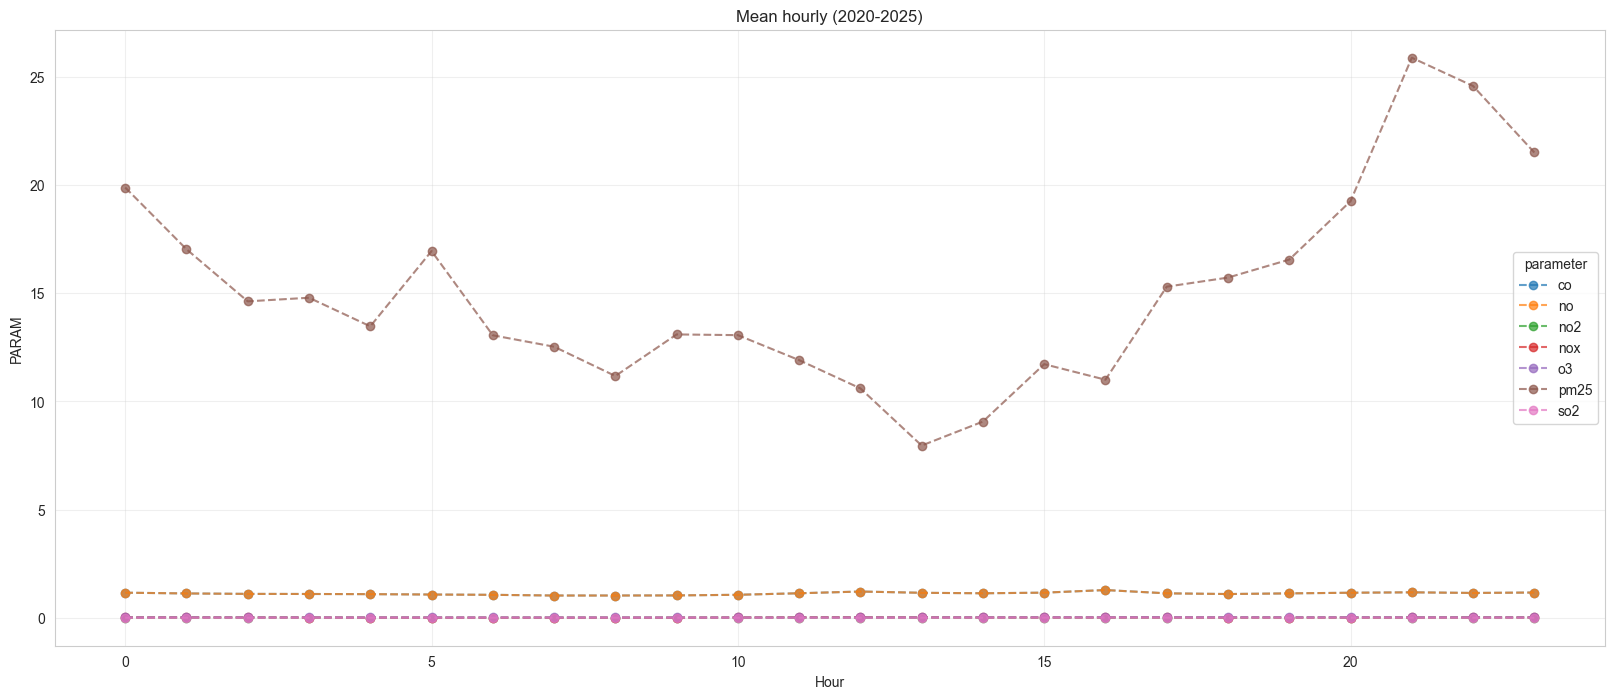

In [468]:
Dft.groupby([Dft["datetime"].dt.hour,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='o', linestyle='--', alpha = 0.7)
plt.ylabel('PARAM')
plt.xlabel('Hour')
plt.title('Mean hourly (2020-2025)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/hrly_20_25.jpeg", dpi = 1200)
plt.show()

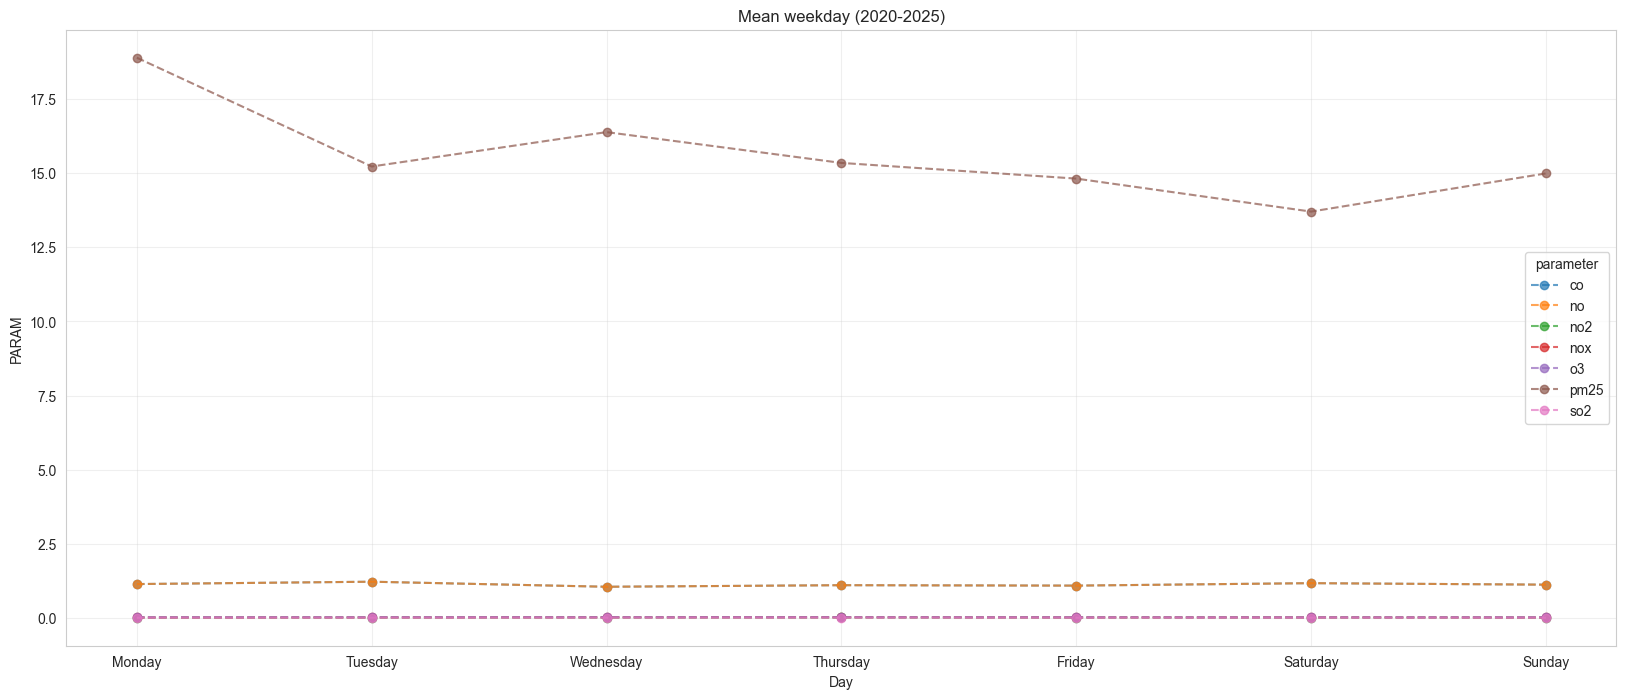

In [469]:
Dft.groupby([Dft["datetime"].dt.weekday,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='o', linestyle='--', alpha = 0.7)
plt.xticks([0,1,2,3,4,5,6],['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
plt.ylabel('PARAM')
plt.xlabel('Day')
plt.title('Mean weekday (2020-2025)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/week_20_25.jpeg", dpi = 1200)
plt.show()

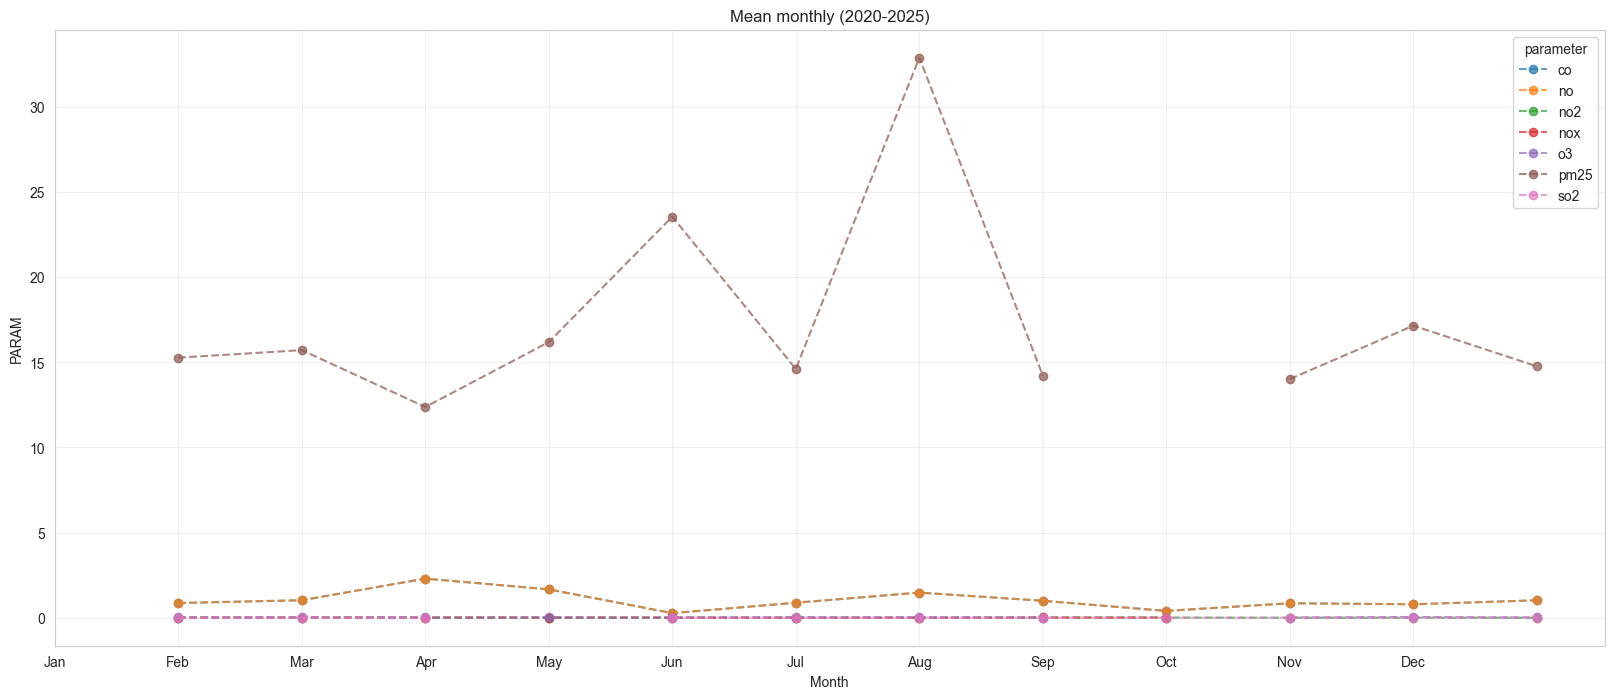

In [470]:
Dft.groupby([Dft["datetime"].dt.month,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='o', linestyle='--', alpha = 0.7)
plt.xticks([0,1,2,3,4,5,6,7,8,9,10,11],['Jan','Feb','Mar','Apr','May','Jun','Jul', 'Aug','Sep','Oct','Nov','Dec'])
plt.ylabel('PARAM')
plt.xlabel('Month')
plt.title('Mean monthly (2020-2025)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/mthly_20_25.jpeg", dpi = 1200)
plt.show()

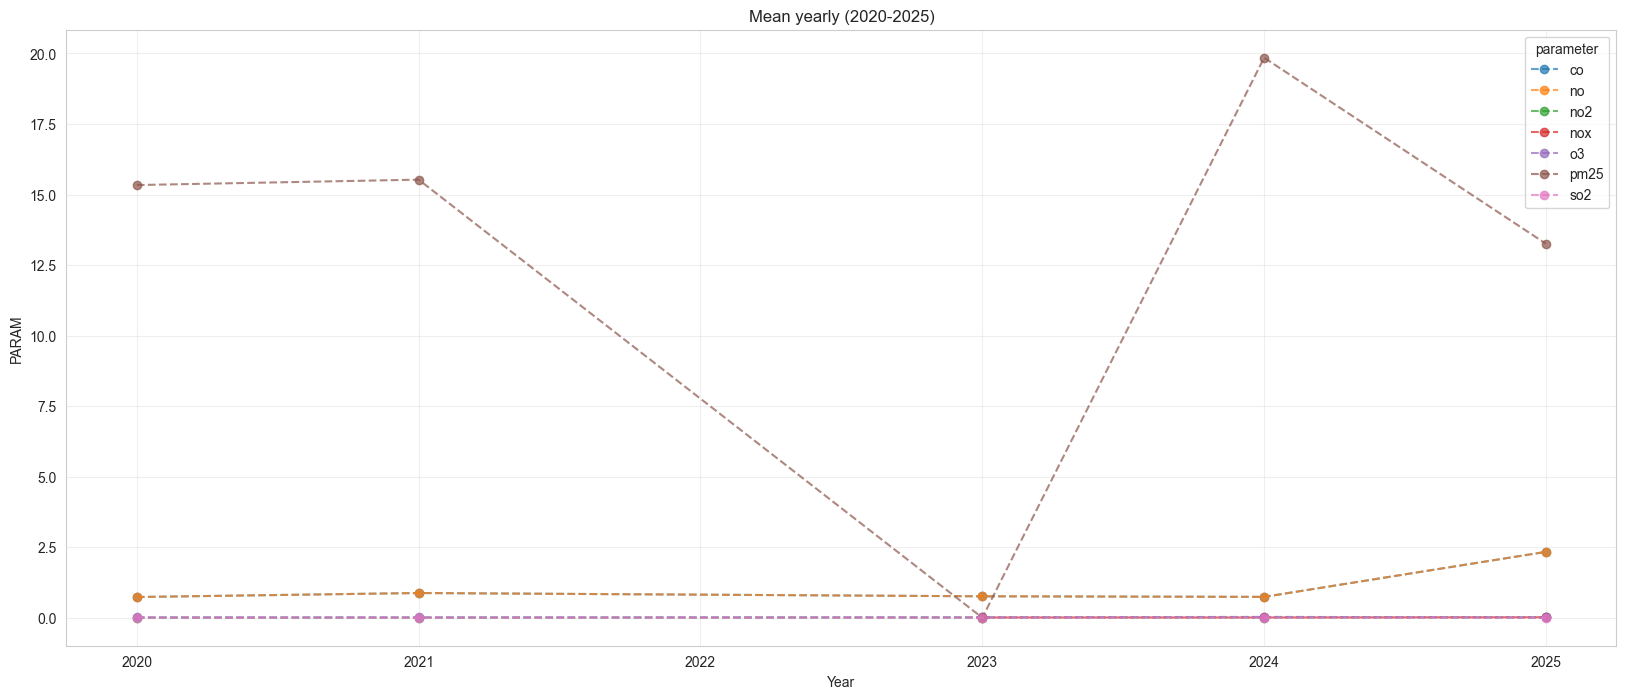

In [471]:
Dft.groupby([Dft["datetime"].dt.year,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='o', linestyle='--', alpha = 0.7)
plt.ylabel('PARAM')
plt.xlabel('Year')
plt.title('Mean yearly (2020-2025)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/yrly_20_25.jpeg", dpi = 1200)
plt.show()

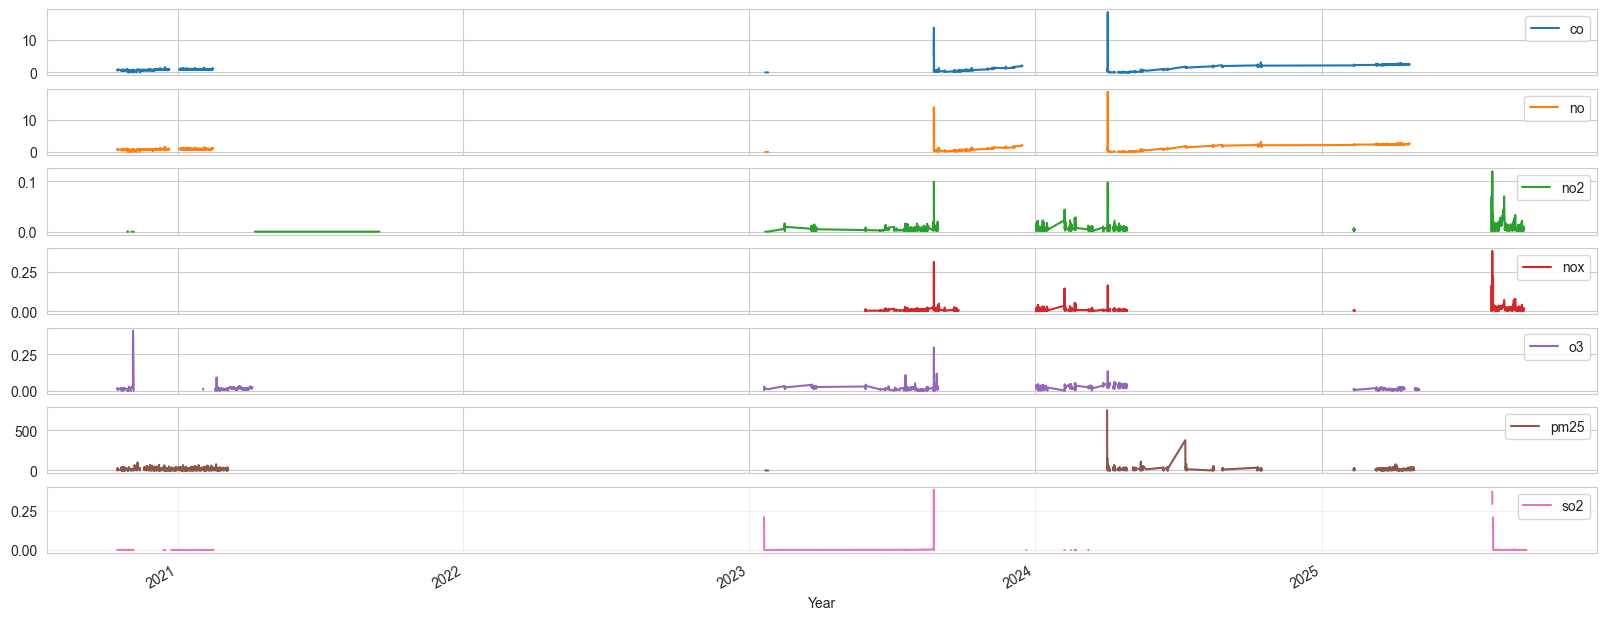

In [472]:
sns.set_style('whitegrid')
pd.pivot_table(Dft.reset_index(),
               index='datetime', columns='parameter', values='value'
              ).plot(figsize=(20, 8),subplots=True)
plt.xlabel('Year')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/data_20_25.jpeg", dpi = 1200)
plt.show()

#### Correlations

In [473]:
corhr = hr.corr()
corwk = wk.corr()
cormt = mt.corr()
coryr = yr.corr()

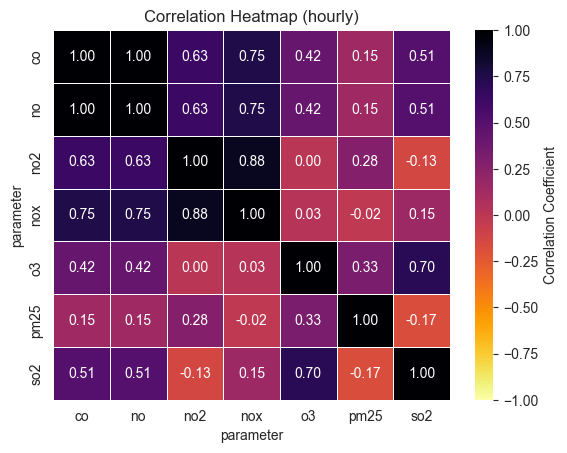

In [474]:
sns.heatmap(
    corhr, 
    annot=True, 
    fmt=".2f",  # Format for annotations:- decimal places
    cmap="inferno_r",  # Custom color map
    linewidths=0.5,  # separation of blocks
    vmin = -1,
    vmax = 1,
    cbar_kws={'label': 'Correlation Coefficient'}  # Customize color bar
)
plt.title('Correlation Heatmap (hourly)')
# plt.savefig("C:/Users/HP/Documents/src_paper/corr_hrly_20_25.jpeg", dpi = 1200)
plt.show()

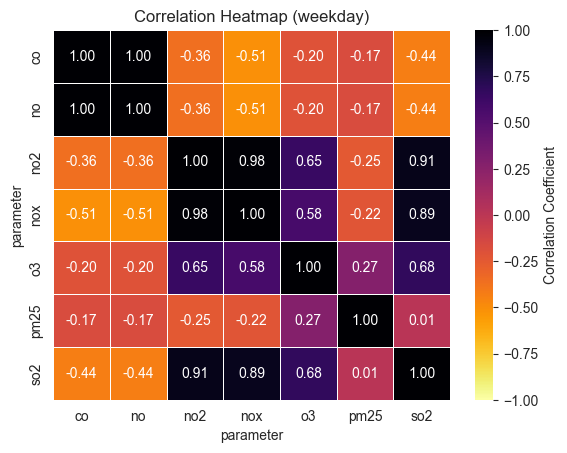

In [475]:
sns.heatmap(
    corwk, 
    annot=True, 
    fmt=".2f",  # Format for annotations:- decimal places
    cmap="inferno_r",  # Custom color map
    linewidths=0.5,  # separation of blocks
    vmin = -1,
    vmax = 1,
    cbar_kws={'label': 'Correlation Coefficient'}  # Customize color bar
)
plt.title('Correlation Heatmap (weekday)')
# plt.savefig("C:/Users/HP/Documents/src_paper/corr_week_20_25.jpeg", dpi = 1200)
plt.show()

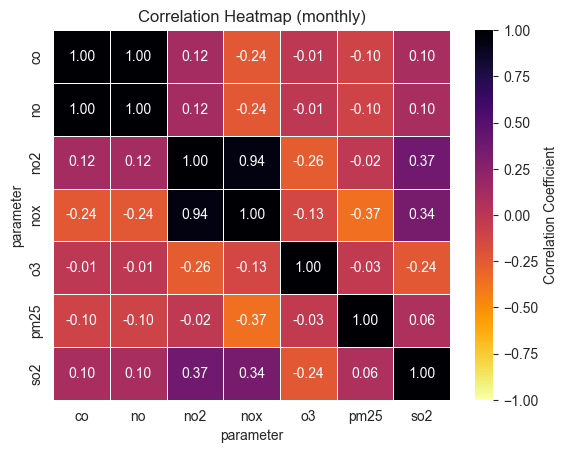

In [476]:
sns.heatmap(
    cormt, 
    annot=True, 
    fmt=".2f",  # Format for annotations:- decimal places
    cmap="inferno_r",  # Custom color map
    linewidths=0.5,  # separation of blocks
    vmin = -1,
    vmax = 1,
    cbar_kws={'label': 'Correlation Coefficient'}  # Customize color bar
)
plt.title('Correlation Heatmap (monthly)')
# plt.savefig("C:/Users/HP/Documents/src_paper/corr_mthly_20_25.jpeg", dpi = 1200)
plt.show()

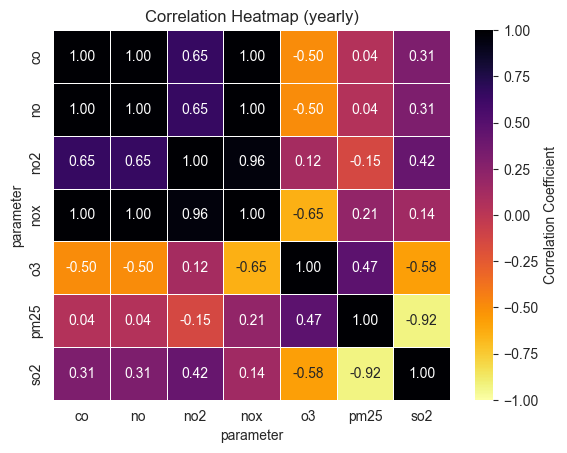

In [477]:
sns.heatmap(
    coryr, 
    annot=True, 
    fmt=".2f",  # Format for annotations:- decimal places
    cmap="inferno_r",  # Custom color map
    linewidths=0.5,  # separation of blocks
    vmin = -1,
    vmax = 1,
    cbar_kws={'label': 'Correlation Coefficient'}  # Customize color bar
)
plt.title('Correlation Heatmap (yearly)')
# plt.savefig("C:/Users/HP/Documents/src_paper/corr_yrly_20_25.jpeg", dpi = 1200)
plt.show()

## Data exploration - Normal data tests

In [138]:
Dft.head(3)

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2020-10-15 23:00:00+00:00,0.699910,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2020-10-16 00:00:00+00:00,0.676767,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2020-10-16 01:00:00+00:00,0.604288,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111


In [362]:
m = Dft.loc[Dft['parameter'] == "co"]
v = Dft.loc[Dft['parameter'] == "o3"]
j = Dft.loc[Dft['parameter'] == "pm25"]
k = Dft.loc[Dft['parameter'] == "no"]
b = Dft.loc[Dft['parameter'] == "nox"]
r = Dft.loc[Dft['parameter'] == "no2"]
t = Dft.loc[Dft['parameter'] == "so2"]
m.head(2)

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2020-10-15 23:00:00+00:00,0.699910,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2020-10-16 00:00:00+00:00,0.676767,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111


In [363]:
xm = m.iloc[:, 1]
xv = v.iloc[:, 1]
xj = j.iloc[:, 1]
xk = k.iloc[:, 1]
xb = b.iloc[:, 1]
xr = r.iloc[:, 1]
xt = t.iloc[:, 1]
xm=xm.iloc[0:4202]
xv=xv.iloc[0:4202]
xj=xj.iloc[0:4202]
xk=xk.iloc[0:4202]
xb=xb.iloc[0:4202]
xr=xr.iloc[0:4202]
xt=xt.iloc[0:4202]

xm.to_frame(name='co')

,co
0,0.699910
1,0.676767
2,0.604288
3,0.641566
4,0.582559
...,...
617,2.417847
618,2.421402
619,2.379005
620,2.390252


In [364]:
xv.to_frame(name='o3')

,o3
0,0.017244
1,0.016878
2,0.017936
3,0.016795
4,0.016029
...,...
995,0.008737
996,0.007734
997,0.006990
998,0.005897


In [481]:
my = pd.concat([xm, xv],axis=0)
my

0      0.699910
1      0.676767
2      0.604288
3      0.641566
4      0.582559
         ...   
995    0.008737
996    0.007734
997    0.006990
998    0.005897
999    0.006121
Name: value, Length: 8404, dtype: float64

In [96]:
np.min(xm),np.max(xm), np.min(xv),np.max(xv)

(0.0, 18.5582903, 0.0, 0.410466194)

QQ plot options: <br>
"45"	Draws a 45-degree line through the origin (y = x). <br>
"s"	Standardized line — expected order statistics are scaled by the sample's standard deviation and shifted by its mean. <br>
"r"	Regression line — fits a least-squares regression line to the Q-Q plot points. <br>
"q"	Quartile line — line through the first and third quartiles of the data and theoretical distribution. <br>
None	No reference line is drawn.

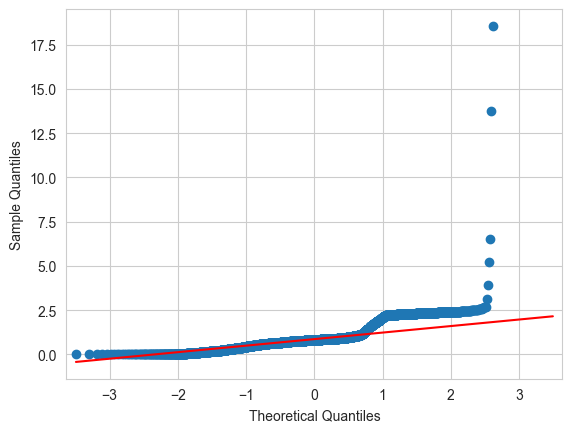

In [102]:
qqplot_data= qqplot(xm, line='q').gca().lines

(array([5.730e+02, 9.980e+02, 1.579e+03, 1.630e+02, 1.320e+02, 1.950e+02,
        5.330e+02, 5.000e+00, 1.000e+00, 0.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 1.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([ 0.        ,  0.37116581,  0.74233161,  1.11349742,  1.48466322,
         1.85582903,  2.22699484,  2.59816064,  2.96932645,  3.34049225,
         3.71165806,  4.08282387,  4.45398967,  4.82515548,  5.19632128,
         5.56748709,  5.9386529 ,  6.3098187 ,  6.68098451,  7.05215031,
         7.42331612,  7.79448193,  8.16564773,  8.53681354,  8.90797934,
         9.

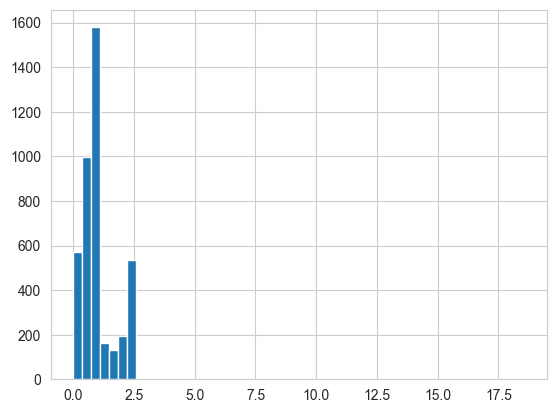

In [98]:
plt.hist(xm,bins = 50)

In [149]:
stat, p = normaltest(xm)

# interpret
alpha = 0.05
if p > alpha:
    msg = 'Sample looks Gaussian (fail to reject H0)'
else:
    msg = 'Sample does not look Gaussian (reject H0)'

result_mat = [
    ['Length of the sample data', 'Test Statistic', 'p-value', 'Comments'],
    [len(xm), stat, p, msg]
]


In [150]:
print(result_mat)

[['Length of the sample data', 'Test Statistic', 'p-value', 'Comments'], [4202, np.float64(nan), np.float64(nan), 'Sample does not look Gaussian (reject H0)']]


## Geostatistics

#### Geostats - Using mean values to look at trends within confidence intervals

In [398]:
data = Dft.groupby([Dft["datetime"].dt.weekday,'parameter'])["value"].mean().unstack()
data.head()

parameter,co,no,no2,nox,o3,pm25,so2
datetime,,,,,,,
0,1.136769,1.136769,0.005233,0.008637,0.017333,18.899944,0.000871
1,1.216103,1.216103,0.006507,0.010235,0.019493,15.228809,0.001002
2,1.045661,1.045661,0.007499,0.013481,0.019684,16.389522,0.002160
3,1.098397,1.098397,0.008329,0.014161,0.019899,15.349763,0.003665
4,1.084169,1.084169,0.006423,0.010932,0.016905,14.820579,0.001000


In [92]:
data1 = Dft.groupby([Dft["datetime"].dt.month,'parameter'])["value"].mean().unstack()
data1.head()

parameter,co,no,no2,nox,o3,pm25,so2
datetime,,,,,,,
1,0.865754,0.865754,0.006083,0.009352,0.019705,15.276013,0.000682
2,1.026894,1.026894,0.007544,0.011827,0.020243,15.719337,0.000536
3,2.299269,2.299269,0.004687,0.007012,0.017209,12.378687,0.001054
4,1.664785,1.664785,0.005793,0.007319,0.023685,16.190484,NaN
5,0.270076,0.270076,0.003422,0.005063,0.013562,23.560133,0.001112


In [93]:
data2 = Dft.groupby([Dft["datetime"].dt.year,'parameter'])["value"].mean().unstack()
data2.head()

parameter,co,no,no2,nox,o3,pm25,so2
datetime,,,,,,,
2020,0.733742,0.733742,0.000000,NaN,0.015447,15.335310,0.000847
2021,0.875706,0.875706,0.000000,NaN,0.016336,15.526084,0.000437
2023,0.759154,0.759154,0.005203,0.008804,0.015808,0.000000,0.002799
2024,0.739144,0.739144,0.006354,0.008979,0.029100,19.848089,0.000185
2025,2.334948,2.334948,0.008961,0.016378,0.012276,13.254087,0.001857


In [399]:
m = data['co']
v = data['o3']
p = data['nox']
r = data['so2']
s = data['pm25']
m

datetime
0    1.136769
1    1.216103
2    1.045661
3    1.098397
4    1.084169
5    1.166915
6    1.116418
Name: co, dtype: float64

In [140]:
np.size(m),np.size(v)

(7, 7)

"45"	Draws a 45-degree line through the origin. Useful for comparing to a standard normal distribution without shifting or scaling.
"s"	Standardized line — expected order statistics are scaled by the sample’s standard deviation and shifted by its mean.
"r"	Regression line — fits a least-squares regression line through the points.
"q"	Quartile line — line through the first and third quartiles of the sample and theoretical quantiles.

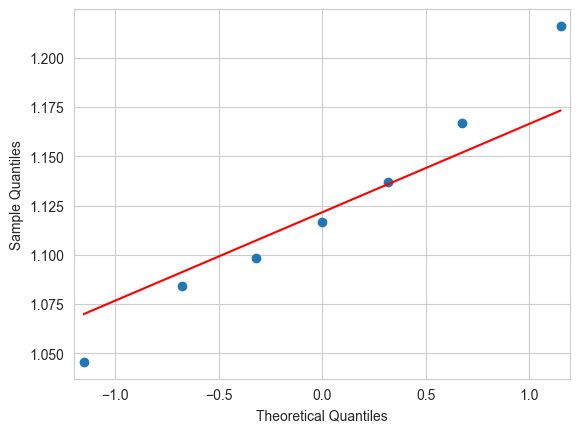

In [486]:
qqplot_data= qqplot(m, line='q').gca().lines

In [487]:
m = data['co']
v = data['o3']
p = data['no']
b = data['no2']
q = data['nox']
r = data['so2']
t = data['pm25']

Line equation: y = 1.6892 * x + 15.6273


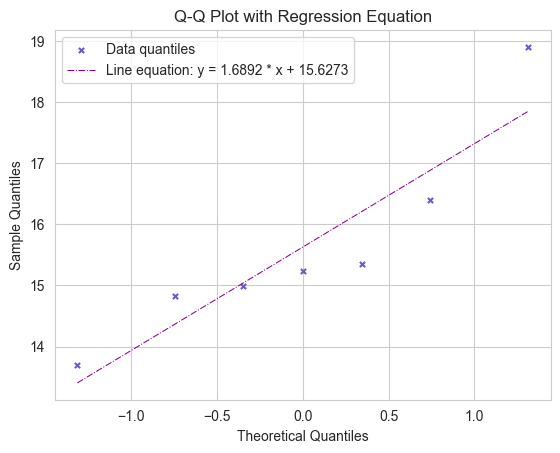

In [494]:
quantiles, values = scipy.stats.probplot(t, dist="norm")

# Extract x (theoretical quantiles) and y (sample quantiles)
x = quantiles[0]
y = quantiles[1]

# Fit a line: y = slope * x + intercept
slope, intercept = np.polyfit(x, y, 1)

print(f"Line equation: y = {slope:.4f} * x + {intercept:.4f}")

# Plot Q-Q plot
plt.scatter(x, y, label="Data quantiles", color="slateblue", marker = "x", s = 14)
plt.plot(x, slope * x + intercept, color="darkmagenta", linestyle = "dashdot", linewidth = 0.75, label = f"Line equation: y = {slope:.4f} * x + {intercept:.4f}")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.title("Q-Q Plot with Regression Equation")
plt.legend()
plt.grid(True)
# plt.savefig("C:/Users/HP/Documents/src_paper/PM25_normfit.jpeg", dpi = 1200)
plt.show()


(array([1., 0., 1., 1., 1., 1., 0., 1., 0., 1.]),
 array([1.04566142, 1.06270561, 1.0797498 , 1.09679399, 1.11383818,
        1.13088236, 1.14792655, 1.16497074, 1.18201493, 1.19905912,
        1.21610331]),
 <BarContainer object of 10 artists>)

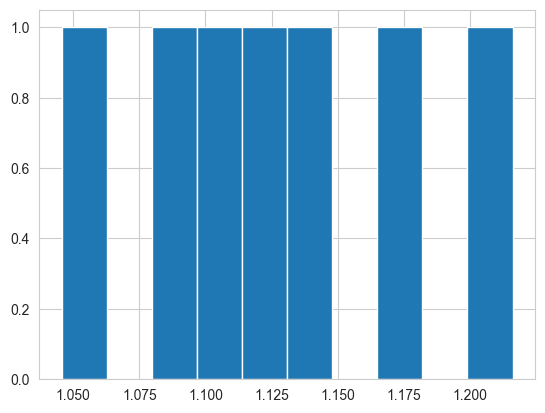

In [173]:
plt.hist(m,bins = 10)

Parameters [3.89821207e+00 1.85582903e+01 1.77204380e-02]
RMSE: 0.016513265021892588
R-squared: -0.30393365645811676


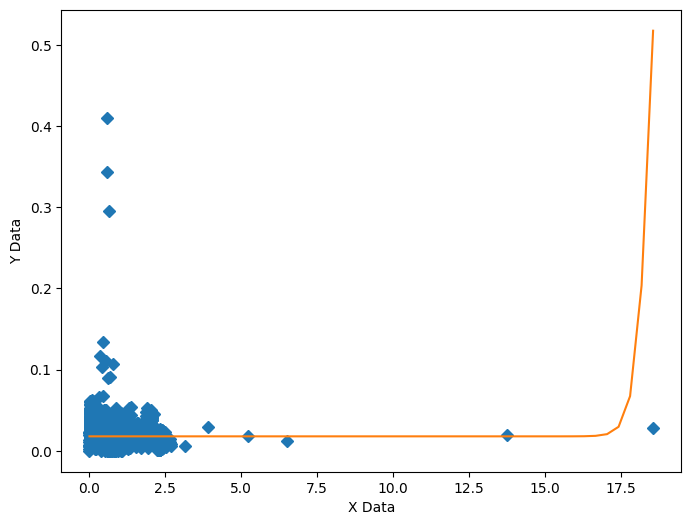

In [112]:
# Source - https://stackoverflow.com/a/51975675
# Posted by James Phillips, modified by community. See post 'Timeline' for change history
# Retrieved 2026-05-26, License - CC BY-SA 4.0

xData = xm
yData = xv


def func(x, a, b, Offset): # Sigmoid A With Offset from zunzun.com
    return  1.0 / (1.0 + np.exp(-a * (x-b))) + Offset


# function for genetic algorithm to minimize (sum of squared error)
def sumOfSquaredError(parameterTuple):
    warnings.filterwarnings("ignore") # do not print warnings by genetic algorithm
    val = func(xData, *parameterTuple)
    return np.sum((yData - val) ** 2.0)


def generate_Initial_Parameters():
    # min and max used for bounds
    maxX = max(xData)
    minX = min(xData)
    maxY = max(yData)
    minY = min(yData)

    parameterBounds = []
    parameterBounds.append([minX, maxX]) # search bounds for a
    parameterBounds.append([minX, maxX]) # search bounds for b
    parameterBounds.append([0.0, maxY]) # search bounds for Offset

    # "seed" the np random number generator for repeatable results
    result = differential_evolution(sumOfSquaredError, parameterBounds, seed=3)
    return result.x

# generate initial parameter values
geneticParameters = generate_Initial_Parameters()

# curve fit the test data
fittedParameters, pcov = curve_fit(func, xData, yData, geneticParameters)

print('Parameters', fittedParameters)

modelPredictions = func(xData, *fittedParameters) 

absError = modelPredictions - yData

SE = np.square(absError) # squared errors
MSE = np.mean(SE) # mean squared errors
RMSE = np.sqrt(MSE) # Root Mean Squared Error, RMSE
Rsquared = 1.0 - (np.var(absError) / np.var(yData))
print('RMSE:', RMSE)
print('R-squared:', Rsquared)


##########################################################
# graphics output section
def ModelAndScatterPlot(graphWidth, graphHeight):
    f = plt.figure(figsize=(graphWidth/100.0, graphHeight/100.0), dpi=100)
    axes = f.add_subplot(111)

    # first the raw data as a scatter plot
    axes.plot(xData, yData,  'D')

    # create data for the fitted equation plot
    xModel = np.linspace(min(xData), max(xData))
    yModel = func(xModel, *fittedParameters)

    # now the model as a line plot 
    axes.plot(xModel, yModel)

    axes.set_xlabel('X Data') # X axis data label
    axes.set_ylabel('Y Data') # Y axis data label

    plt.show()
    plt.close('all') # clean up after using pyplot

graphWidth = 800
graphHeight = 600
ModelAndScatterPlot(graphWidth, graphHeight)


Polynomial degree 5:
  Coefficients: [ -4755.9560024   27004.04826718 -61282.1915153   69480.73645877
 -39356.80640524   8910.29910693]
  Equation:        5           4             3             2
-4756 x + 2.7e+04 x - 6.128e+04 x + 6.948e+04 x - 3.936e+04 x + 8910
  R²: 0.779121
  Adjusted R²: -0.325271
  RMSE: 0.0020


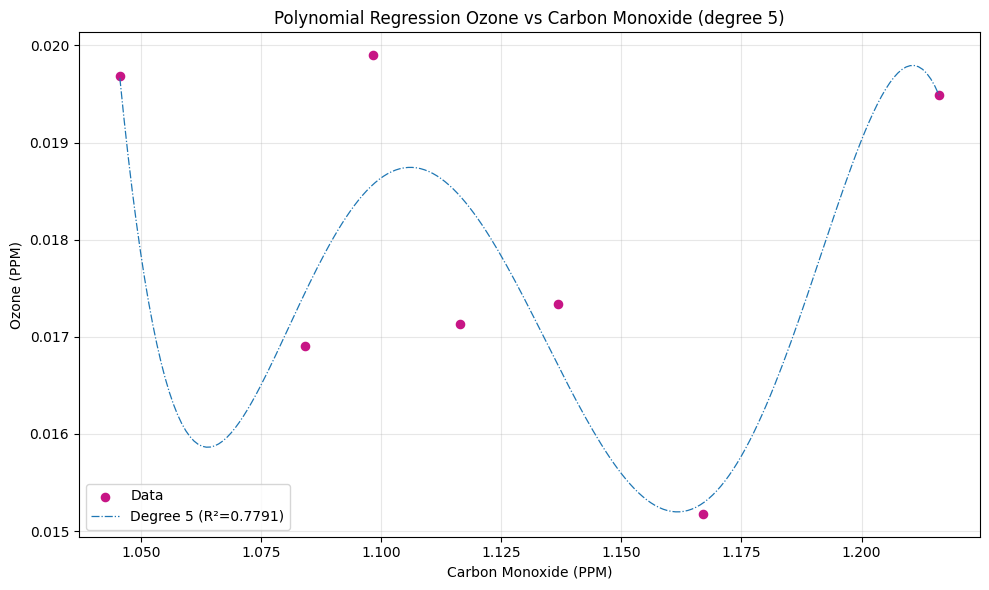

In [408]:
# -----------------------------
# 1. Data
# -----------------------------
x0 = m
y0 = v
x = x0
y = y0

# -----------------------------
# 2. Fit Polynomial of Chosen Degree
# -----------------------------
degree = 5 # Change this to test different polynomial degrees
coeffs = np.polyfit(x, y, degree)  # Fit polynomial
poly_fn = np.poly1d(coeffs)        # Create polynomial function

# -----------------------------
# 3. Predictions & RMSE
# -----------------------------
y_pred = poly_fn(x)
ss_res = np.sum((y - y_pred) ** 2)  # Residual sum of squares
n = len(x)
p = degree + 1  # Number of parameters
rmse = np.sqrt(ss_res / (n - p))    # RMSE with degrees of freedom correction

# -----------------------------
# 4. R² and Adjusted R²
# -----------------------------
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - ss_res / ss_tot
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p)

# -----------------------------
# 5. Output Results
# -----------------------------
print(f"Polynomial degree {degree}:")
print(f"  Coefficients: {coeffs}")
print(f"  Equation: {poly_fn}")
print(f"  R²: {r2:.6f}")
print(f"  Adjusted R²: {adj_r2:.6f}")
print(f"  RMSE: {rmse:.4f}")


# -----------------------------
# 6. Plot
# -----------------------------
x_smooth = np.linspace(x.min(), x.max(), 200)
plt.figure(figsize=(10, 6))
plt.scatter(x, y, color='mediumvioletred', s=35, label='Data')
plt.plot(x_smooth, poly_fn(x_smooth), '-.', lw=0.9,
         label=f'Degree {degree} (R²={r2:.4f})')
plt.xlabel('Carbon Monoxide (PPM)')
plt.ylabel('Ozone (PPM)')
plt.title(f'Polynomial Regression Ozone vs Carbon Monoxide (degree {degree})')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
# plt.savefig("C:/Users/HP/Documents/src_paper/COvsO3_poly_regress.jpeg", dpi = 1200)
plt.show()

#### Stepwise regression - Weekday

In [498]:
y = v
x = m

In [499]:
def calculate_linear_regression_coef(x,y):
    if(np.size(x) != np.size(y)):
        sys.exit("Two vectors of different lengths")

    n = np.size(x)
    sx = np.sum(x)
    sy = np.sum(y)

    sx2 = np.inner(x,x)
    sxy = np.inner(x,y)
    sy2 = np.inner(y,y)

    a1 = (n*sxy-sx*sy)/(n*sx2-sx**2)
    a0 = sy/n - a1*sx/n
    r2 = ((n*sxy-sx*sy)/np.sqrt(n*sx2-sx**2)/np.sqrt(n*sy2-sy**2))**2;
    return(a0,a1,r2)

In [500]:
a0,a1,r2 = calculate_linear_regression_coef(x,y)
a0, a1, r2

(np.float64(0.025228317391094924),
 np.float64(-0.006481465826410643),
 np.float64(0.041807735744873245))

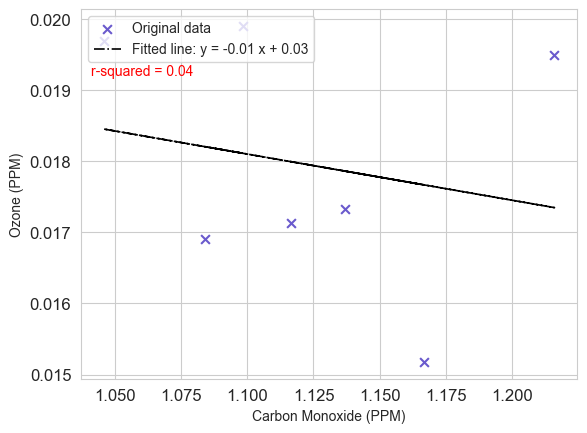

In [502]:
sns.set_style("whitegrid")
plt.scatter(x,y, c="slateblue", marker="x", s = 40, label="Original data")
ypred = a0 + a1*x
plt.plot(x, ypred, c="k", linestyle='dashdot', linewidth = 1.2, label='Fitted line: y = %.2f x + %.2f' % (a1, a0))
plt.text(0.02, 0.85, 'r-squared = %.2f'%r2, transform=plt.gca().transAxes,
         fontsize=10, color='red', va='top')
plt.xlabel('Carbon Monoxide (PPM)')
plt.ylabel('Ozone (PPM)')
plt.tick_params(axis='both', which='major',labelsize=12)
plt.legend(loc= 'upper left', fontsize=10, frameon=True)
# plt.savefig("C:/Users/HP/Documents/src_paper/O3vsCO_lin_regress.jpeg", dpi = 1200)
plt.show()

In [ ]:
X= pd.concat([m,p,r,s], axis = 1)
X
y = v

In [247]:
model=LinearRegression()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model.fit(X_train, y_train)

# -----------------------------
# 5. Make predictions
# -----------------------------
y_pred = model.predict(X_test)

print("Coefficients:", model.coef_)       # Slopes for each feature
print("Intercept:", model.intercept_)     # y-intercept
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))  # 1.0 = perfect fit

Coefficients: [-3.31207058e-03 -2.78108543e-01  1.23381245e+00  1.22945754e-03]
Intercept: 0.004081947589601068
Mean Squared Error: 1.467854954535343e-05
R² Score: -11.581786989210576


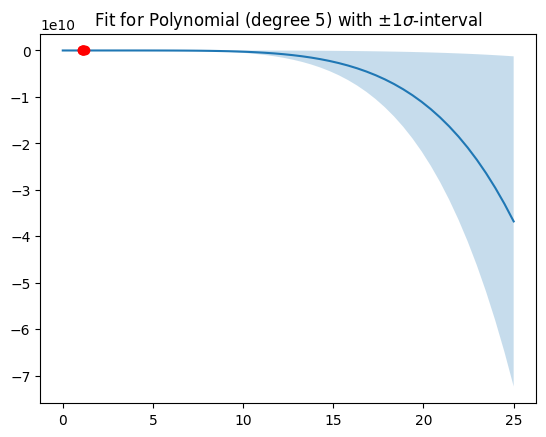

[ 0.          0.51020408  1.02040816  1.53061224  2.04081633  2.55102041
  3.06122449  3.57142857  4.08163265  4.59183673  5.10204082  5.6122449
  6.12244898  6.63265306  7.14285714  7.65306122  8.16326531  8.67346939
  9.18367347  9.69387755 10.20408163 10.71428571 11.2244898  11.73469388
 12.24489796 12.75510204 13.26530612 13.7755102  14.28571429 14.79591837
 15.30612245 15.81632653 16.32653061 16.83673469 17.34693878 17.85714286
 18.36734694 18.87755102 19.3877551  19.89795918 20.40816327 20.91836735
 21.42857143 21.93877551 22.44897959 22.95918367 23.46938776 23.97959184
 24.48979592 25.        ]


In [403]:
# Source - https://stackoverflow.com/a/28528966
# Posted by Dietrich, modified by community. See post 'Timeline' for change history
# Retrieved 2026-05-26, License - CC BY-SA 3.0

# sample data:
x = m
y = v

n = 5 # degree of polynomial
p, C_p = np.polyfit(x, y, n, cov=True)  # C_z is estimated covariance matrix

# Do the interpolation for plotting:
t = np.linspace(0,25)
# Matrix with rows 1, t, t**2, ...:
TT = np.vstack([t**(n-i) for i in range(n+1)]).T
yi = np.dot(TT, p)  # matrix multiplication calculates the polynomial values
C_yi = np.dot(TT, np.dot(C_p, TT.T)) # C_y = TT*C_z*TT.T
sig_yi = np.sqrt(np.diag(C_yi))  # Standard deviations are sqrt of diagonal

# Do the plotting:
fg, ax = plt.subplots(1, 1)
ax.set_title("Fit for Polynomial (degree {}) with $\pm1\sigma$-interval".format(n))
ax.fill_between(t, yi+sig_yi, yi-sig_yi, alpha=.25)
ax.plot(t, yi,'-')
ax.plot(x, y, 'ro')
ax.axis('tight')

fg.canvas.draw()
plt.show()

print(t)


Regression Equation:
y = 0.008 + (0.004 * X1) + (0.536 * X2)
Intercept: 0.00772653348954673
Coefficients: [0.00383942 0.53604672]
R² Score: 0.34305393845058274
RMSE: 0.0013358208455092437


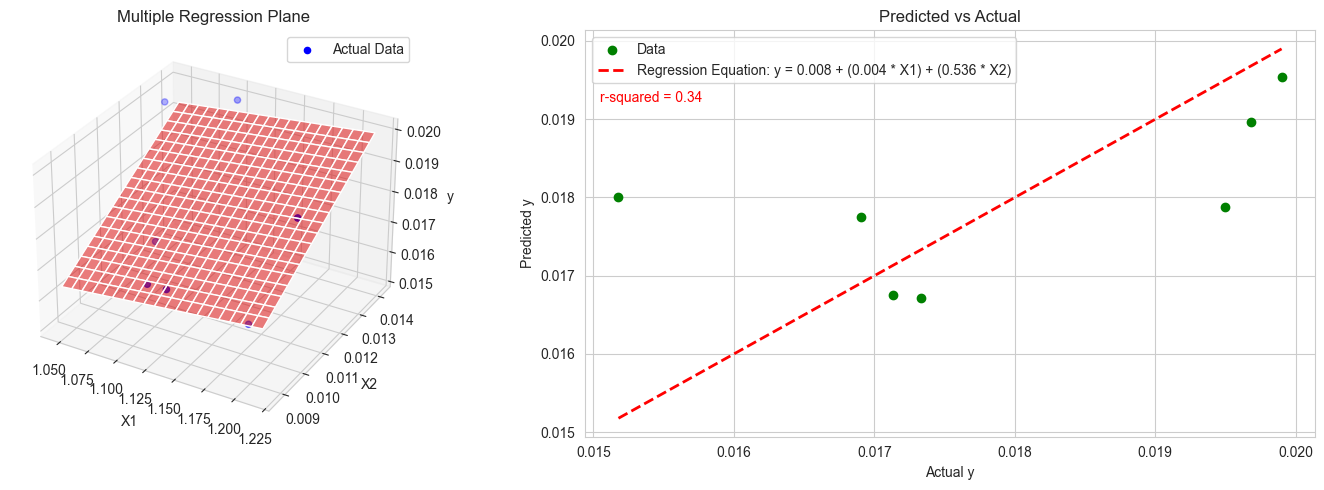

In [507]:
X1 = m
X2 = p
X3 = r 
X4 = s
y = v

# Combine features into a DataFrame
df = pd.DataFrame({'X1': X1, 'X2': X2, 'y': y})

# -----------------------------
# 2. Fit Multiple Linear Regression
# -----------------------------
X = df[['X1', 'X2']]
y = df['y']

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

equation = f"y = {model.intercept_:.3f}"
for i, col in enumerate(X.columns):
    equation += f" + ({model.coef_[i]:.3f} * {col})"

print("Regression Equation:")
print(equation)

# -----------------------------
# 3. Print model details
# -----------------------------
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)
print("R² Score:", r2_score(y, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y, y_pred)))

# -----------------------------
# 4. 3D Scatter + Regression Plane
# -----------------------------
fig = plt.figure(figsize=(15, 5))
ax = fig.add_subplot(121, projection='3d')

# Scatter plot of actual data
ax.scatter(X1, X2, y, color='blue', label='Actual Data')

# Create grid for regression plane
x1_range = np.linspace(X1.min(), X1.max(), 20)
x2_range = np.linspace(X2.min(), X2.max(), 20)
x1_grid, x2_grid = np.meshgrid(x1_range, x2_range)
y_grid = model.intercept_ + model.coef_[0] * x1_grid + model.coef_[1] * x2_grid

# Plot regression plane
ax.plot_surface(x1_grid, x2_grid, y_grid, alpha=0.5, color='red')

ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('y')
ax.set_title('Multiple Regression Plane')
ax.legend()

# -----------------------------
# 5. Predicted vs Actual Plot
# -----------------------------
ax2 = fig.add_subplot(122)
ax2.scatter(y, y_pred, color='green', label="Data")
ax2.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label="Regression Equation: {}".format(equation))
ax2.text(0.02, 0.85, 'r-squared = %.2f'%r2_score(y, y_pred), transform=plt.gca().transAxes,
         fontsize=10, color='red', va='top')
ax2.set_xlabel('Actual y')
ax2.set_ylabel('Predicted y')
ax2.set_title('Predicted vs Actual')

plt.legend()
plt.tight_layout()
# plt.savefig("C:/Users/HP/Documents/src_paper/COvNOXvSO2vPM25_mult_regress.jpeg", dpi = 1200)
plt.show()

In [508]:
m = data['co']
v = data['o3']
p = data['nox']
r = data['so2']
s = data['pm25']

Regression Equation:
y = 0.051 + (-0.028 * Carbon Monoxide) + (-0.430 * Nitric Oxide) + (1.620 * Sulphur Dioxide)
Coefficients: [-0.02765322 -0.43032892  1.61963738]
Intercept: 0.05054835052176794
R² Score: -11.411935206131544
RMSE: 0.0038053110067301256


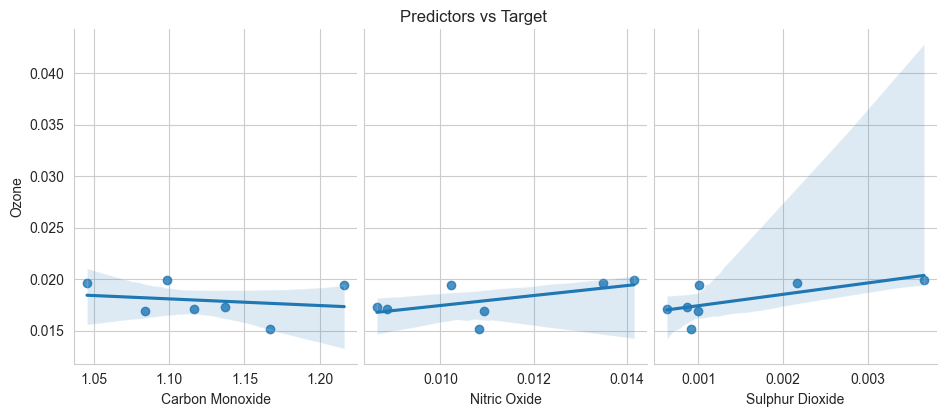

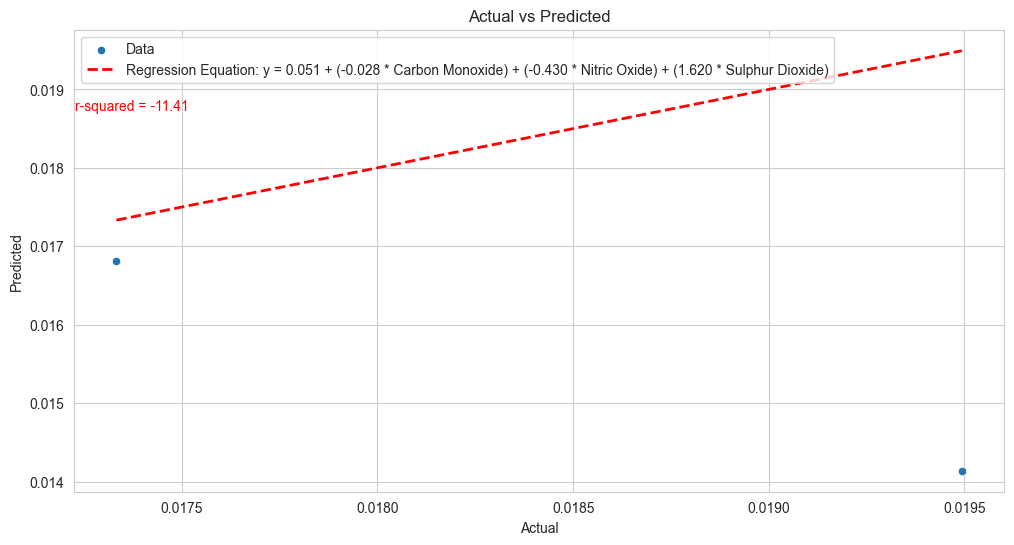

In [509]:

# Four predictors (X1, X2, X3)
X1 = m
X2 = p
X3 = r 

# Target variable with some noise
y = v

# Create DataFrame
df = pd.DataFrame({
    'Carbon Monoxide': X1,
    'Nitric Oxide': X2,
    'Sulphur Dioxide': X3,
    'Ozone': y
})

# -----------------------------
# 2. Train-test split
# -----------------------------
X = df[['Carbon Monoxide', 'Nitric Oxide', 'Sulphur Dioxide']]
y = df['Ozone']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# -----------------------------
# 3. Fit multiple regression model
# -----------------------------
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

equation = f"y = {model.intercept_:.3f}"
for i, col in enumerate(X.columns):
    equation += f" + ({model.coef_[i]:.3f} * {col})"

print("Regression Equation:")
print(equation)

# -----------------------------
# 4. Model evaluation
# -----------------------------
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# -----------------------------
# 5. Visualization
# -----------------------------

# (a) Pairplot to see relationships
sns.pairplot(df, x_vars=['Carbon Monoxide', 'Nitric Oxide', 'Sulphur Dioxide'], y_vars='Ozone', height=4, aspect=0.8, kind='reg')
plt.suptitle("Predictors vs Target", y=1.02)
plt.show()

# (b) Actual vs Predicted plot
plt.figure(figsize=(12, 6))
sns.scatterplot(x=y_test, y=y_pred, label="Data")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Regression Equation: {}".format(equation))
plt.text(0.001, 0.85, 'r-squared = %.2f'%r2_score(y_test, y_pred), transform=plt.gca().transAxes,
         fontsize=10, color='red', va='top')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.legend(loc = "upper left")
# plt.savefig("C:/Users/HP/Documents/src_paper/COvNOXvSO2_stepwise_regress.jpeg", dpi = 1200)
plt.show()

# (c) Residual plot
# residuals = y_test - y_pred
# plt.figure(figsize=(6, 4))
# sns.scatterplot(x=y_pred, y=residuals)
# plt.axhline(0, color='red', linestyle='--')
# plt.xlabel("Predicted")
# plt.ylabel("Residuals")
# plt.title("Residual Plot")

Regression Equation:
y = 0.004 + (-0.003 * Carbon Monoxide) + (-0.278 * Nitric Oxide) + (1.234 * Sulphur Dioxide) + (0.001 * PM2.5)
Coefficients: [-3.31207058e-03 -2.78108543e-01  1.23381245e+00  1.22945754e-03]
Intercept: 0.004081947589601068
R² Score: -11.581786989210576
RMSE: 0.0038312595246672377


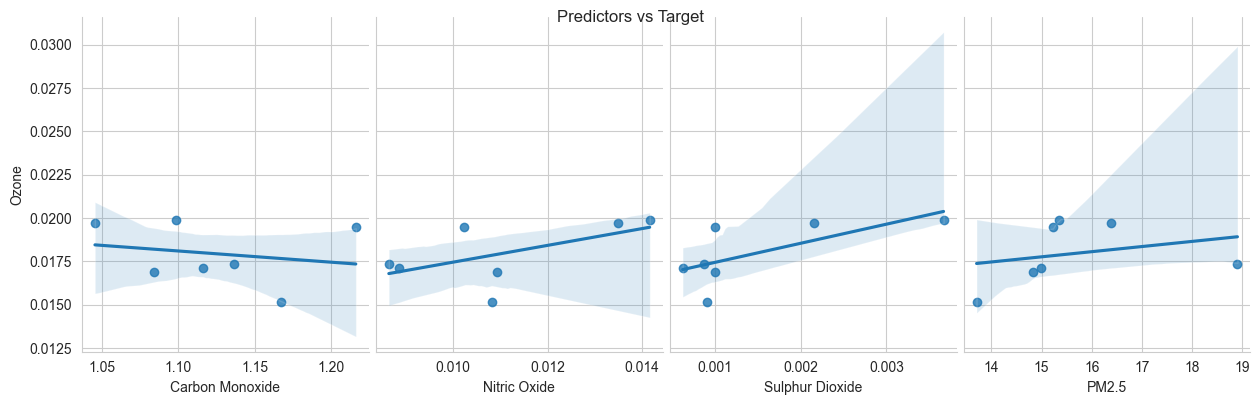

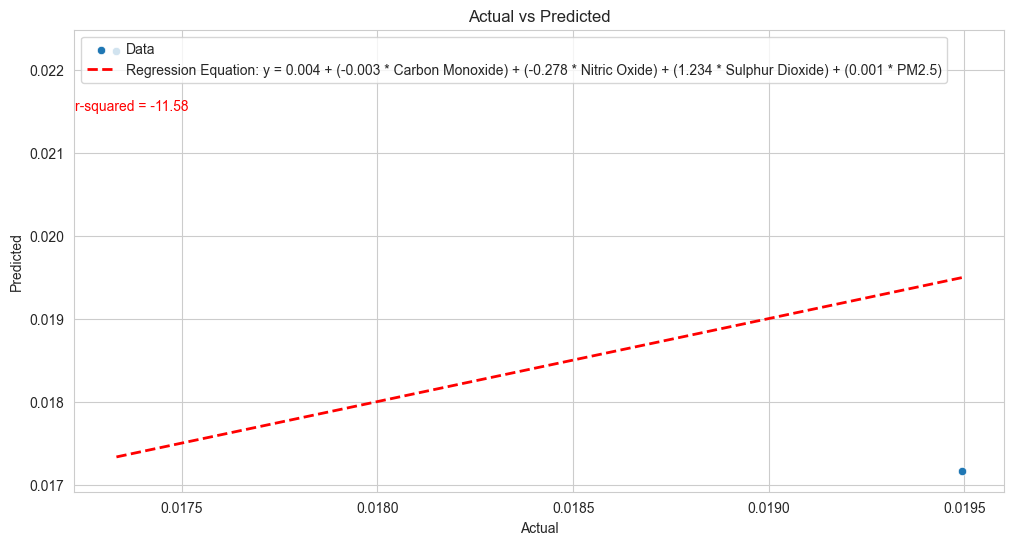

In [511]:

# Four predictors (X1, X2, X3, X4)
X1 = m
X2 = p
X3 = r 
X4 = s

# Target variable with some noise
y = v

# Create DataFrame
df = pd.DataFrame({
    'Carbon Monoxide': X1,
    'Nitric Oxide': X2,
    'Sulphur Dioxide': X3,
    'PM2.5': X4,
    'Ozone': y
})

# -----------------------------
# 2. Train-test split
# -----------------------------
X = df[['Carbon Monoxide', 'Nitric Oxide', 'Sulphur Dioxide', 'PM2.5']]
y = df['Ozone']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# -----------------------------
# 3. Fit multiple regression model
# -----------------------------
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

equation = f"y = {model.intercept_:.3f}"
for i, col in enumerate(X.columns):
    equation += f" + ({model.coef_[i]:.3f} * {col})"

print("Regression Equation:")
print(equation)

# -----------------------------
# 4. Model evaluation
# -----------------------------
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# -----------------------------
# 5. Visualization
# -----------------------------

# (a) Pairplot to see relationships
sns.pairplot(df, x_vars=['Carbon Monoxide', 'Nitric Oxide', 'Sulphur Dioxide', 'PM2.5'], y_vars='Ozone', height=4, aspect=0.8, kind='reg')
plt.suptitle("Predictors vs Target", y=0.99)
# plt.savefig("C:/Users/HP/Documents/src_paper/WEEKCOvNOXvSO2vPM25_PRED_TARGET.jpeg", dpi = 1200)
plt.show()

# (b) Actual vs Predicted plot
plt.figure(figsize=(12, 6))
sns.scatterplot(x=y_test, y=y_pred, label="Data")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Regression Equation: {}".format(equation))
plt.text(0.001, 0.85, 'r-squared = %.2f'%r2_score(y_test, y_pred), transform=plt.gca().transAxes,
         fontsize=10, color='red', va='top')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.legend(loc = "upper left")
# plt.savefig("C:/Users/HP/Documents/src_paper/WEEKCOvNOXvSO2vPM25_stepwise_regress.jpeg", dpi = 1200)
plt.show()

# (c) Residual plot
# residuals = y_test - y_pred
# plt.figure(figsize=(6, 4))
# sns.scatterplot(x=y_pred, y=residuals)
# plt.axhline(0, color='red', linestyle='--')
# plt.xlabel("Predicted")
# plt.ylabel("Residuals")
# plt.title("Residual Plot")
# plt.show()


### Stepwise regression - Monthly

In [273]:
m = data1['co']
v = data1['o3']
p = data1['nox']
r = data1['so2']
s = data1['pm25']
m

datetime
1     0.865754
2     1.026894
3     2.299269
4     1.664785
5     0.270076
6     0.880566
7     1.476538
8     0.995618
9     0.400265
10    0.849789
11    0.789439
12    1.023491
Name: co, dtype: float64

Regression Equation:
y = 0.018 + (0.004 * X1) + (-2.161 * X2) + (6.852 * X3) + (-0.000 * X4)
Coefficients: [ 3.61615155e-03 -2.16141193e+00  6.85197609e+00 -8.25261177e-05]
Intercept: 0.01785158294021812
R² Score: -4975.157500077468
RMSE: 0.01895972695420145


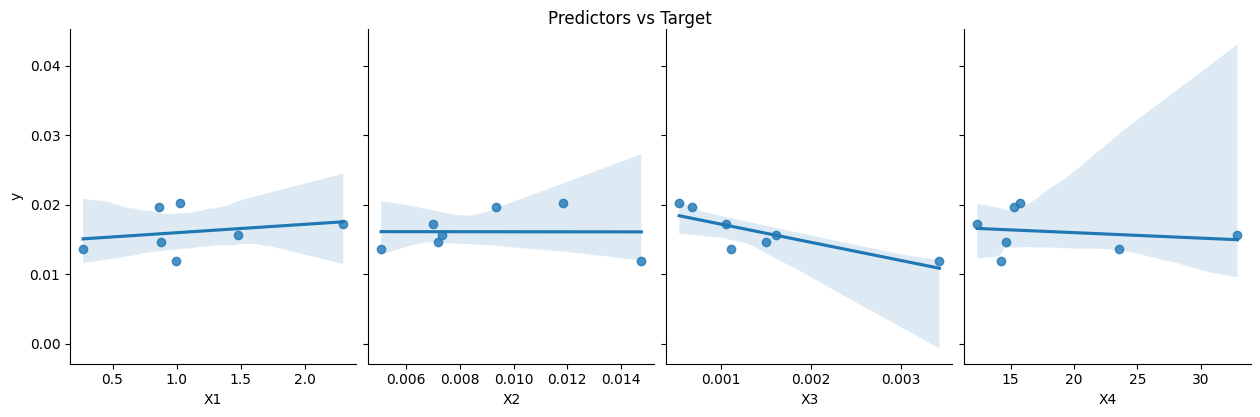

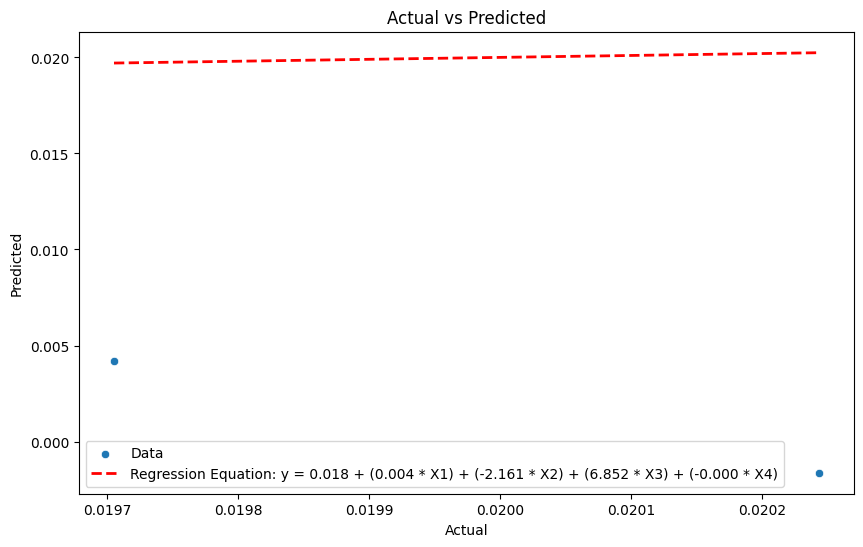

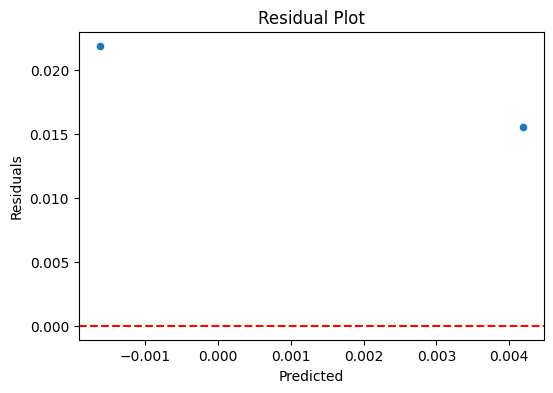

In [121]:
# Four predictors (X1, X2, X3, X4)
X1 = m
X2 = p
X3 = r 
X4 = s

# Target variable with some noise
y = v

# Create DataFrame
df = pd.DataFrame({
    'X1': X1,
    'X2': X2,
    'X3': X3,
    'X4': X4,
    'y': y
})

df = df.dropna(how='any')

# -----------------------------
# 2. Train-test split
# -----------------------------
X = df[['X1', 'X2', 'X3', 'X4']]
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# -----------------------------
# 3. Fit multiple regression model
# -----------------------------
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

equation = f"y = {model.intercept_:.3f}"
for i, col in enumerate(X.columns):
    equation += f" + ({model.coef_[i]:.3f} * {col})"

print("Regression Equation:")
print(equation)

# -----------------------------
# 4. Model evaluation
# -----------------------------
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# -----------------------------
# 5. Visualization
# -----------------------------

# (a) Pairplot to see relationships
sns.pairplot(df, x_vars=['X1', 'X2', 'X3', 'X4'], y_vars='y', height=4, aspect=0.8, kind='reg')
plt.suptitle("Predictors vs Target", y=1.02)
plt.show()

# (b) Actual vs Predicted plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, label="Data")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Regression Equation: {}".format(equation))
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

# (c) Residual plot
residuals = y_test - y_pred
plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


Regression Equation:
y = 0.015 + (0.002 * X1) + (-0.546 * X2) + (0.776 * X3)
Coefficients: [ 0.00229058 -0.54622373  0.77569614]
Intercept: 0.015022913816770097
R² Score: -915.3832663436752
RMSE: 0.008136237078334635


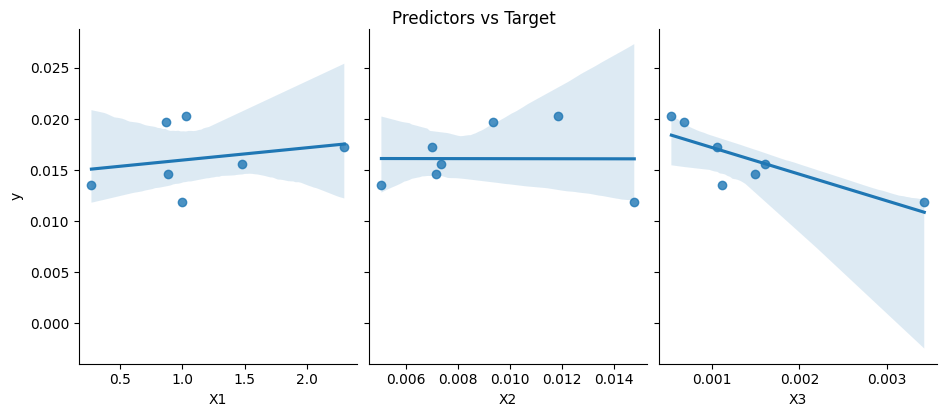

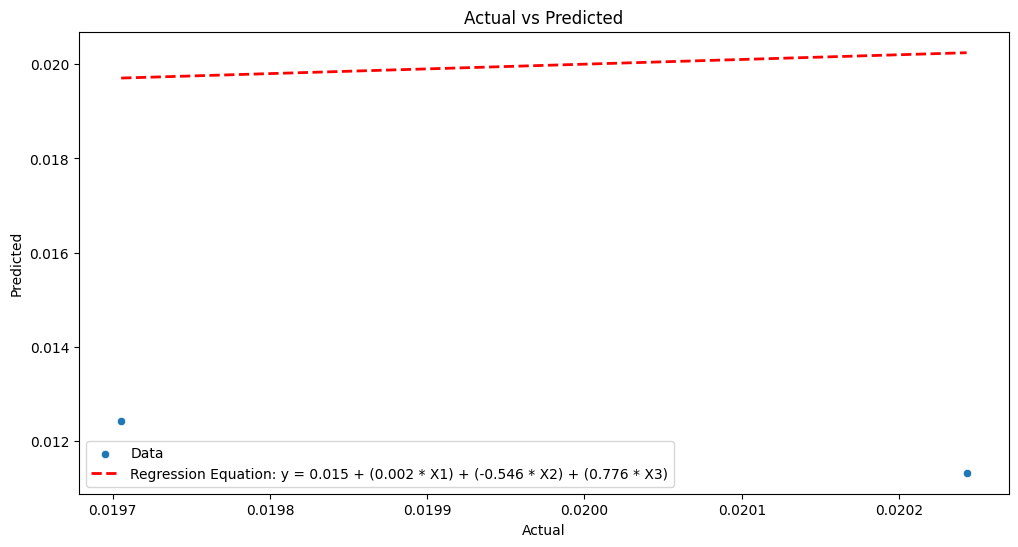

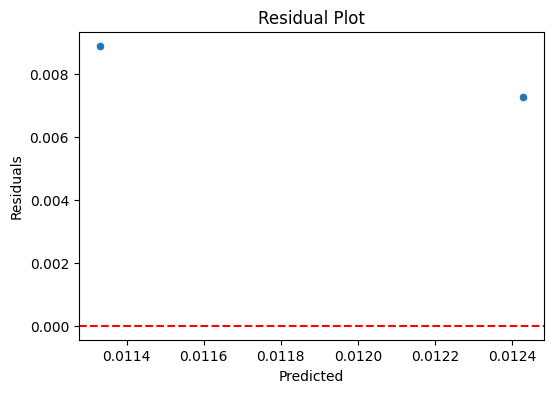

In [122]:
# Four predictors (X1, X2, X3)
X1 = m
X2 = p
X3 = r 

# Target variable with some noise
y = v

# Create DataFrame
df = pd.DataFrame({
    'X1': X1,
    'X2': X2,
    'X3': X3,
    'y': y
})

df = df.dropna(how='any')

# -----------------------------
# 2. Train-test split
# -----------------------------
X = df[['X1', 'X2', 'X3']]
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# -----------------------------
# 3. Fit multiple regression model
# -----------------------------
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

equation = f"y = {model.intercept_:.3f}"
for i, col in enumerate(X.columns):
    equation += f" + ({model.coef_[i]:.3f} * {col})"

print("Regression Equation:")
print(equation)

# -----------------------------
# 4. Model evaluation
# -----------------------------
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# -----------------------------
# 5. Visualization
# -----------------------------

# (a) Pairplot to see relationships
sns.pairplot(df, x_vars=['X1', 'X2', 'X3'], y_vars='y', height=4, aspect=0.8, kind='reg')
plt.suptitle("Predictors vs Target", y=1.02)
plt.show()

# (b) Actual vs Predicted plot
plt.figure(figsize=(12, 6))
sns.scatterplot(x=y_test, y=y_pred, label="Data")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Regression Equation: {}".format(equation))
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

# (c) Residual plot
residuals = y_test - y_pred
plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

### Stepwise regression - Yearly

In [114]:
m = data2['co']
v = data2['o3']
p = data2['nox']
r = data2['so2']
s = data2['pm25']
m

datetime
2020    0.733742
2021    0.875706
2023    0.759154
2024    0.739144
2025    2.334948
Name: co, dtype: float64

Regression Equation:
y = -0.018 + (-0.001 * X1) + (-0.000 * X2) + (-0.000 * X3) + (0.002 * X4)
Coefficients: [-5.83307796e-04 -2.70457913e-06 -6.10971571e-07  2.41027848e-03]
Intercept: -0.018307843346569187
R² Score: nan
RMSE: 0.03455854472101402


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:1288: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


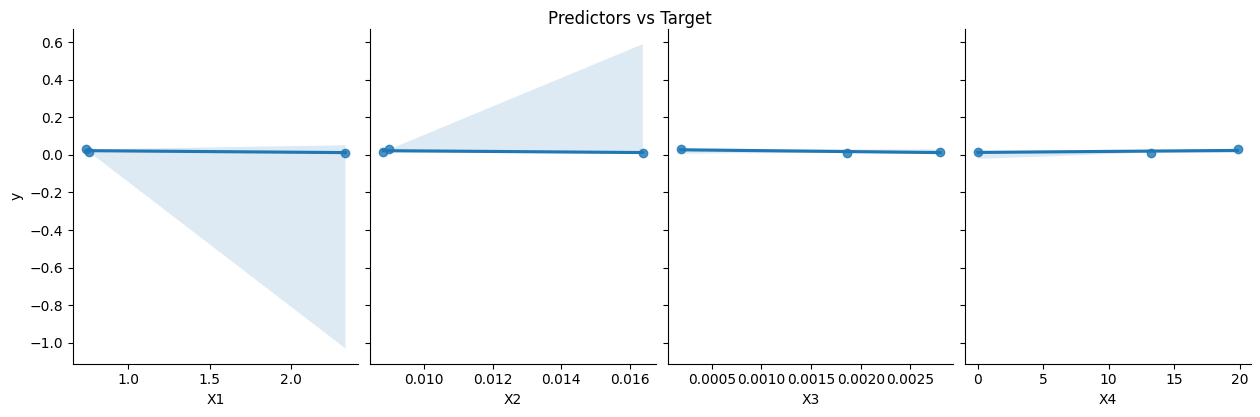

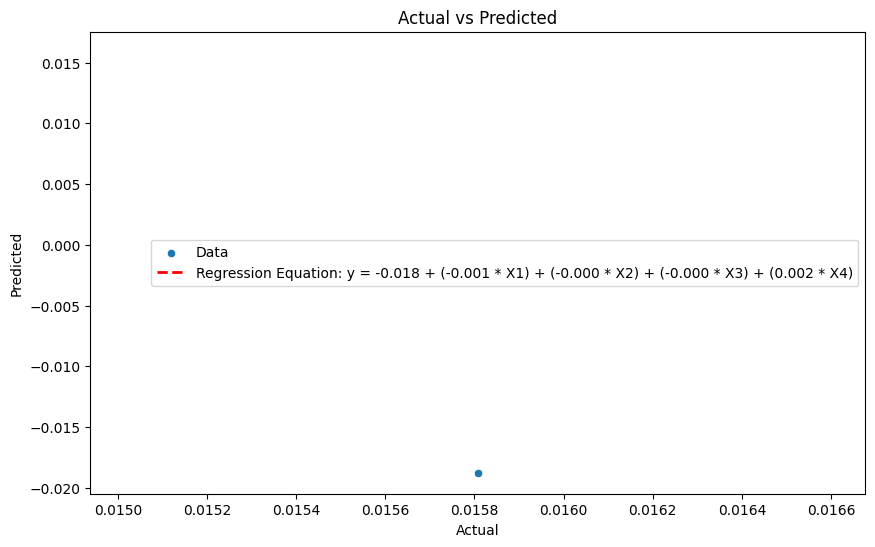

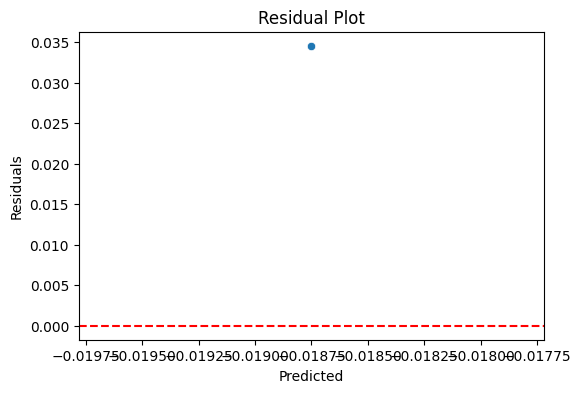

In [115]:
# Four predictors (X1, X2, X3, X4)
X1 = m
X2 = p
X3 = r 
X4 = s

# Target variable with some noise
y = v

# Create DataFrame
df = pd.DataFrame({
    'X1': X1,
    'X2': X2,
    'X3': X3,
    'X4': X4,
    'y': y
})

df = df.dropna(how='any')

# -----------------------------
# 2. Train-test split
# -----------------------------
X = df[['X1', 'X2', 'X3', 'X4']]
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# -----------------------------
# 3. Fit multiple regression model
# -----------------------------
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

equation = f"y = {model.intercept_:.3f}"
for i, col in enumerate(X.columns):
    equation += f" + ({model.coef_[i]:.3f} * {col})"

print("Regression Equation:")
print(equation)

# -----------------------------
# 4. Model evaluation
# -----------------------------
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# -----------------------------
# 5. Visualization
# -----------------------------

# (a) Pairplot to see relationships
sns.pairplot(df, x_vars=['X1', 'X2', 'X3', 'X4'], y_vars='y', height=4, aspect=0.8, kind='reg')
plt.suptitle("Predictors vs Target", y=1.02)
plt.show()

# (b) Actual vs Predicted plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, label="Data")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Regression Equation: {}".format(equation))
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

# (c) Residual plot
residuals = y_test - y_pred
plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


Regression Equation:
y = -0.018 + (-0.000 * X1) + (0.002 * X2) + (-0.001 * X3)
Coefficients: [-2.70457929e-06  2.41027862e-03 -5.83307831e-04]
Intercept: -0.018307846337564722
R² Score: nan
RMSE: 0.0345585460288813


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:1288: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


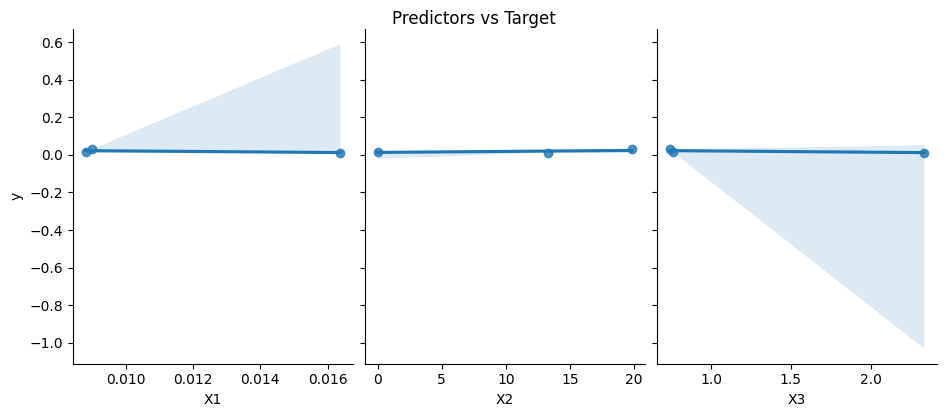

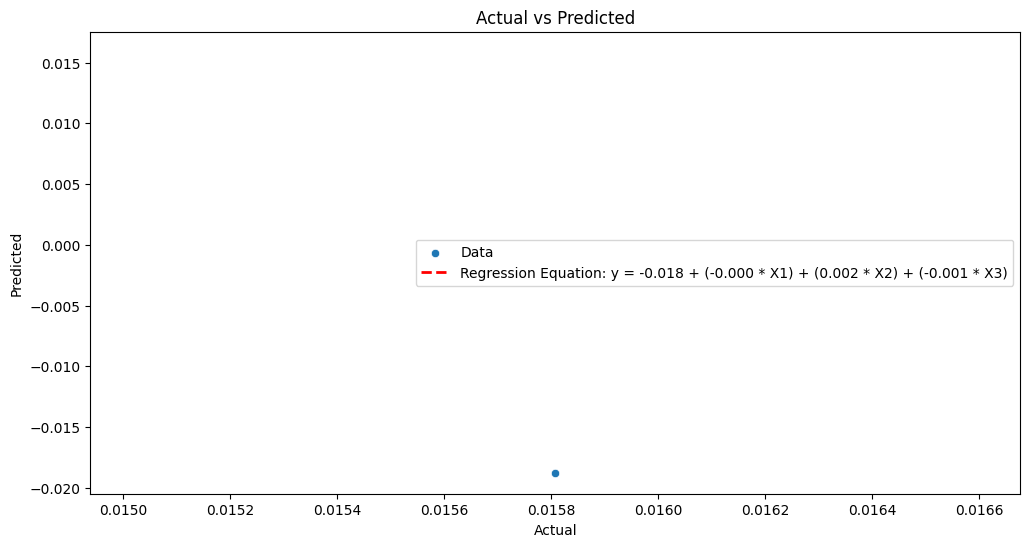

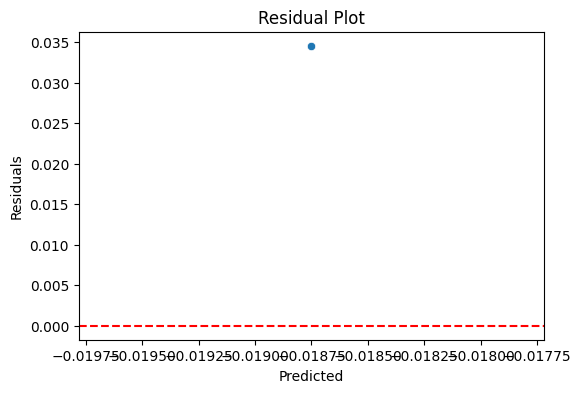

In [119]:
# Four predictors (X1, X2, X3)
X1 = p
X2 = s
X3 = m 

# Target variable with some noise
y = v

# Create DataFrame
df = pd.DataFrame({
    'X1': X1,
    'X2': X2,
    'X3': X3,
    'y': y
})

df = df.dropna(how='any')

# -----------------------------
# 2. Train-test split
# -----------------------------
X = df[['X1', 'X2', 'X3']]
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# -----------------------------
# 3. Fit multiple regression model
# -----------------------------
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

equation = f"y = {model.intercept_:.3f}"
for i, col in enumerate(X.columns):
    equation += f" + ({model.coef_[i]:.3f} * {col})"

print("Regression Equation:")
print(equation)

# -----------------------------
# 4. Model evaluation
# -----------------------------
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# -----------------------------
# 5. Visualization
# -----------------------------

# (a) Pairplot to see relationships
sns.pairplot(df, x_vars=['X1', 'X2', 'X3'], y_vars='y', height=4, aspect=0.8, kind='reg')
plt.suptitle("Predictors vs Target", y=1.02)
plt.show()

# (b) Actual vs Predicted plot
plt.figure(figsize=(12, 6))
sns.scatterplot(x=y_test, y=y_pred, label="Data")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Regression Equation: {}".format(equation))
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

# (c) Residual plot
residuals = y_test - y_pred
plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

### Image statistics

###### Mostly executed using QGIS but other notebooks (https://github.com/jcbw/) can show you how to do that with raw data.

In [3]:
filename = 'C:/Users/HP/Downloads/merida_may24/zonal_stats/zone_stack_aero.tif'
src = rio.open(filename)

n_bands = src.meta['count']
img_shape = src.shape

band_numbers = ['1', '2', '3', '4', '5', '6','7', '8', '9', '10', '11', '12','13', '14', '15', '16', '17', '18','19', '20', '21', '22', '23', '24']

band_names = ['min_335_367', 'min_340_380', 'min_354_388', 'sd_335_367', 'sd_340_380', 'sd_354_388','mean_335_367', 'mean_340_380', 'mean_354_388', 
 'range_335_367', 'range_340_380', 'range_354_388','var_335_367', 'var_340_380', 'var_354_388', 'sum_335_367', 'sum_340_380', 
 'sum_354_388','median_335_367', 'median_340_380', 'median_354_388', 'max_335_367', 'max_340_380', 'max_354_388']

##### This clips the image stack to the Merida shapefile

C:\Users\HP\AppData\Local\Temp\ipykernel_8468\1016223537.py:220: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


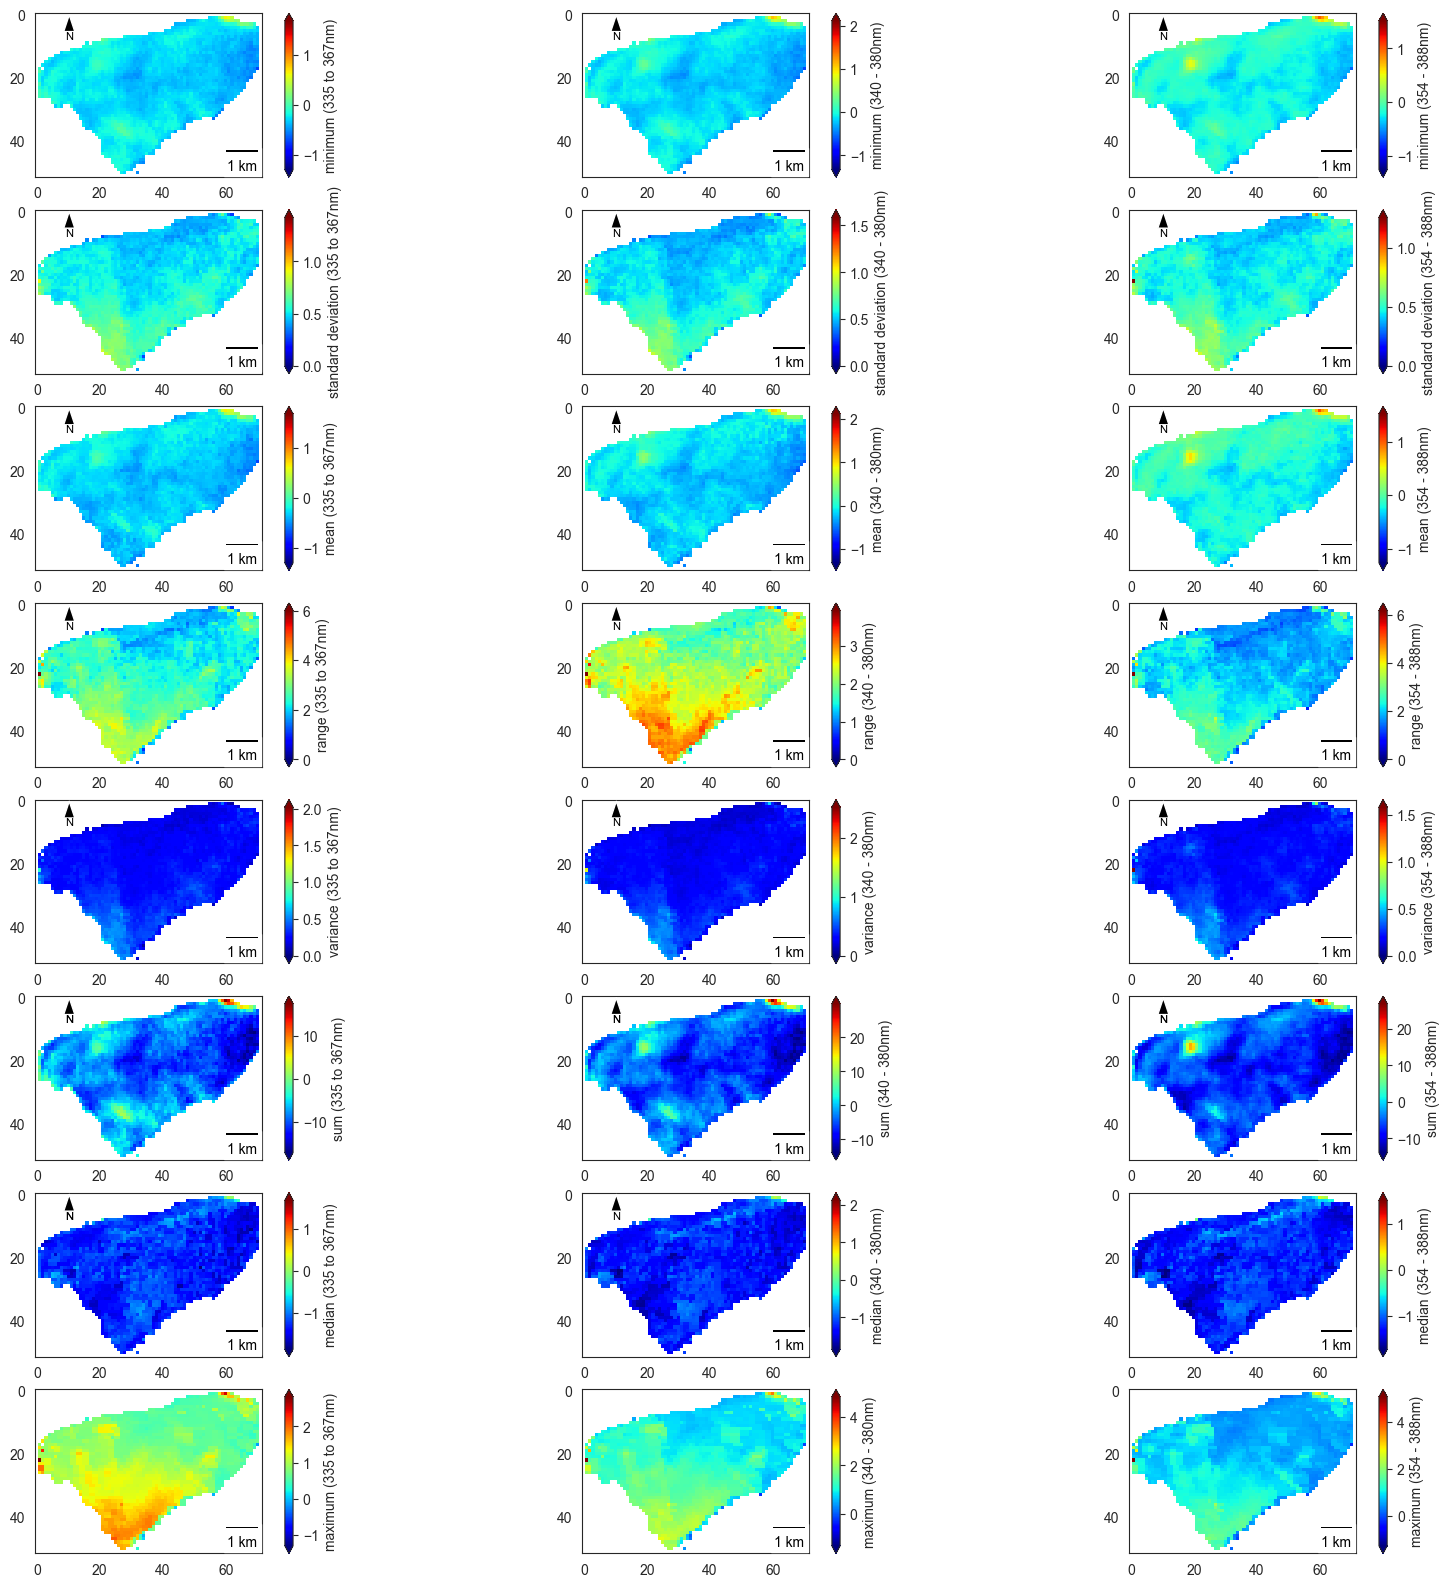

In [6]:
# Directory containing .tif files and shapefile
input_dir = "C:/Users/HP/Downloads/merida_may24/zonal_stats/zone_stack_aero.tif"
shapefile_path = "C:/Users/HP/Downloads/merida_mx/merida.shp"

# Load the shapefile for clipping
shapefile = gpd.read_file(shapefile_path)
geometries = [feature["geometry"] for feature in shapefile.__geo_interface__["features"]]

with rio.open(input_dir) as src:
# Read the data as a NumPy array
    sar_data = src.read()


    clipped_image, clipped_transform = mask(src, geometries, crop=True,filled = False)
    clipped_meta = src.meta.copy()
    
                
    stats_raw = []

    for idx, band in enumerate(src.read()):
    
        stats_raw.append({
            'band': idx + 1,
            'min': band.min(),
            'mean': band.mean(),
            'median': np.median(band),
            'max': band.max(),
            'std': int(np.std(band)),
            'var': int(np.var(band)),
            'vmin': int(band.mean() - np.std(band)),
            'vmax': int(band.mean() + np.std(band)),
    
        })
    
    summary_stats = pd.DataFrame.from_records(
        stats_raw, index='band').astype(int)
                
# summary_stats #uncomment this to print image statistics

fig = plt.figure(figsize=(20,20))
sns.set_style('white')
cmap = plt.get_cmap('jet')
fontsize=8
x, y, arrow_length = 0.15, 0.99, 0.1 
                
ax1 = plt.subplot2grid((8,3), (0,0))
ax1.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax1.transAxes, color='black')
ax2 = plt.subplot2grid((8,3), (0,1))
ax2.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax2.transAxes, color='black')
ax3 = plt.subplot2grid((8,3), (0,2))
ax3.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax3.transAxes, color='black')

ax4 = plt.subplot2grid((8,3), (1,0))
ax4.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax4.transAxes, color='black')
ax5 = plt.subplot2grid((8,3), (1,1))
ax5.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax5.transAxes, color='black')
ax6 = plt.subplot2grid((8,3), (1,2))
ax6.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax6.transAxes, color='black')

ax7 = plt.subplot2grid((8,3), (2,0))
ax7.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax7.transAxes, color='black')
ax8 = plt.subplot2grid((8,3), (2,1))
ax8.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax8.transAxes, color='black')
ax9 = plt.subplot2grid((8,3), (2,2))
ax9.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax9.transAxes, color='black')

ax10 = plt.subplot2grid((8,3), (3,0))
ax10.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax10.transAxes, color='black')
ax11 = plt.subplot2grid((8,3), (3,1))
ax11.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax11.transAxes, color='black')
ax12 = plt.subplot2grid((8,3), (3,2))
ax12.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax12.transAxes, color='black')

ax13 = plt.subplot2grid((8,3), (4,0))
ax13.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax13.transAxes, color='black')
ax14 = plt.subplot2grid((8,3), (4,1))
ax14.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax14.transAxes, color='black')
ax15 = plt.subplot2grid((8,3), (4,2))
ax15.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax15.transAxes, color='black')

ax16 = plt.subplot2grid((8,3), (5,0))
ax16.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax16.transAxes, color='black')
ax17 = plt.subplot2grid((8,3), (5,1))
ax17.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax17.transAxes, color='black')
ax18 = plt.subplot2grid((8,3), (5,2))
ax18.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax18.transAxes, color='black')

ax19 = plt.subplot2grid((8,3), (6,0))
ax19.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax19.transAxes, color='black')
ax20 = plt.subplot2grid((8,3), (6,1))
ax20.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax20.transAxes, color='black')
ax21 = plt.subplot2grid((8,3), (6,2))
ax21.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax16.transAxes, color='black')

ax22 = plt.subplot2grid((8,3), (7,0))
ax22.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax17.transAxes, color='black')
ax23 = plt.subplot2grid((8,3), (7,1))
ax23.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax18.transAxes, color='black')
ax24 = plt.subplot2grid((8,3), (7,2))
ax24.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax19.transAxes, color='black')

                 
b1 = ax1.imshow(clipped_image[0],cmap=cmap, vmin=stats_raw[0]['min'], vmax=stats_raw[0]['max'])
fig.colorbar(b1, ax=ax1, extend='both',label='minimum (335 to 367nm)')
b2 = ax2.imshow(clipped_image[1], cmap=cmap, vmin=stats_raw[1]['min'], vmax=stats_raw[1]['max'])
fig.colorbar(b2, ax=ax2, extend='both',label='minimum (340 - 380nm)')
b3 = ax3.imshow(clipped_image[2], cmap=cmap, vmin=stats_raw[2]['min'], vmax=stats_raw[2]['max'])
fig.colorbar(b3, ax=ax3,extend='both',label='minimum (354 - 388nm)')
b4 = ax4.imshow(clipped_image[3], cmap=cmap, vmin=stats_raw[3]['min'], vmax=stats_raw[3]['max'])
fig.colorbar(b4, ax=ax4,extend='both',label='standard deviation (335 to 367nm)')
b5 = ax5.imshow(clipped_image[4], cmap=cmap, vmin=stats_raw[4]['min'], vmax=stats_raw[4]['max']) 
fig.colorbar(b5, ax=ax5, extend='both',label='standard deviation (340 - 380nm)')
b6 = ax6.imshow(clipped_image[5],cmap=cmap, vmin=stats_raw[5]['min'], vmax=stats_raw[5]['max'])
fig.colorbar(b6, ax=ax6,extend='both',label='standard deviation (354 - 388nm)')
b7 = ax7.imshow(clipped_image[6], cmap=cmap, vmin=stats_raw[6]['min'], vmax=stats_raw[6]['max'])
fig.colorbar(b7, ax=ax7,extend='both',label='mean (335 to 367nm)')
b8 = ax8.imshow(clipped_image[7], cmap=cmap, vmin=stats_raw[7]['min'], vmax=stats_raw[7]['max'])
fig.colorbar(b8, ax=ax8,extend='both',label='mean (340 - 380nm)')

b9 = ax9.imshow(clipped_image[8], cmap=cmap, vmin=stats_raw[8]['min'], vmax=stats_raw[8]['max'])
fig.colorbar(b9, ax=ax9,extend='both',label='mean (354 - 388nm)')
b10 = ax10.imshow(clipped_image[9], cmap=cmap, vmin=stats_raw[9]['min'], vmax=stats_raw[9]['max'])
fig.colorbar(b10, ax=ax10,extend='both',label='range (335 to 367nm)')
b11 = ax11.imshow(clipped_image[10],cmap=cmap, vmin=stats_raw[10]['min'], vmax=stats_raw[10]['max'])
fig.colorbar(b11, ax=ax11,extend='both',label='range (340 - 380nm)')
b12 = ax12.imshow(clipped_image[11], cmap=cmap, vmin=stats_raw[11]['min'], vmax=stats_raw[11]['max'])
fig.colorbar(b12, ax=ax12,extend='both',label='range (354 - 388nm)')
b13 = ax13.imshow(clipped_image[12], cmap=cmap, vmin=stats_raw[12]['min'], vmax=stats_raw[12]['max'])
fig.colorbar(b13, ax=ax13,extend='both',label='variance (335 to 367nm)')
b14 = ax14.imshow(clipped_image[13], cmap=cmap, vmin=stats_raw[13]['min'], vmax=stats_raw[13]['max'])
fig.colorbar(b14, ax=ax14,extend='both',label='variance (340 - 380nm)')
b15 = ax15.imshow(clipped_image[14], cmap=cmap, vmin=stats_raw[14]['min'], vmax=stats_raw[14]['max']) 
fig.colorbar(b15, ax=ax15,extend='both',label='variance (354 - 388nm)')
b16 = ax16.imshow(clipped_image[15],cmap=cmap, vmin=stats_raw[15]['min'], vmax=stats_raw[15]['max'])
fig.colorbar(b16, ax=ax16,extend='both',label='sum (335 to 367nm)')

b17 = ax17.imshow(clipped_image[16], cmap=cmap, vmin=stats_raw[16]['min'], vmax=stats_raw[16]['max'])
fig.colorbar(b17, ax=ax17,extend='both',label='sum (340 - 380nm)')
b18 = ax18.imshow(clipped_image[17], cmap=cmap, vmin=stats_raw[17]['min'], vmax=stats_raw[17]['max'])
fig.colorbar(b18, ax=ax18, extend='both',label='sum (354 - 388nm)')
b19 = ax19.imshow(clipped_image[18], cmap=cmap, vmin=stats_raw[18]['min'], vmax=stats_raw[18]['max'])
fig.colorbar(b19, ax=ax19, extend='both',label='median (335 to 367nm)')
b20 = ax20.imshow(clipped_image[19], cmap=cmap, vmin=stats_raw[19]['min'], vmax=stats_raw[19]['max']) 
fig.colorbar(b20, ax=ax20, extend='both',label='median (340 - 380nm)')
b21 = ax21.imshow(clipped_image[20],cmap=cmap, vmin=stats_raw[20]['min'], vmax=stats_raw[20]['max'])
fig.colorbar(b21, ax=ax21, extend='both',label='median (354 - 388nm)')
b22 = ax22.imshow(clipped_image[21], cmap=cmap, vmin=stats_raw[21]['min'], vmax=stats_raw[21]['max'])
fig.colorbar(b22, ax=ax22, extend='both',label='maximum (335 to 367nm)')
b23 = ax23.imshow(clipped_image[22], cmap=cmap, vmin=stats_raw[22]['min'], vmax=stats_raw[22]['max'])
fig.colorbar(b23, ax=ax23, extend='both',label='maximum (340 - 380nm)')
b24 = ax24.imshow(clipped_image[23], cmap=cmap, vmin=stats_raw[23]['min'], vmax=stats_raw[23]['max'])
fig.colorbar(b24, ax=ax24, extend='both',label='maximum (354 - 388nm)')


scalebar1 = ScaleBar(100, units="m", location='lower right')
scalebar2 = ScaleBar(100, units="m", location='lower right')
scalebar3 = ScaleBar(100, units="m", location='lower right')

scalebar4 = ScaleBar(100, units="m", location='lower right')
scalebar5 = ScaleBar(100, units="m", location='lower right')
scalebar6 = ScaleBar(100, units="m", location='lower right')

scalebar7 = ScaleBar(100, units="m", location='lower right')
scalebar8 = ScaleBar(100, units="m", location='lower right')
scalebar9 = ScaleBar(100, units="m", location='lower right')

scalebar10 = ScaleBar(100, units="m", location='lower right')
scalebar11 = ScaleBar(100, units="m", location='lower right')
scalebar12 = ScaleBar(100, units="m", location='lower right')

scalebar13 = ScaleBar(100, units="m", location='lower right')
scalebar14 = ScaleBar(100, units="m", location='lower right')
scalebar15 = ScaleBar(100, units="m", location='lower right')

scalebar16 = ScaleBar(100, units="m", location='lower right')
scalebar17 = ScaleBar(100, units="m", location='lower right')
scalebar18 = ScaleBar(100, units="m", location='lower right')

scalebar19 = ScaleBar(100, units="m", location='lower right')
scalebar20 = ScaleBar(100, units="m", location='lower right')
scalebar21 = ScaleBar(100, units="m", location='lower right')

scalebar22 = ScaleBar(100, units="m", location='lower right')
scalebar23 = ScaleBar(100, units="m", location='lower right')
scalebar24 = ScaleBar(100, units="m", location='lower right')


ax1.add_artist(scalebar1)
ax2.add_artist(scalebar2)
ax3.add_artist(scalebar3)

ax4.add_artist(scalebar4)
ax5.add_artist(scalebar5)
ax6.add_artist(scalebar6)

ax7.add_artist(scalebar7)
ax8.add_artist(scalebar8)
ax9.add_artist(scalebar9)

ax10.add_artist(scalebar10)
ax11.add_artist(scalebar11)
ax12.add_artist(scalebar12)

ax13.add_artist(scalebar13)
ax14.add_artist(scalebar14)
ax15.add_artist(scalebar15)

ax16.add_artist(scalebar16)
ax17.add_artist(scalebar17)
ax18.add_artist(scalebar18)

ax19.add_artist(scalebar19)
ax20.add_artist(scalebar20)
ax21.add_artist(scalebar21)

ax22.add_artist(scalebar22)
ax23.add_artist(scalebar23)
ax24.add_artist(scalebar24)

plt.tight_layout()
# plt.savefig("C:/Users/HP/Documents/src_paper/PMclip_3.jpeg", dpi = 1000)
# plt.savefig("C:/Users/HP/Downloads/merida_may24/images/clip_areo_nofill.jpeg")
plt.show()


##### Without clipping

C:\Users\HP\AppData\Local\Temp\ipykernel_13724\1735158621.py:168: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


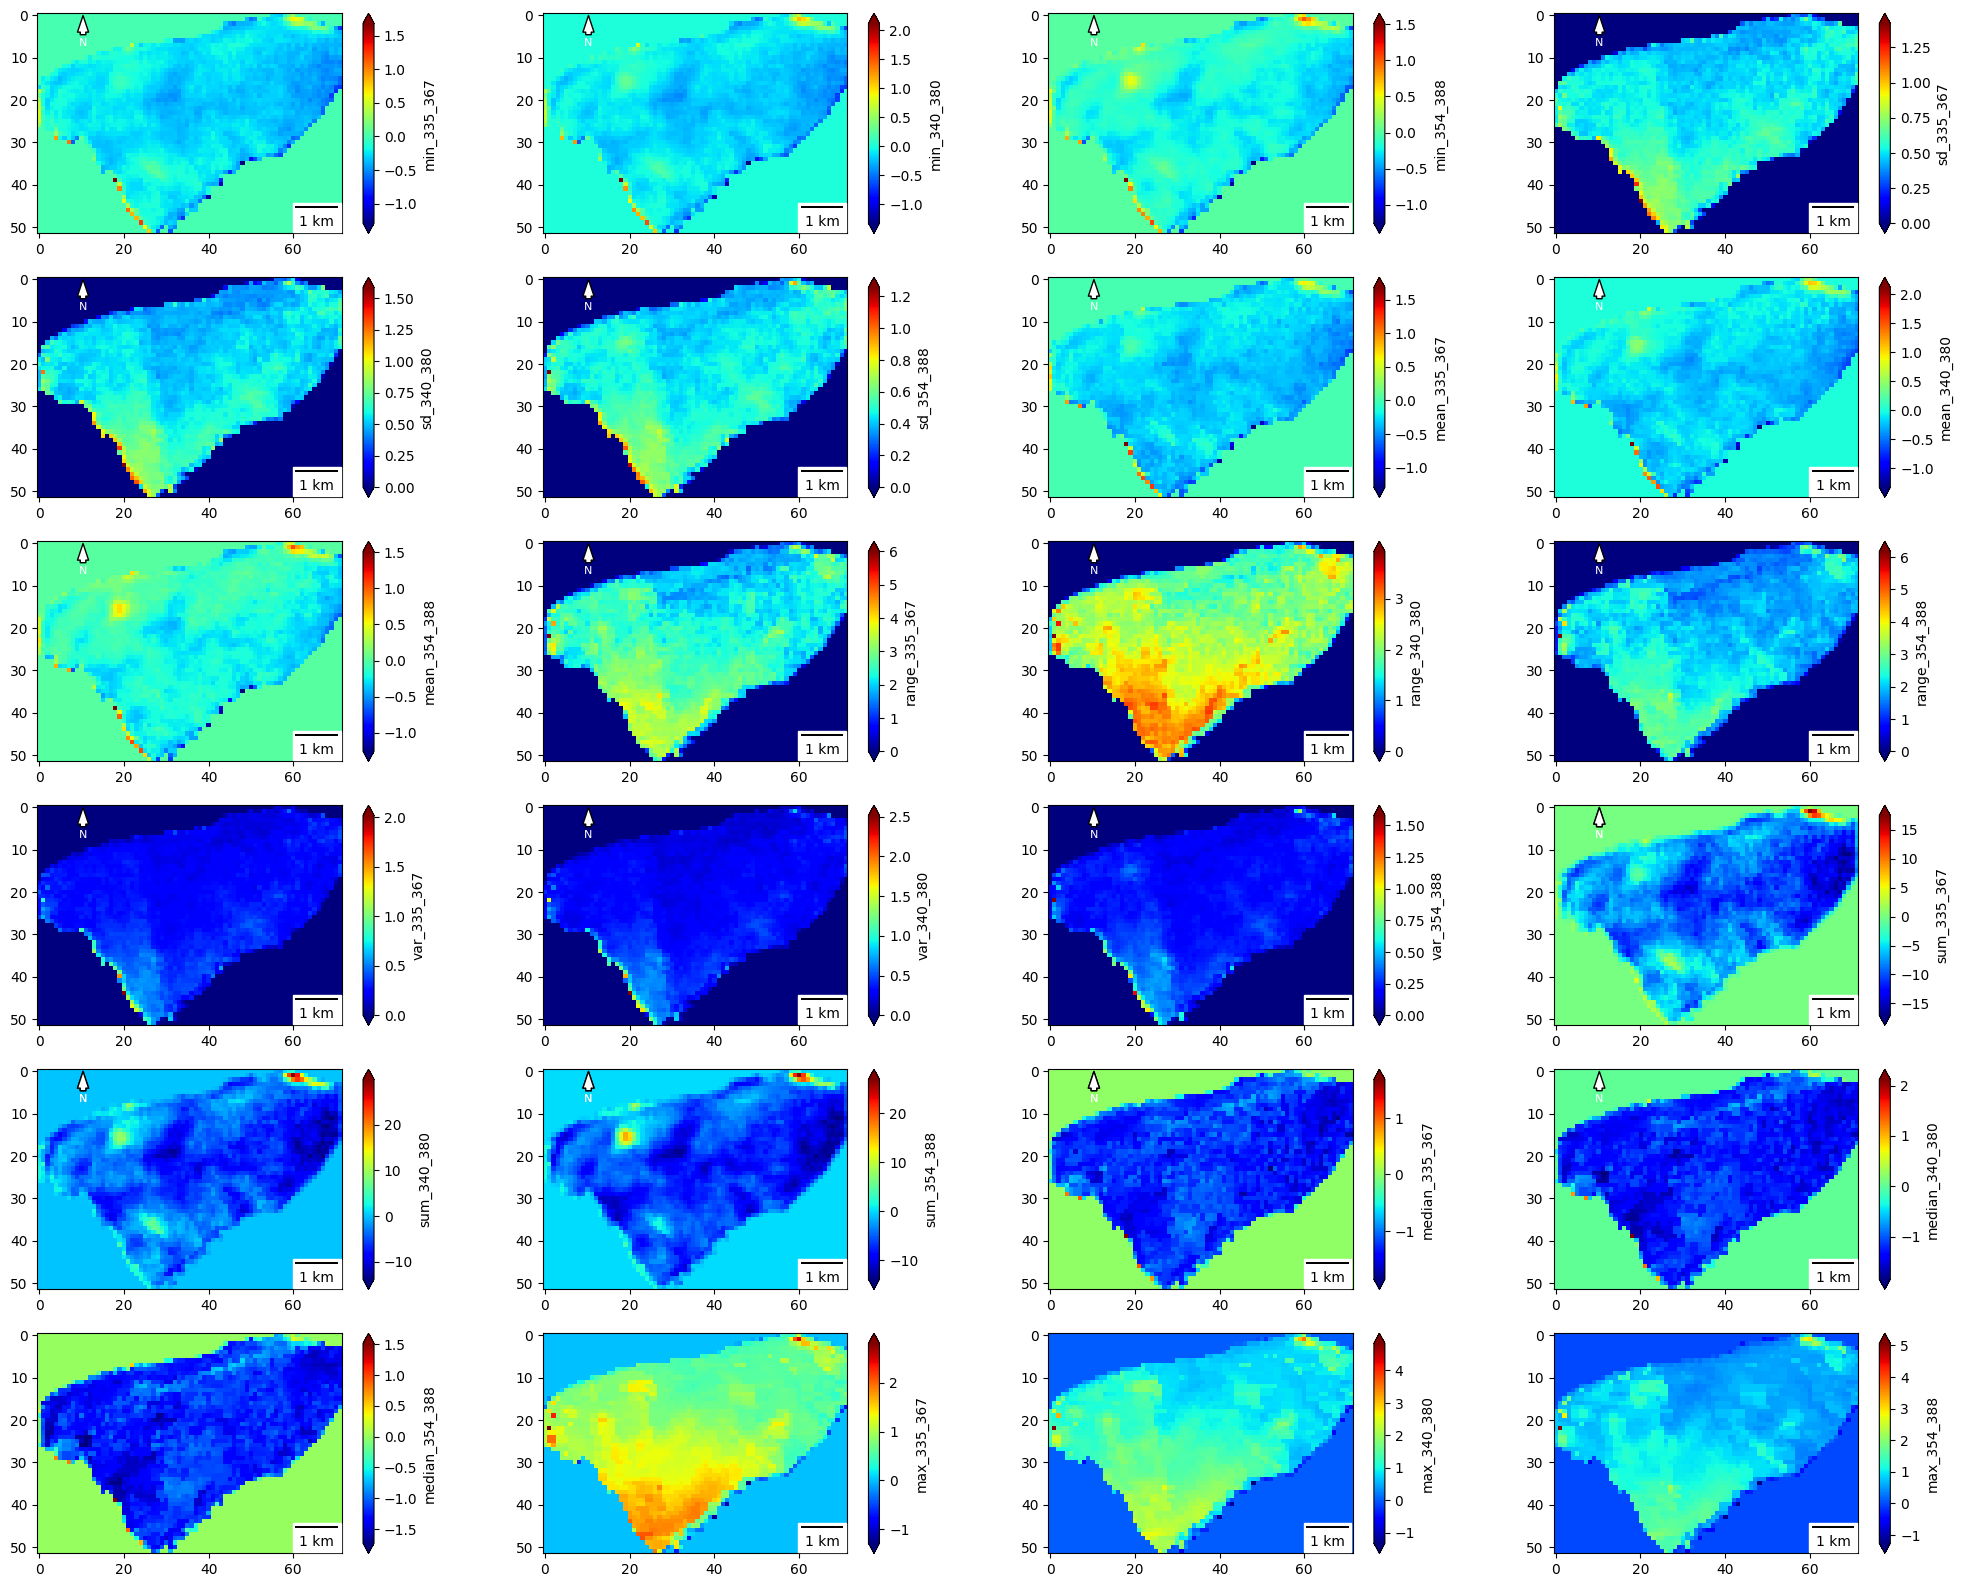

In [9]:
fig = plt.figure(figsize=(25,20))
cmap = plt.get_cmap('jet')
fontsize=8
x, y, arrow_length = 0.15, 0.99, 0.1 

ax1 = plt.subplot2grid((6,4), (0,0))
ax1.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax1.transAxes, color='white')
ax2 = plt.subplot2grid((6,4), (0,1))
ax2.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax2.transAxes, color='white')
ax3 = plt.subplot2grid((6,4), (0,2))
ax3.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax3.transAxes, color='white')
ax4 = plt.subplot2grid((6,4), (0,3))
ax4.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax4.transAxes, color='white')

ax5 = plt.subplot2grid((6,4), (1,0))
ax5.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax5.transAxes, color='white')
ax6 = plt.subplot2grid((6,4), (1,1))
ax6.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax6.transAxes, color='white')
ax7 = plt.subplot2grid((6,4), (1,2))
ax7.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax7.transAxes, color='white')
ax8 = plt.subplot2grid((6,4), (1,3))
ax8.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax8.transAxes, color='white')

ax9 = plt.subplot2grid((6,4), (2,0))
ax9.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax9.transAxes, color='white')
ax10 = plt.subplot2grid((6,4), (2,1))
ax10.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax10.transAxes, color='white')
ax11 = plt.subplot2grid((6,4), (2,2))
ax11.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax11.transAxes, color='white')
ax12 = plt.subplot2grid((6,4), (2,3))
ax12.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax12.transAxes, color='white')

ax13 = plt.subplot2grid((6,4), (3,0))
ax13.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax13.transAxes, color='white')
ax14 = plt.subplot2grid((6,4), (3,1))
ax14.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax14.transAxes, color='white')
ax15 = plt.subplot2grid((6,4), (3,2))
ax15.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax15.transAxes, color='white')
ax16 = plt.subplot2grid((6,4), (3,3))
ax16.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax16.transAxes, color='white')

ax17 = plt.subplot2grid((6,4), (4,0))
ax17.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax17.transAxes, color='white')
ax18 = plt.subplot2grid((6,4), (4,1))
ax18.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax18.transAxes, color='white')
ax19 = plt.subplot2grid((6,4), (4,2))
ax19.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax19.transAxes, color='white')
ax20 = plt.subplot2grid((6,4), (4,3))
ax20.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax20.transAxes, color='white')

ax21 = plt.subplot2grid((6,4), (5,0))
ax21.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax16.transAxes, color='white')
ax22 = plt.subplot2grid((6,4), (5,1))
ax22.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax17.transAxes, color='white')
ax23 = plt.subplot2grid((6,4), (5,2))
ax23.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax18.transAxes, color='white')
ax24 = plt.subplot2grid((6,4), (5,3))
ax24.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='white', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax19.transAxes, color='white')

 
b1 = ax1.imshow(src.read()[0],cmap=cmap, vmin=stats_raw[0]['min'], vmax=stats_raw[0]['max'])
fig.colorbar(b1, ax=ax1, extend='both',label='min_335_367')
b2 = ax2.imshow(src.read()[1], cmap=cmap, vmin=stats_raw[1]['min'], vmax=stats_raw[1]['max'])
fig.colorbar(b2, ax=ax2, extend='both',label='min_340_380')
b3 = ax3.imshow(src.read()[2], cmap=cmap, vmin=stats_raw[2]['min'], vmax=stats_raw[2]['max'])
fig.colorbar(b3, ax=ax3,extend='both',label='min_354_388')
b4 = ax4.imshow(src.read()[3], cmap=cmap, vmin=stats_raw[3]['min'], vmax=stats_raw[3]['max'])
fig.colorbar(b4, ax=ax4,extend='both',label='sd_335_367')
b5 = ax5.imshow(src.read()[4], cmap=cmap, vmin=stats_raw[4]['min'], vmax=stats_raw[4]['max']) 
fig.colorbar(b5, ax=ax5, extend='both',label='sd_340_380')
b6 = ax6.imshow(src.read()[5],cmap=cmap, vmin=stats_raw[5]['min'], vmax=stats_raw[5]['max'])
fig.colorbar(b6, ax=ax6,extend='both',label='sd_354_388')
b7 = ax7.imshow(src.read()[6], cmap=cmap, vmin=stats_raw[6]['min'], vmax=stats_raw[6]['max'])
fig.colorbar(b7, ax=ax7,extend='both',label='mean_335_367')
b8 = ax8.imshow(src.read()[7], cmap=cmap, vmin=stats_raw[7]['min'], vmax=stats_raw[7]['max'])
fig.colorbar(b8, ax=ax8,extend='both',label='mean_340_380')

b9 = ax9.imshow(src.read()[8], cmap=cmap, vmin=stats_raw[8]['min'], vmax=stats_raw[8]['max'])
fig.colorbar(b9, ax=ax9,extend='both',label='mean_354_388')
b10 = ax10.imshow(src.read()[9], cmap=cmap, vmin=stats_raw[9]['min'], vmax=stats_raw[9]['max'])
fig.colorbar(b10, ax=ax10,extend='both',label='range_335_367')
b11 = ax11.imshow(src.read()[10],cmap=cmap, vmin=stats_raw[10]['min'], vmax=stats_raw[10]['max'])
fig.colorbar(b11, ax=ax11,extend='both',label='range_340_380')
b12 = ax12.imshow(src.read()[11], cmap=cmap, vmin=stats_raw[11]['min'], vmax=stats_raw[11]['max'])
fig.colorbar(b12, ax=ax12,extend='both',label='range_354_388')
b13 = ax13.imshow(src.read()[12], cmap=cmap, vmin=stats_raw[12]['min'], vmax=stats_raw[12]['max'])
fig.colorbar(b13, ax=ax13,extend='both',label='var_335_367')
b14 = ax14.imshow(src.read()[13], cmap=cmap, vmin=stats_raw[13]['min'], vmax=stats_raw[13]['max'])
fig.colorbar(b14, ax=ax14,extend='both',label='var_340_380')
b15 = ax15.imshow(src.read()[14], cmap=cmap, vmin=stats_raw[14]['min'], vmax=stats_raw[14]['max']) 
fig.colorbar(b15, ax=ax15,extend='both',label='var_354_388')
b16 = ax16.imshow(src.read()[15],cmap=cmap, vmin=stats_raw[15]['min'], vmax=stats_raw[15]['max'])
fig.colorbar(b16, ax=ax16,extend='both',label='sum_335_367')

b17 = ax17.imshow(src.read()[16], cmap=cmap, vmin=stats_raw[16]['min'], vmax=stats_raw[16]['max'])
fig.colorbar(b17, ax=ax17,extend='both',label='sum_340_380')
b18 = ax18.imshow(src.read()[17], cmap=cmap, vmin=stats_raw[17]['min'], vmax=stats_raw[17]['max'])
fig.colorbar(b18, ax=ax18, extend='both',label='sum_354_388')
b19 = ax19.imshow(src.read()[18], cmap=cmap, vmin=stats_raw[18]['min'], vmax=stats_raw[18]['max'])
fig.colorbar(b19, ax=ax19, extend='both',label='median_335_367')
b20 = ax20.imshow(src.read()[19], cmap=cmap, vmin=stats_raw[19]['min'], vmax=stats_raw[19]['max']) 
fig.colorbar(b20, ax=ax20, extend='both',label='median_340_380')
b21 = ax21.imshow(src.read()[20],cmap=cmap, vmin=stats_raw[20]['min'], vmax=stats_raw[20]['max'])
fig.colorbar(b21, ax=ax21, extend='both',label='median_354_388')
b22 = ax22.imshow(src.read()[21], cmap=cmap, vmin=stats_raw[21]['min'], vmax=stats_raw[21]['max'])
fig.colorbar(b22, ax=ax22, extend='both',label='max_335_367')
b23 = ax23.imshow(src.read()[22], cmap=cmap, vmin=stats_raw[22]['min'], vmax=stats_raw[22]['max'])
fig.colorbar(b23, ax=ax23, extend='both',label='max_340_380')
b24 = ax24.imshow(src.read()[23], cmap=cmap, vmin=stats_raw[23]['min'], vmax=stats_raw[23]['max'])
fig.colorbar(b24, ax=ax24, extend='both',label='max_354_388')


scalebar1 = ScaleBar(100, units="m", location='lower right')
scalebar2 = ScaleBar(100, units="m", location='lower right')
scalebar3 = ScaleBar(100, units="m", location='lower right')
scalebar4 = ScaleBar(100, units="m", location='lower right')
scalebar5 = ScaleBar(100, units="m", location='lower right')
scalebar6 = ScaleBar(100, units="m", location='lower right')
scalebar7 = ScaleBar(100, units="m", location='lower right')
scalebar8 = ScaleBar(100, units="m", location='lower right')

scalebar9 = ScaleBar(100, units="m", location='lower right')
scalebar10 = ScaleBar(100, units="m", location='lower right')
scalebar11 = ScaleBar(100, units="m", location='lower right')
scalebar12 = ScaleBar(100, units="m", location='lower right')
scalebar13 = ScaleBar(100, units="m", location='lower right')
scalebar14 = ScaleBar(100, units="m", location='lower right')
scalebar15 = ScaleBar(100, units="m", location='lower right')
scalebar16 = ScaleBar(100, units="m", location='lower right')

scalebar17 = ScaleBar(100, units="m", location='lower right')
scalebar18 = ScaleBar(100, units="m", location='lower right')
scalebar19 = ScaleBar(100, units="m", location='lower right')
scalebar20 = ScaleBar(100, units="m", location='lower right')
scalebar21 = ScaleBar(100, units="m", location='lower right')
scalebar22 = ScaleBar(100, units="m", location='lower right')
scalebar23 = ScaleBar(100, units="m", location='lower right')
scalebar24 = ScaleBar(100, units="m", location='lower right')


ax1.add_artist(scalebar1)
ax2.add_artist(scalebar2)
ax3.add_artist(scalebar3)
ax4.add_artist(scalebar4)
ax5.add_artist(scalebar5)
ax6.add_artist(scalebar6)
ax7.add_artist(scalebar7)
ax8.add_artist(scalebar8)

ax9.add_artist(scalebar9)
ax10.add_artist(scalebar10)
ax11.add_artist(scalebar11)
ax12.add_artist(scalebar12)
ax13.add_artist(scalebar13)
ax14.add_artist(scalebar14)
ax15.add_artist(scalebar15)
ax16.add_artist(scalebar16)

ax17.add_artist(scalebar17)
ax18.add_artist(scalebar18)
ax19.add_artist(scalebar19)
ax20.add_artist(scalebar20)
ax21.add_artist(scalebar21)
ax22.add_artist(scalebar22)
ax23.add_artist(scalebar23)
ax24.add_artist(scalebar24)

plt.tight_layout()
# plt.savefig("C:/Users/HP/Downloads/merida_may24/images/unclip_aero.jpeg")
plt.show()

#### Looking at the monitored PM2.5 values in May 2024

In [105]:
Df24.head(3)

,datetime,value,parameter,unit,country,city,latitude,longitude
0,2024-04-01 19:00:00+00:00,1.113699,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
1,2024-04-01 20:00:00+00:00,0.836295,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
2,2024-04-01 21:00:00+00:00,0.744609,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111


In [83]:
# Define date range
start_date = "2024-05-01"
end_date = "2024-05-31"

# Method 1: Boolean mask
mask = (Df24["datetime"] >= start_date) & (Df24["datetime"] <= end_date)
img_Df24 = Df24.loc[mask]
img_Df24

,datetime,value,parameter,unit,country,city,latitude,longitude
237,2024-05-01 00:00:00+00:00,0.068455,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
238,2024-05-01 01:00:00+00:00,0.167520,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
239,2024-05-01 02:00:00+00:00,0.223707,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
240,2024-05-01 03:00:00+00:00,0.167991,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
241,2024-05-01 04:00:00+00:00,0.084112,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
471,2024-05-17 18:00:00+00:00,46.461771,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
472,2024-05-17 19:00:00+00:00,39.054807,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
473,2024-05-17 20:00:00+00:00,48.616937,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
474,2024-05-17 21:00:00+00:00,56.427802,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111


In [84]:
mask = (img_Df24["parameter"] == 'pm25')
img_pm25 = img_Df24.loc[mask]
img_pm25

,datetime,value,parameter,unit,country,city,latitude,longitude
323,2024-05-04 17:00:00+00:00,5.085717,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
324,2024-05-04 18:00:00+00:00,4.294203,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
325,2024-05-04 19:00:00+00:00,5.483184,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
326,2024-05-04 20:00:00+00:00,8.413799,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
327,2024-05-04 21:00:00+00:00,31.025634,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
471,2024-05-17 18:00:00+00:00,46.461771,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
472,2024-05-17 19:00:00+00:00,39.054807,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
473,2024-05-17 20:00:00+00:00,48.616937,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
474,2024-05-17 21:00:00+00:00,56.427802,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111


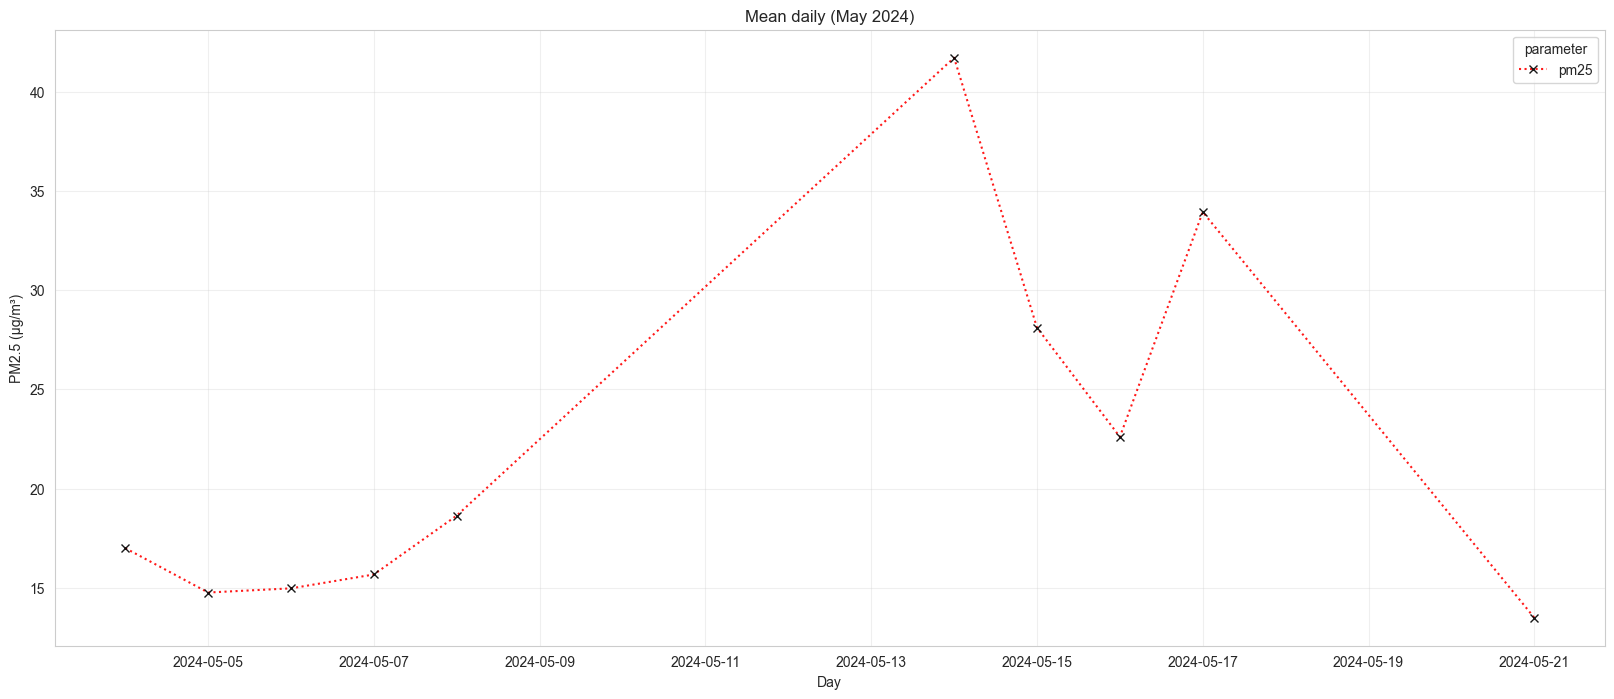

In [413]:
sns.set_style("whitegrid")
img_pm25.groupby([img_pm25["datetime"].dt.date,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8), marker='x', mec = 'k', linestyle='dotted', color='red', alpha = 0.9)
plt.ylabel('PM2.5 (µg/m³)')
plt.xlabel('Day')
plt.title('Mean daily (May 2024)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/DAYMEAN_PM_MAY_.jpeg", dpi = 1200)
plt.show()

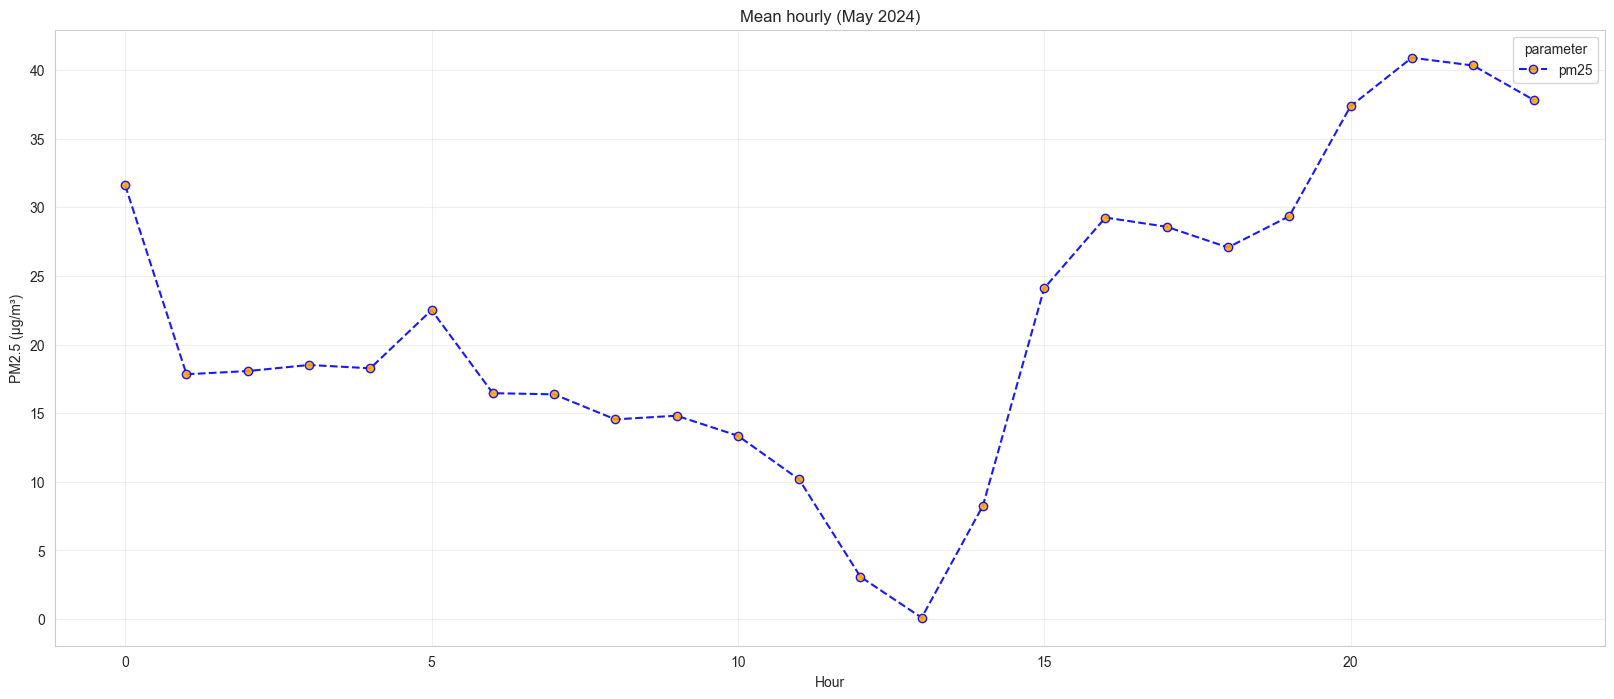

In [368]:
sns.set_style("whitegrid")
img_pm25.groupby([img_pm25["datetime"].dt.hour,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='o', mfc = 'orange', linestyle='--', color='blue', alpha = 0.9)
plt.ylabel('PM2.5 (µg/m³)')
plt.xlabel('Hour')
plt.title('Mean hourly (May 2024)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/HRMEAN_PM_MAY_.jpeg", dpi = 1200)
plt.show()

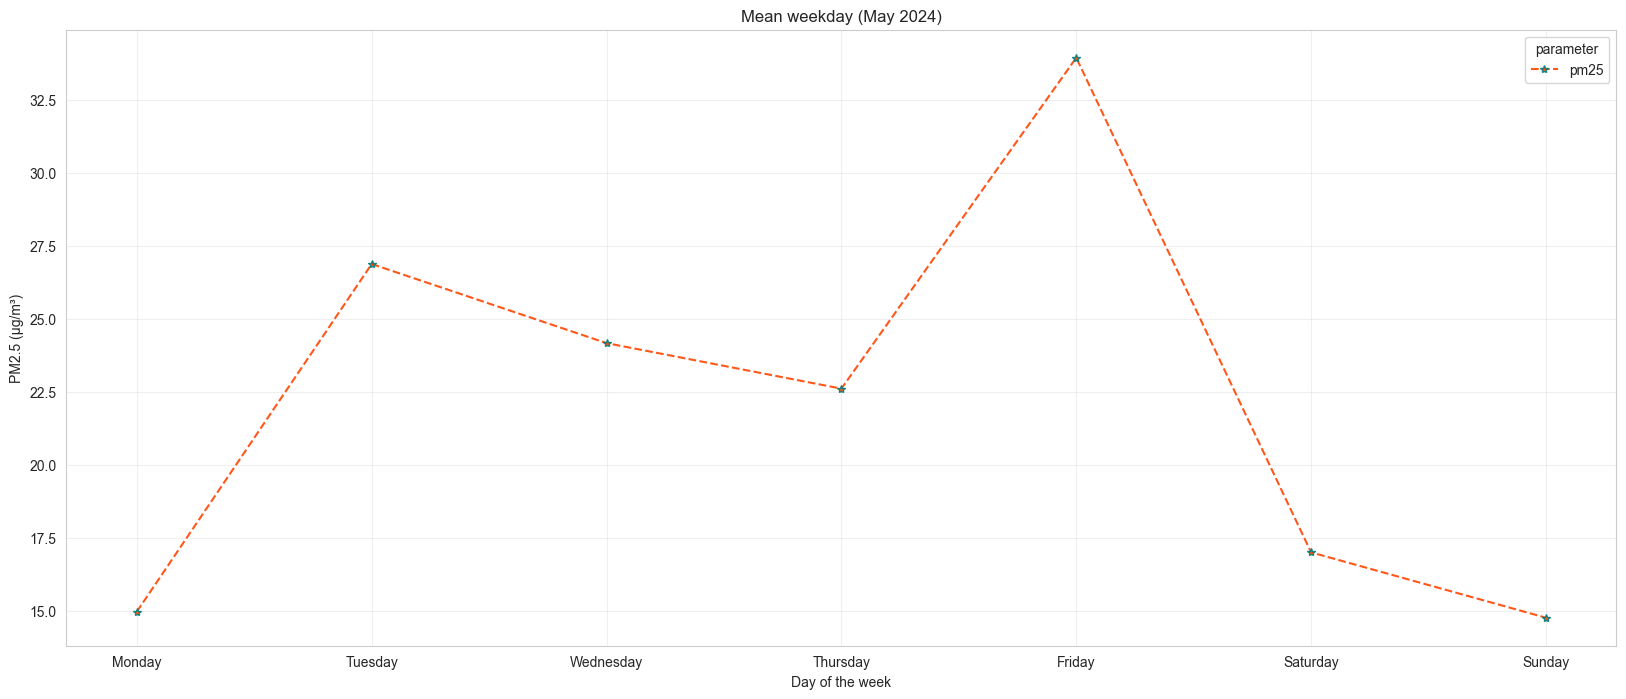

In [366]:
sns.set_style("whitegrid")
img_pm25.groupby([img_pm25["datetime"].dt.weekday,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='*', mec = 'teal', linestyle='--', color = 'orangered', alpha = 0.9)
plt.xticks([0,1,2,3,4,5,6],['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
plt.ylabel('PM2.5 (µg/m³)')
plt.xlabel('Day of the week')
plt.title('Mean weekday (May 2024)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/WEEKMEAN_PM_MAY_.jpeg", dpi = 1200)
plt.show()

In [458]:
um = img_pm25.groupby([img_pm25["datetime"].dt.weekday,'parameter'])["value"].mean().unstack()
umy = img_pm25.groupby([img_pm25["datetime"].dt.hour,'parameter'])["value"].mean().unstack()
um

parameter,pm25
datetime,
0,14.977708
1,26.873730
2,24.166167
3,22.608988
4,33.933973
5,17.005247
6,14.768262


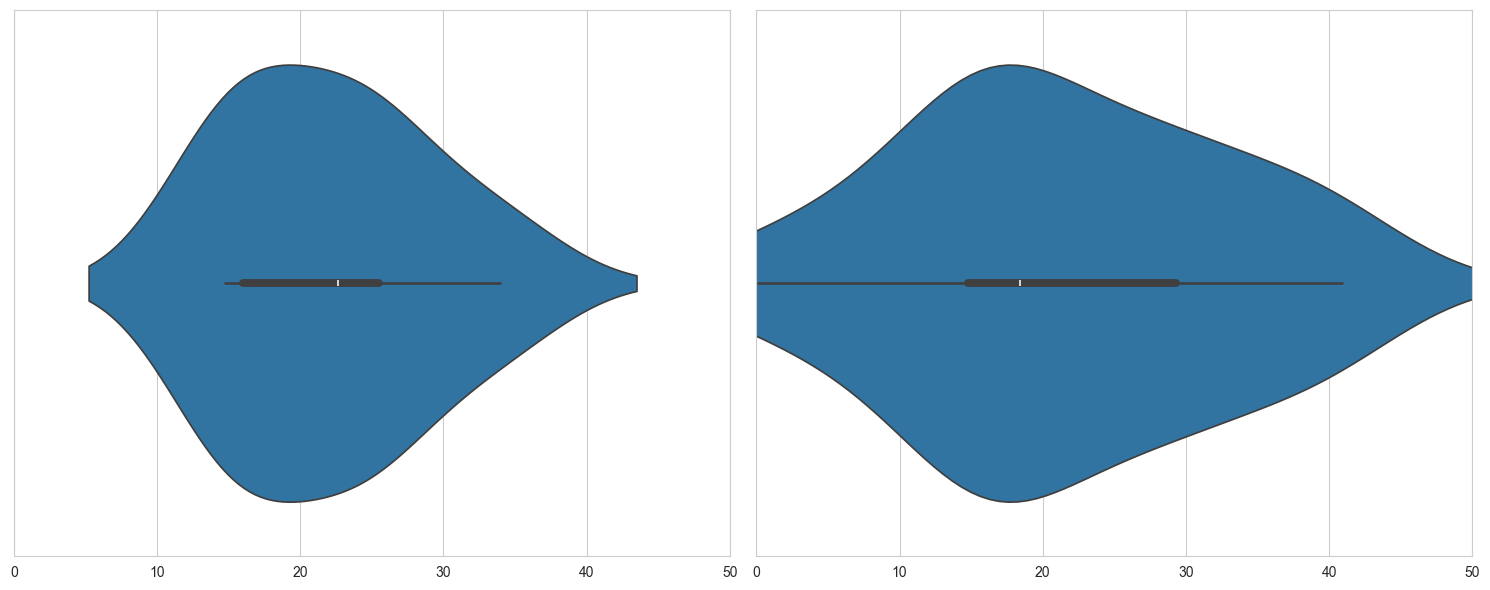

In [459]:
# Looking at data skew
# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# First violin plot
sns.violinplot(x=um["pm25"], orient= "v", ax=axes[0])
axes[0].set_xlim(0, 50) 
axes[0].set_title("")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

# Second violin plot
sns.violinplot(x=umy["pm25"], orient= "v", ax=axes[1])
axes[1].set_xlim(0, 50)
axes[1].set_title("")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [7]:
filename = 'C:/Users/HP/Downloads/merida_may24/zonal_stats/zone_stack_co.tif'
src = rio.open(filename)

n_bands = src.meta['count']
img_shape = src.shape

band_numbers = ['1', '2', '3', '4', '5', '6','7', '8']

band_names = ['range','max','min','variance','sd','median','mean','sum']

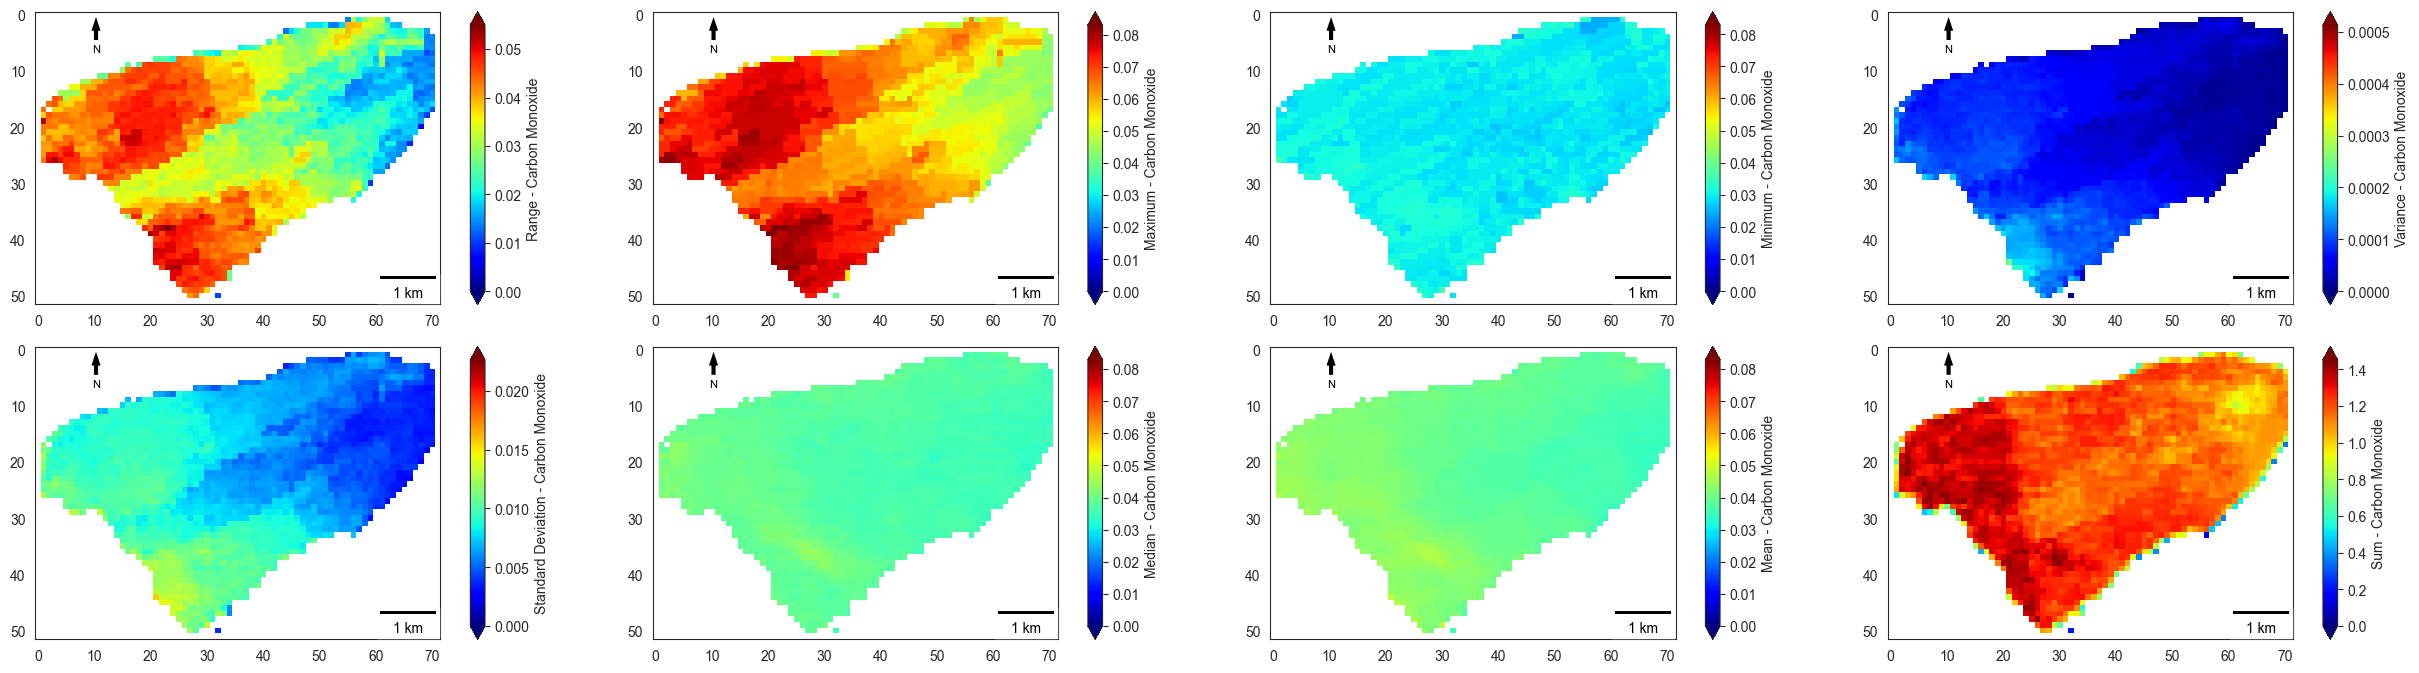

In [8]:
# Directory containing .tif files and shapefile
input_dir = "C:/Users/HP/Downloads/merida_may24/zonal_stats/zone_stack_co.tif"
shapefile_path = "C:/Users/HP/Downloads/merida_mx/merida.shp"

# Load the shapefile for clipping
shapefile = gpd.read_file(shapefile_path)
geometries = [feature["geometry"] for feature in shapefile.__geo_interface__["features"]]

with rio.open(input_dir) as src:
# Read the data as a NumPy array
    sar_data = src.read()


    clipped_image, clipped_transform = mask(src, geometries, crop=True, filled=False)
    clipped_meta = src.meta.copy()
    
                
    stats_raw = []

    for idx, band in enumerate(src.read()):
    
        stats_raw.append({
            'band': idx + 1,
            'min': band.min(),
            'mean': band.mean(),
            'median': np.median(band),
            'max': band.max(),
            'std': int(np.std(band)),
            'var': int(np.var(band)),
            'vmin': int(band.mean() - np.std(band)),
            'vmax': int(band.mean() + np.std(band)),
    
        })
    
    summary_stats = pd.DataFrame.from_records(
        stats_raw, index='band').astype(int)
                
# summary_stats #uncomment this to print image statistics
sns.set_style("white")
fig = plt.figure(figsize=(25,20))
cmap = plt.get_cmap('jet')
fontsize=8
x, y, arrow_length = 0.15, 0.99, 0.1 
                
ax1 = plt.subplot2grid((6,4), (0,0))
ax1.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax1.transAxes, color='black')
ax2 = plt.subplot2grid((6,4), (0,1))
ax2.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax2.transAxes, color='black')
ax3 = plt.subplot2grid((6,4), (0,2))
ax3.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax3.transAxes, color='black')
ax4 = plt.subplot2grid((6,4), (0,3))
ax4.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax4.transAxes, color='black')

ax5 = plt.subplot2grid((6,4), (1,0))
ax5.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax5.transAxes, color='black')
ax6 = plt.subplot2grid((6,4), (1,1))
ax6.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax6.transAxes, color='black')
ax7 = plt.subplot2grid((6,4), (1,2))
ax7.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax7.transAxes, color='black')
ax8 = plt.subplot2grid((6,4), (1,3))
ax8.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax8.transAxes, color='black')

                 
b1 = ax1.imshow(clipped_image[0],cmap=cmap, vmin=stats_raw[0]['min'], vmax=stats_raw[0]['max'])
fig.colorbar(b1, ax=ax1, extend='both',label='Range - Carbon Monoxide')
b2 = ax2.imshow(clipped_image[1], cmap=cmap, vmin=stats_raw[1]['min'], vmax=stats_raw[1]['max'])
fig.colorbar(b2, ax=ax2, extend='both',label='Maximum - Carbon Monoxide')
b3 = ax3.imshow(clipped_image[2], cmap=cmap, vmin=stats_raw[2]['min'], vmax=stats_raw[2]['max'])
fig.colorbar(b3, ax=ax3,extend='both',label='Minimum - Carbon Monoxide')
b4 = ax4.imshow(clipped_image[3], cmap=cmap, vmin=stats_raw[3]['min'], vmax=stats_raw[3]['max'])
fig.colorbar(b4, ax=ax4,extend='both',label='Variance - Carbon Monoxide')
b5 = ax5.imshow(clipped_image[4], cmap=cmap, vmin=stats_raw[4]['min'], vmax=stats_raw[4]['max']) 
fig.colorbar(b5, ax=ax5, extend='both',label='Standard Deviation - Carbon Monoxide')
b6 = ax6.imshow(clipped_image[5],cmap=cmap, vmin=stats_raw[5]['min'], vmax=stats_raw[5]['max'])
fig.colorbar(b6, ax=ax6,extend='both',label='Median - Carbon Monoxide')
b7 = ax7.imshow(clipped_image[6], cmap=cmap, vmin=stats_raw[6]['min'], vmax=stats_raw[6]['max'])
fig.colorbar(b7, ax=ax7,extend='both',label='Mean - Carbon Monoxide')
b8 = ax8.imshow(clipped_image[7], cmap=cmap, vmin=stats_raw[7]['min'], vmax=stats_raw[7]['max'])
fig.colorbar(b8, ax=ax8,extend='both',label='Sum - Carbon Monoxide')


scalebar1 = ScaleBar(100, units="m", location='lower right')
scalebar2 = ScaleBar(100, units="m", location='lower right')
scalebar3 = ScaleBar(100, units="m", location='lower right')
scalebar4 = ScaleBar(100, units="m", location='lower right')
scalebar5 = ScaleBar(100, units="m", location='lower right')
scalebar6 = ScaleBar(100, units="m", location='lower right')
scalebar7 = ScaleBar(100, units="m", location='lower right')
scalebar8 = ScaleBar(100, units="m", location='lower right')


ax1.add_artist(scalebar1)
ax2.add_artist(scalebar2)
ax3.add_artist(scalebar3)
ax4.add_artist(scalebar4)
ax5.add_artist(scalebar5)
ax6.add_artist(scalebar6)
ax7.add_artist(scalebar7)
ax8.add_artist(scalebar8)


plt.tight_layout()
# plt.savefig("C:/Users/HP/Documents/src_paper/CO_clip2.jpeg", dpi = 1000)
# plt.savefig("C:/Users/HP/Downloads/merida_may24/images/clip_CO_nofill.jpeg")
plt.show()


In [9]:
filename = 'C:/Users/HP/Downloads/merida_may24/zonal_stats/zone_stack_o3.tif'
src = rio.open(filename)

n_bands = src.meta['count']
img_shape = src.shape

band_numbers = ['1', '2', '3', '4', '5', '6','7', '8']

band_names = ['range','max','min','variance','sd','median','mean','sum']

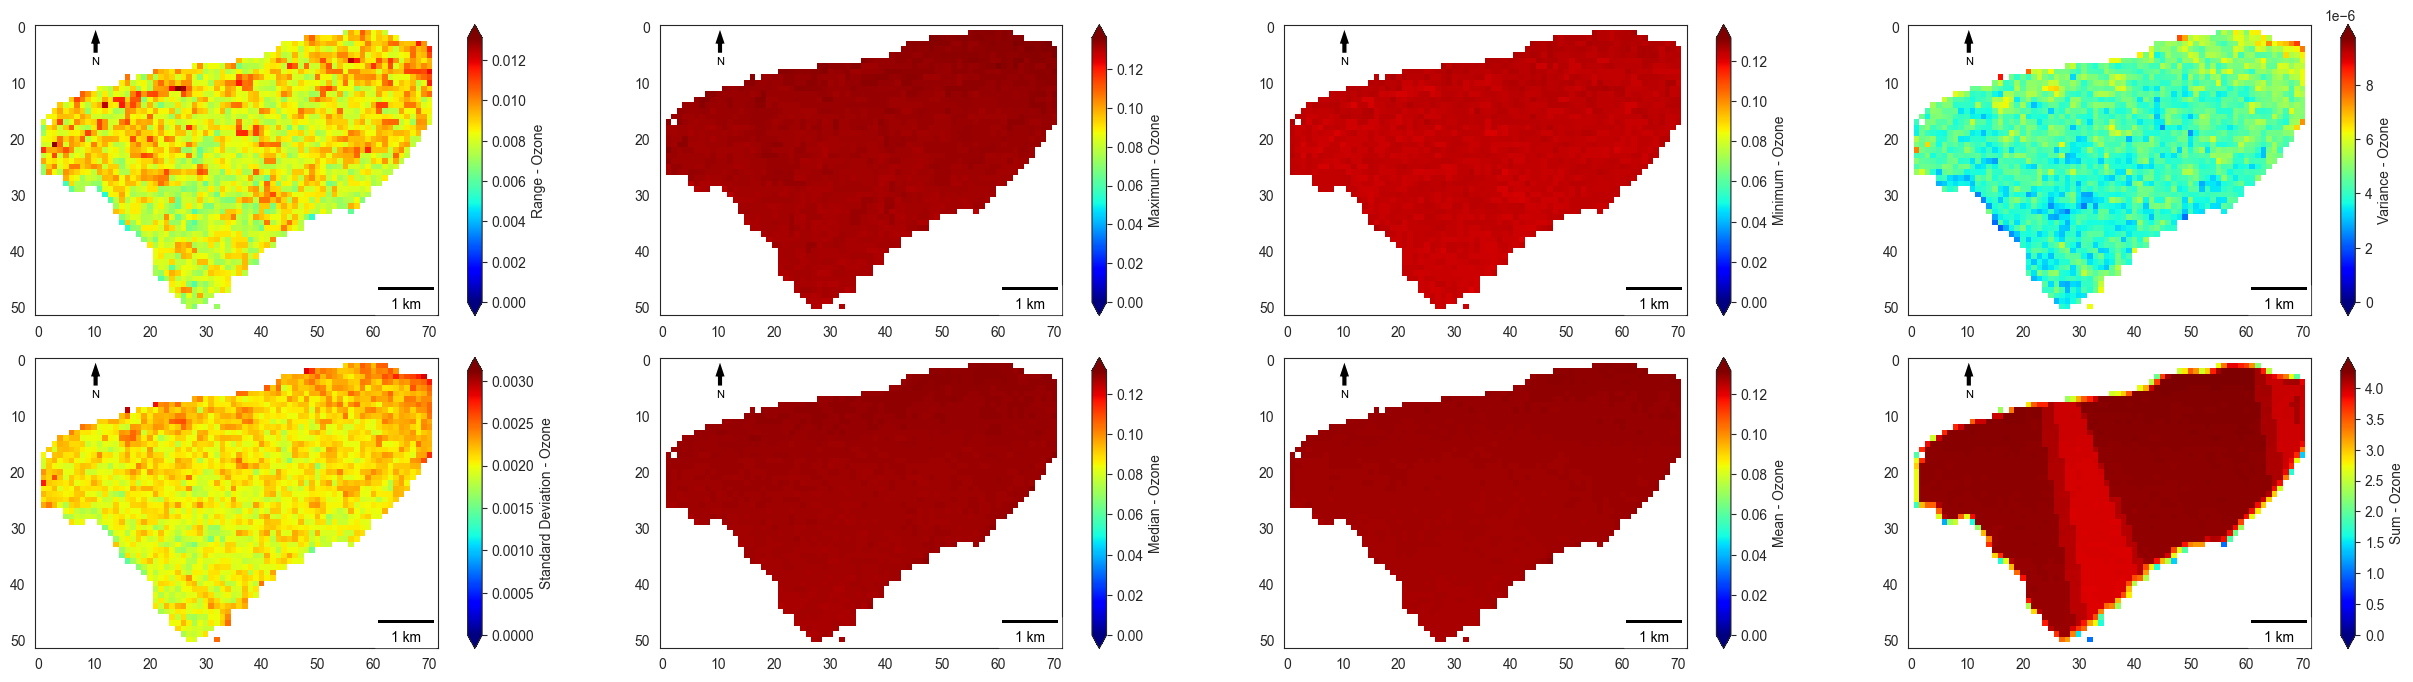

In [10]:
# Directory containing .tif files and shapefile
input_dir = "C:/Users/HP/Downloads/merida_may24/zonal_stats/zone_stack_o3.tif"
shapefile_path = "C:/Users/HP/Downloads/merida_mx/merida.shp"

# Load the shapefile for clipping
shapefile = gpd.read_file(shapefile_path)
geometries = [feature["geometry"] for feature in shapefile.__geo_interface__["features"]]

with rio.open(input_dir) as src:
# Read the data as a NumPy array
    sar_data = src.read()


    clipped_image, clipped_transform = mask(src, geometries, crop=True, filled=False)
    clipped_meta = src.meta.copy()
    
                
    stats_raw = []

    for idx, band in enumerate(src.read()):
    
        stats_raw.append({
            'band': idx + 1,
            'min': band.min(),
            'mean': band.mean(),
            'median': np.median(band),
            'max': band.max(),
            'std': int(np.std(band)),
            'var': int(np.var(band)),
            'vmin': int(band.mean() - np.std(band)),
            'vmax': int(band.mean() + np.std(band)),
    
        })
    
    summary_stats = pd.DataFrame.from_records(
        stats_raw, index='band').astype(int)
                
# summary_stats #uncomment this to print image statistics
sns.set_style("white")
fig = plt.figure(figsize=(25,20))
cmap = plt.get_cmap('jet')
fontsize=8
x, y, arrow_length = 0.15, 0.99, 0.1 
                
ax1 = plt.subplot2grid((6,4), (0,0))
ax1.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax1.transAxes, color='black')
ax2 = plt.subplot2grid((6,4), (0,1))
ax2.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax2.transAxes, color='black')
ax3 = plt.subplot2grid((6,4), (0,2))
ax3.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax3.transAxes, color='black')
ax4 = plt.subplot2grid((6,4), (0,3))
ax4.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax4.transAxes, color='black')

ax5 = plt.subplot2grid((6,4), (1,0))
ax5.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax5.transAxes, color='black')
ax6 = plt.subplot2grid((6,4), (1,1))
ax6.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax6.transAxes, color='black')
ax7 = plt.subplot2grid((6,4), (1,2))
ax7.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax7.transAxes, color='black')
ax8 = plt.subplot2grid((6,4), (1,3))
ax8.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax8.transAxes, color='black')

                 
b1 = ax1.imshow(clipped_image[0],cmap=cmap, vmin=stats_raw[0]['min'], vmax=stats_raw[0]['max'])
fig.colorbar(b1, ax=ax1, extend='both',label='Range - Ozone')
b2 = ax2.imshow(clipped_image[1], cmap=cmap, vmin=stats_raw[1]['min'], vmax=stats_raw[1]['max'])
fig.colorbar(b2, ax=ax2, extend='both',label='Maximum - Ozone')
b3 = ax3.imshow(clipped_image[2], cmap=cmap, vmin=stats_raw[2]['min'], vmax=stats_raw[2]['max'])
fig.colorbar(b3, ax=ax3,extend='both',label='Minimum - Ozone')
b4 = ax4.imshow(clipped_image[3], cmap=cmap, vmin=stats_raw[3]['min'], vmax=stats_raw[3]['max'])
fig.colorbar(b4, ax=ax4,extend='both',label='Variance - Ozone')
b5 = ax5.imshow(clipped_image[4], cmap=cmap, vmin=stats_raw[4]['min'], vmax=stats_raw[4]['max']) 
fig.colorbar(b5, ax=ax5, extend='both',label='Standard Deviation - Ozone')
b6 = ax6.imshow(clipped_image[5],cmap=cmap, vmin=stats_raw[5]['min'], vmax=stats_raw[5]['max'])
fig.colorbar(b6, ax=ax6,extend='both',label='Median - Ozone')
b7 = ax7.imshow(clipped_image[6], cmap=cmap, vmin=stats_raw[6]['min'], vmax=stats_raw[6]['max'])
fig.colorbar(b7, ax=ax7,extend='both',label='Mean - Ozone')
b8 = ax8.imshow(clipped_image[7], cmap=cmap, vmin=stats_raw[7]['min'], vmax=stats_raw[7]['max'])
fig.colorbar(b8, ax=ax8,extend='both',label='Sum - Ozone')


scalebar1 = ScaleBar(100, units="m", location='lower right')
scalebar2 = ScaleBar(100, units="m", location='lower right')
scalebar3 = ScaleBar(100, units="m", location='lower right')
scalebar4 = ScaleBar(100, units="m", location='lower right')
scalebar5 = ScaleBar(100, units="m", location='lower right')
scalebar6 = ScaleBar(100, units="m", location='lower right')
scalebar7 = ScaleBar(100, units="m", location='lower right')
scalebar8 = ScaleBar(100, units="m", location='lower right')


ax1.add_artist(scalebar1)
ax2.add_artist(scalebar2)
ax3.add_artist(scalebar3)
ax4.add_artist(scalebar4)
ax5.add_artist(scalebar5)
ax6.add_artist(scalebar6)
ax7.add_artist(scalebar7)
ax8.add_artist(scalebar8)


plt.tight_layout()
# plt.savefig("C:/Users/HP/Documents/src_paper/O3_clip2.jpeg", dpi = 1000)
# plt.savefig("C:/Users/HP/Downloads/merida_may24/images/clip_O3_nofill.jpeg")
plt.show()


In [11]:
filename = 'C:/Users/HP/Downloads/merida_may24/zonal_stats/zone_stack_so2_ord.tif'
src = rio.open(filename)

n_bands = src.meta['count']
img_shape = src.shape

band_numbers = ['1', '2', '3', '4', '5', '6','7', '8']

band_names = ['range','max','min','variance','sd','median','mean','sum']

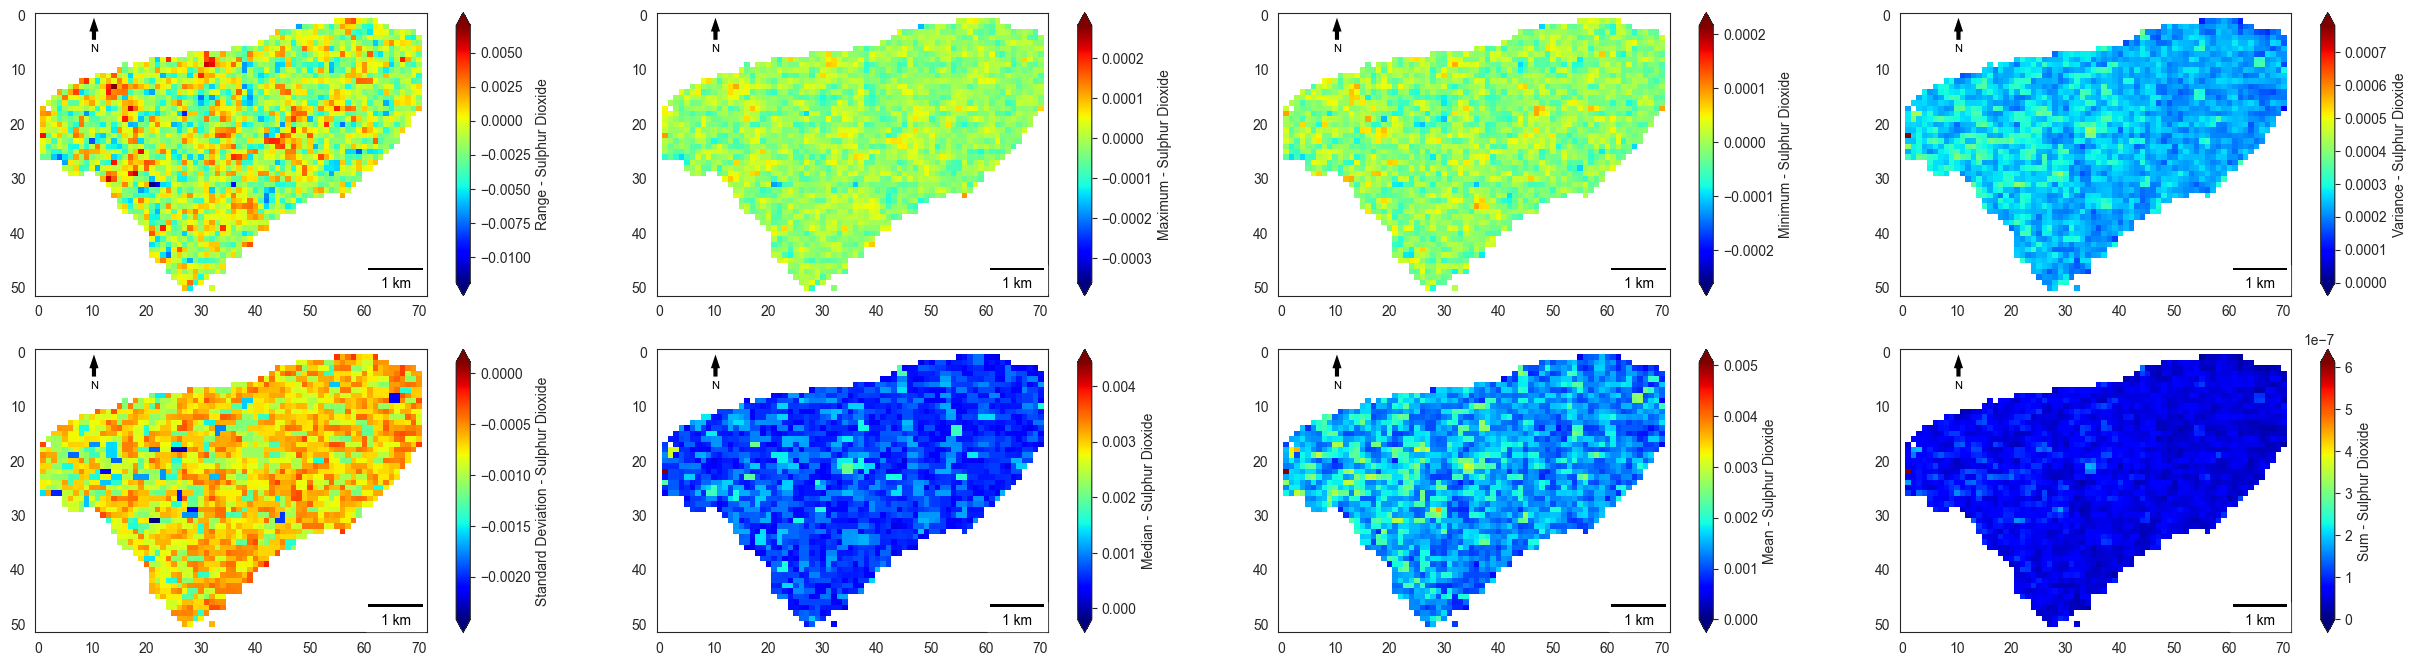

In [12]:
# Directory containing .tif files and shapefile
input_dir = "C:/Users/HP/Downloads/merida_may24/zonal_stats/zone_stack_so2.tif"
shapefile_path = "C:/Users/HP/Downloads/merida_mx/merida.shp"

# Load the shapefile for clipping
shapefile = gpd.read_file(shapefile_path)
geometries = [feature["geometry"] for feature in shapefile.__geo_interface__["features"]]

with rio.open(input_dir) as src:
# Read the data as a NumPy array
    sar_data = src.read()


    clipped_image, clipped_transform = mask(src, geometries, crop=True, filled=False)
    clipped_meta = src.meta.copy()
    
                
    stats_raw = []

    for idx, band in enumerate(src.read()):
    
        stats_raw.append({
            'band': idx + 1,
            'min': band.min(),
            'mean': band.mean(),
            'median': np.median(band),
            'max': band.max(),
            'std': int(np.std(band)),
            'var': int(np.var(band)),
            'vmin': int(band.mean() - np.std(band)),
            'vmax': int(band.mean() + np.std(band)),
    
        })
    
    summary_stats = pd.DataFrame.from_records(
        stats_raw, index='band').astype(int)
                
# summary_stats #uncomment this to print image statistics
sns.set_style("white")
fig = plt.figure(figsize=(25,20))
cmap = plt.get_cmap('jet')
fontsize=8
x, y, arrow_length = 0.15, 0.99, 0.1 
                
ax1 = plt.subplot2grid((6,4), (0,0))
ax1.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax1.transAxes, color='black')
ax2 = plt.subplot2grid((6,4), (0,1))
ax2.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax2.transAxes, color='black')
ax3 = plt.subplot2grid((6,4), (0,2))
ax3.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax3.transAxes, color='black')
ax4 = plt.subplot2grid((6,4), (0,3))
ax4.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax4.transAxes, color='black')

ax5 = plt.subplot2grid((6,4), (1,0))
ax5.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax5.transAxes, color='black')
ax6 = plt.subplot2grid((6,4), (1,1))
ax6.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax6.transAxes, color='black')
ax7 = plt.subplot2grid((6,4), (1,2))
ax7.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax7.transAxes, color='black')
ax8 = plt.subplot2grid((6,4), (1,3))
ax8.annotate('N', xy=(x, y), xytext=(x, y-arrow_length),arrowprops=dict(facecolor='black', width=4, headwidth=8),ha='center', va='top', fontsize=fontsize,xycoords=ax8.transAxes, color='black')

                 
b1 = ax1.imshow(clipped_image[0],cmap=cmap, vmin=stats_raw[0]['min'], vmax=stats_raw[0]['max'])
fig.colorbar(b1, ax=ax1, extend='both',label='Range - Sulphur Dioxide')
b2 = ax2.imshow(clipped_image[1], cmap=cmap, vmin=stats_raw[1]['min'], vmax=stats_raw[1]['max'])
fig.colorbar(b2, ax=ax2, extend='both',label='Maximum - Sulphur Dioxide')
b3 = ax3.imshow(clipped_image[2], cmap=cmap, vmin=stats_raw[2]['min'], vmax=stats_raw[2]['max'])
fig.colorbar(b3, ax=ax3,extend='both',label='Minimum - Sulphur Dioxide')
b4 = ax4.imshow(clipped_image[3], cmap=cmap, vmin=stats_raw[3]['min'], vmax=stats_raw[3]['max'])
fig.colorbar(b4, ax=ax4,extend='both',label='Variance - Sulphur Dioxide')
b5 = ax5.imshow(clipped_image[4], cmap=cmap, vmin=stats_raw[4]['min'], vmax=stats_raw[4]['max']) 
fig.colorbar(b5, ax=ax5, extend='both',label='Standard Deviation - Sulphur Dioxide')
b6 = ax6.imshow(clipped_image[5],cmap=cmap, vmin=stats_raw[5]['min'], vmax=stats_raw[5]['max'])
fig.colorbar(b6, ax=ax6,extend='both',label='Median - Sulphur Dioxide')
b7 = ax7.imshow(clipped_image[6], cmap=cmap, vmin=stats_raw[6]['min'], vmax=stats_raw[6]['max'])
fig.colorbar(b7, ax=ax7,extend='both',label='Mean - Sulphur Dioxide')
b8 = ax8.imshow(clipped_image[7], cmap=cmap, vmin=stats_raw[7]['min'], vmax=stats_raw[7]['max'])
fig.colorbar(b8, ax=ax8,extend='both',label='Sum - Sulphur Dioxide')


scalebar1 = ScaleBar(100, units="m", location='lower right')
scalebar2 = ScaleBar(100, units="m", location='lower right')
scalebar3 = ScaleBar(100, units="m", location='lower right')
scalebar4 = ScaleBar(100, units="m", location='lower right')
scalebar5 = ScaleBar(100, units="m", location='lower right')
scalebar6 = ScaleBar(100, units="m", location='lower right')
scalebar7 = ScaleBar(100, units="m", location='lower right')
scalebar8 = ScaleBar(100, units="m", location='lower right')


ax1.add_artist(scalebar1)
ax2.add_artist(scalebar2)
ax3.add_artist(scalebar3)
ax4.add_artist(scalebar4)
ax5.add_artist(scalebar5)
ax6.add_artist(scalebar6)
ax7.add_artist(scalebar7)
ax8.add_artist(scalebar8)


plt.tight_layout()
# plt.savefig("C:/Users/HP/Documents/src_paper/SO2_clip2.jpeg", dpi = 1000)
# plt.savefig("C:/Users/HP/Downloads/merida_may24/images/clip_so2_nofill.jpeg")
plt.show()


In [85]:
# Define date range
start_date = "2024-05-01"
end_date = "2024-05-30"

# Method 1: Boolean mask
mask = (Df24["datetime"] >= start_date) & (Df24["datetime"] <= end_date)
img_Df24 = Df24.loc[mask]
img_Df24

,datetime,value,parameter,unit,country,city,latitude,longitude
237,2024-05-01 00:00:00+00:00,0.068455,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
238,2024-05-01 01:00:00+00:00,0.167520,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
239,2024-05-01 02:00:00+00:00,0.223707,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
240,2024-05-01 03:00:00+00:00,0.167991,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
241,2024-05-01 04:00:00+00:00,0.084112,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
471,2024-05-17 18:00:00+00:00,46.461771,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
472,2024-05-17 19:00:00+00:00,39.054807,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
473,2024-05-17 20:00:00+00:00,48.616937,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
474,2024-05-17 21:00:00+00:00,56.427802,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111


In [86]:
mask1 = (img_Df24["parameter"] == 'pm25')
img_pm25 = img_Df24.loc[mask1]
img_pm25

,datetime,value,parameter,unit,country,city,latitude,longitude
323,2024-05-04 17:00:00+00:00,5.085717,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
324,2024-05-04 18:00:00+00:00,4.294203,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
325,2024-05-04 19:00:00+00:00,5.483184,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
326,2024-05-04 20:00:00+00:00,8.413799,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
327,2024-05-04 21:00:00+00:00,31.025634,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
471,2024-05-17 18:00:00+00:00,46.461771,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
472,2024-05-17 19:00:00+00:00,39.054807,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
473,2024-05-17 20:00:00+00:00,48.616937,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111
474,2024-05-17 21:00:00+00:00,56.427802,pm25,µg/m³,Mexico,Merida,20.973272222222,-89.624811111111


In [87]:
mask2 = (img_Df24["parameter"] == 'co')
img_co = img_Df24.loc[mask2]
img_co

,datetime,value,parameter,unit,country,city,latitude,longitude
237,2024-05-01 00:00:00+00:00,0.068455,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
238,2024-05-01 01:00:00+00:00,0.167520,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
239,2024-05-01 02:00:00+00:00,0.223707,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
240,2024-05-01 03:00:00+00:00,0.167991,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
241,2024-05-01 04:00:00+00:00,0.084112,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
452,2024-05-17 18:00:00+00:00,0.670522,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
453,2024-05-17 19:00:00+00:00,0.610868,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
454,2024-05-17 20:00:00+00:00,0.636768,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111
455,2024-05-17 21:00:00+00:00,0.756230,co,ppm,Mexico,Merida,20.973272222222,-89.624811111111


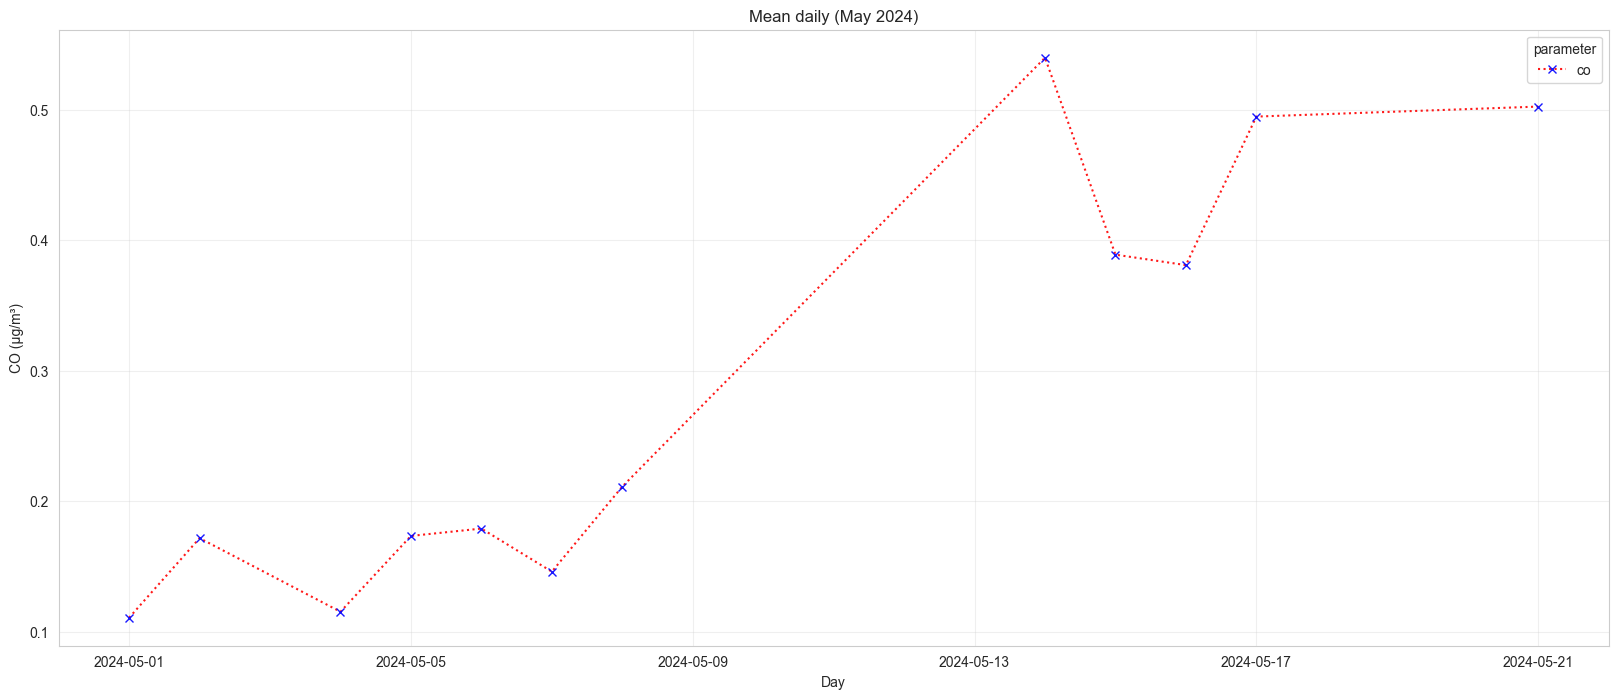

In [525]:
sns.set_style("whitegrid")
img_co.groupby([img_co["datetime"].dt.date,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='x', mec = 'b', linestyle='dotted', color='red', alpha = 0.9)
plt.ylabel('CO (µg/m³)')
plt.xlabel('Day')
plt.title('Mean daily (May 2024)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/DAYMEAN_CO_MAY_.jpeg", dpi = 1200)
plt.show()

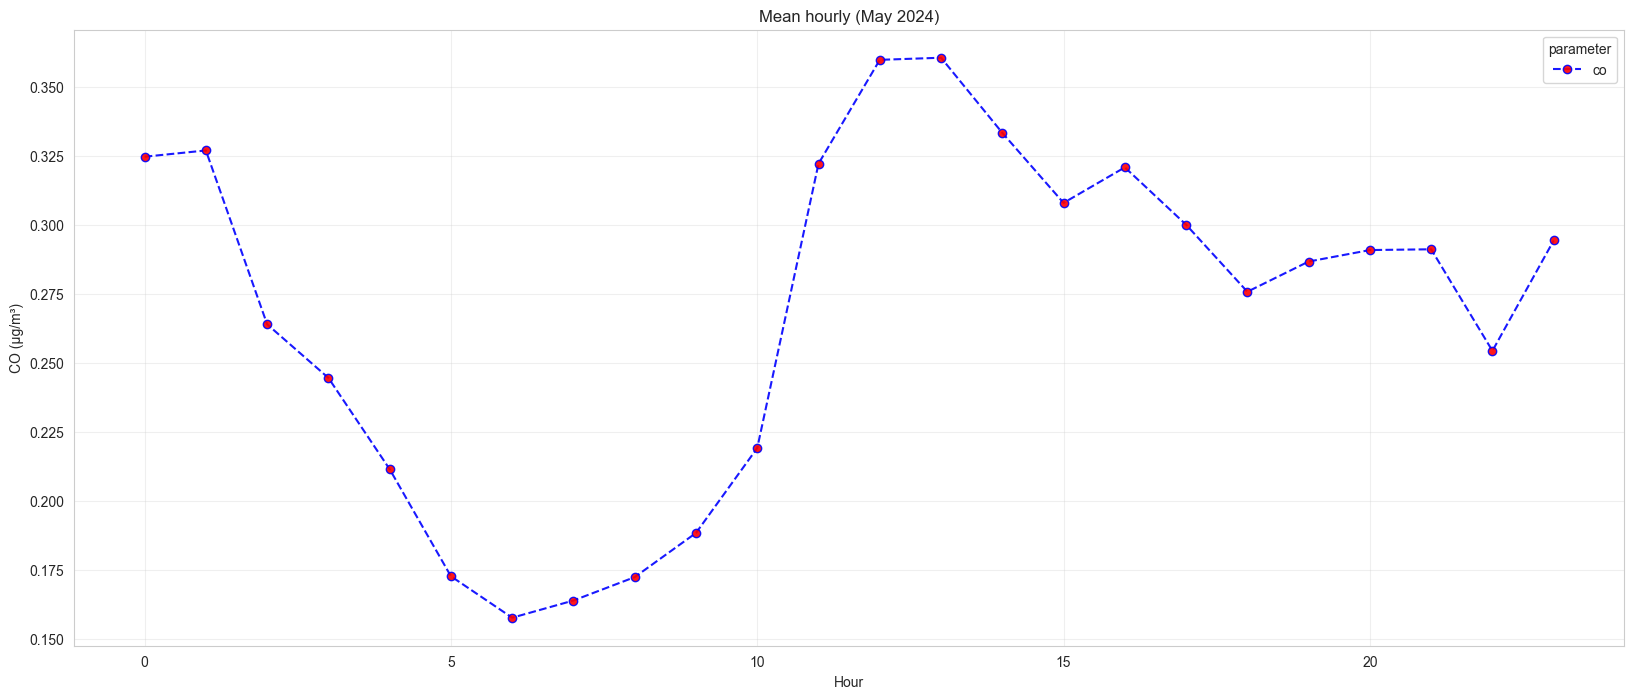

In [528]:
sns.set_style("whitegrid")
img_co.groupby([img_co["datetime"].dt.hour,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='o', mfc = 'r', linestyle='--', color='blue', alpha = 0.9)
plt.ylabel('CO (µg/m³)')
plt.xlabel('Hour')
plt.title('Mean hourly (May 2024)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/HRMEAN_CO_MAY_.jpeg", dpi = 1200)
plt.show()

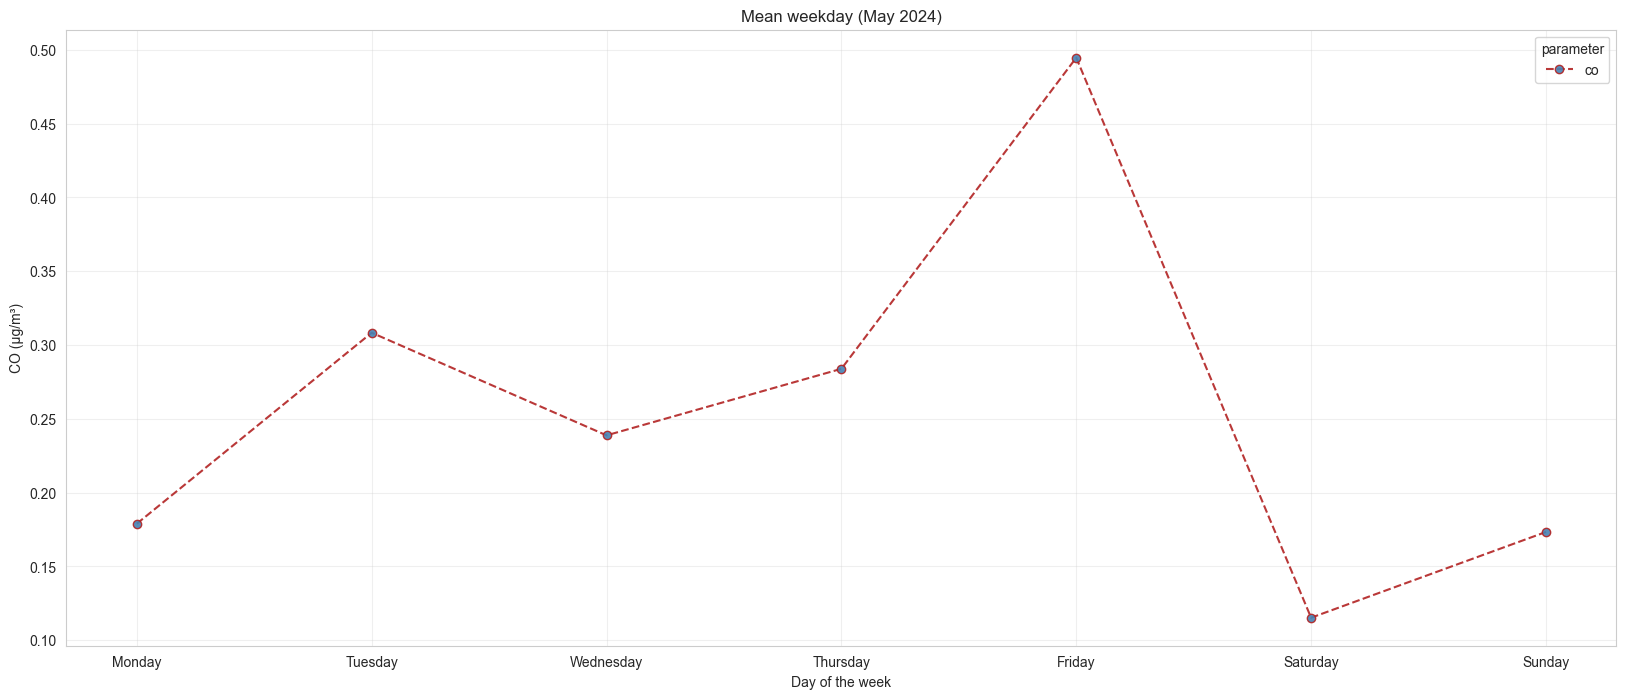

In [530]:
sns.set_style("whitegrid")
img_co.groupby([img_co["datetime"].dt.weekday,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='o', mfc = 'steelblue', linestyle='--', color = 'firebrick', alpha = 0.9)
plt.xticks([0,1,2,3,4,5,6],['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
plt.ylabel('CO (µg/m³)')
plt.xlabel('Day of the week')
plt.title('Mean weekday (May 2024)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/WEEKMEAN_CO_MAY_.jpeg", dpi = 1200)
plt.show()

In [532]:
mask = (img_Df24["parameter"] == 'no')
img_no = img_Df24.loc[mask]
img_no

,datetime,value,parameter,unit,country,city,latitude,longitude
237,2024-05-01 00:00:00+00:00,0.068455,no,ppm,Mexico,Merida,20.973272222222,-89.624811111111
238,2024-05-01 01:00:00+00:00,0.167520,no,ppm,Mexico,Merida,20.973272222222,-89.624811111111
239,2024-05-01 02:00:00+00:00,0.223707,no,ppm,Mexico,Merida,20.973272222222,-89.624811111111
240,2024-05-01 03:00:00+00:00,0.167991,no,ppm,Mexico,Merida,20.973272222222,-89.624811111111
241,2024-05-01 04:00:00+00:00,0.084112,no,ppm,Mexico,Merida,20.973272222222,-89.624811111111
...,...,...,...,...,...,...,...,...
452,2024-05-17 18:00:00+00:00,0.670522,no,ppm,Mexico,Merida,20.973272222222,-89.624811111111
453,2024-05-17 19:00:00+00:00,0.610868,no,ppm,Mexico,Merida,20.973272222222,-89.624811111111
454,2024-05-17 20:00:00+00:00,0.636768,no,ppm,Mexico,Merida,20.973272222222,-89.624811111111
455,2024-05-17 21:00:00+00:00,0.756230,no,ppm,Mexico,Merida,20.973272222222,-89.624811111111


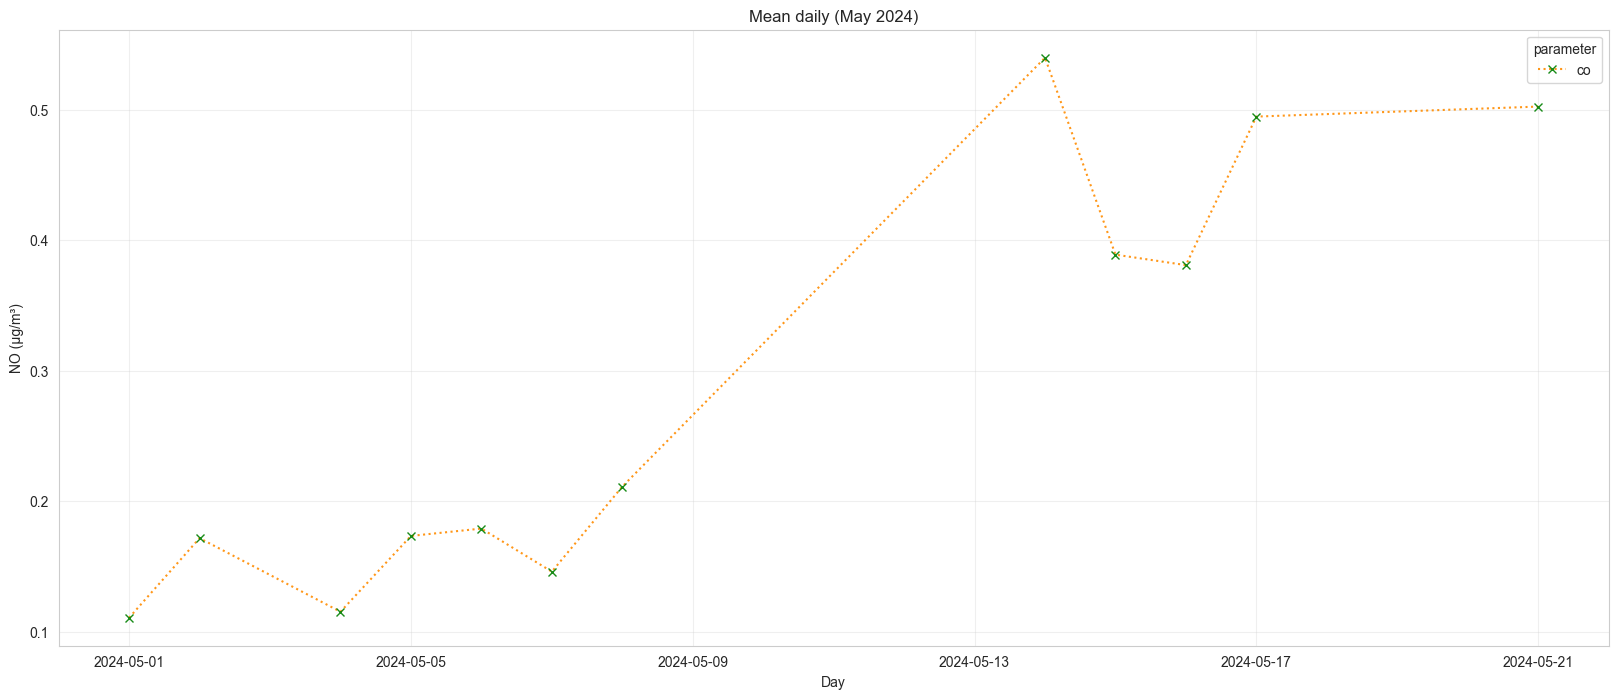

In [535]:
sns.set_style("whitegrid")
img_co.groupby([img_no["datetime"].dt.date,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='x', mec = 'green', linestyle='dotted', color='darkorange', alpha = 0.9)
plt.ylabel('NO (µg/m³)')
plt.xlabel('Day')
plt.title('Mean daily (May 2024)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/DAYMEAN_NO_MAY_.jpeg", dpi = 1200)
plt.show()

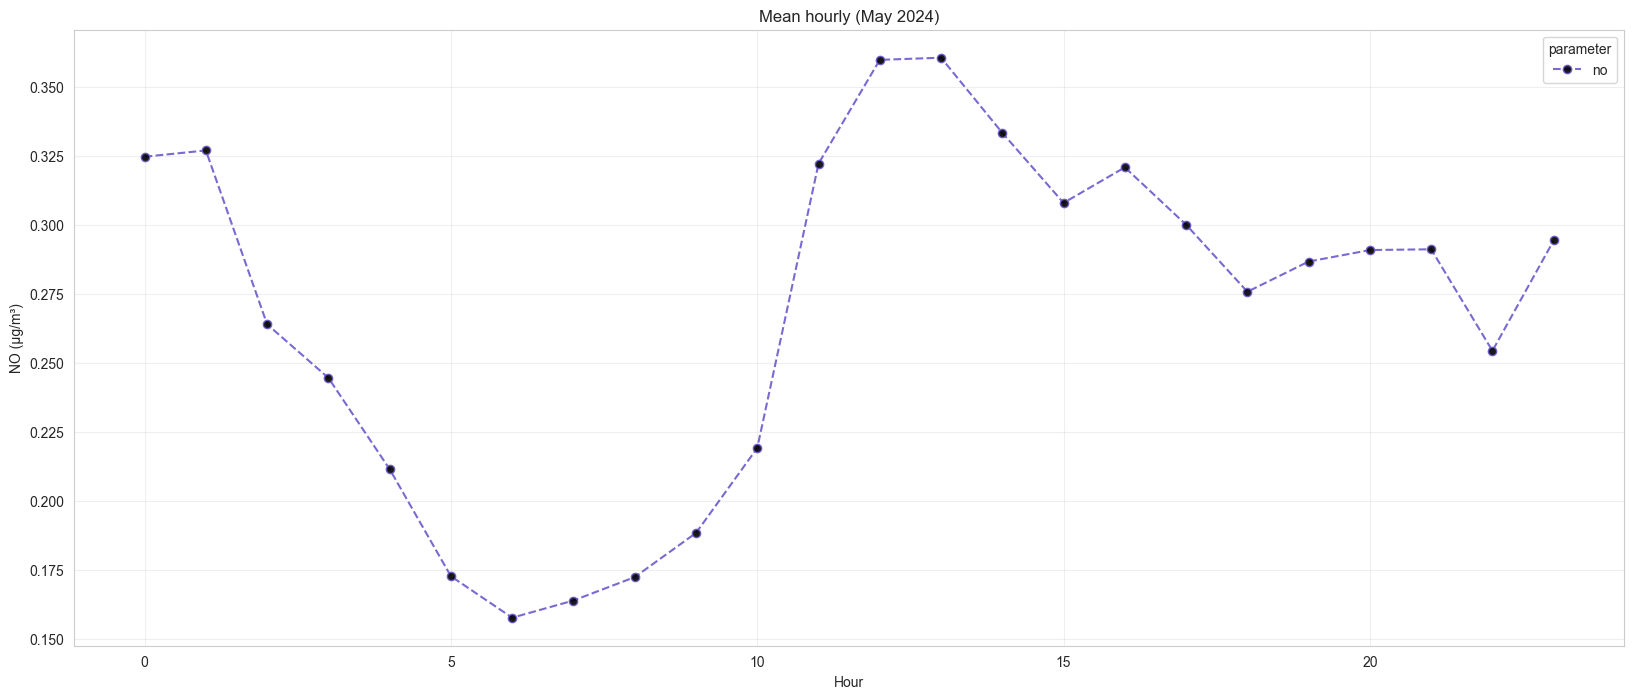

In [537]:
sns.set_style("whitegrid")
img_no.groupby([img_no["datetime"].dt.hour,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='o', mfc = 'k', linestyle='--', color='slateblue', alpha = 0.9)
plt.ylabel('NO (µg/m³)')
plt.xlabel('Hour')
plt.title('Mean hourly (May 2024)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/HRMEAN_NO_MAY_.jpeg", dpi = 1200)
plt.show()

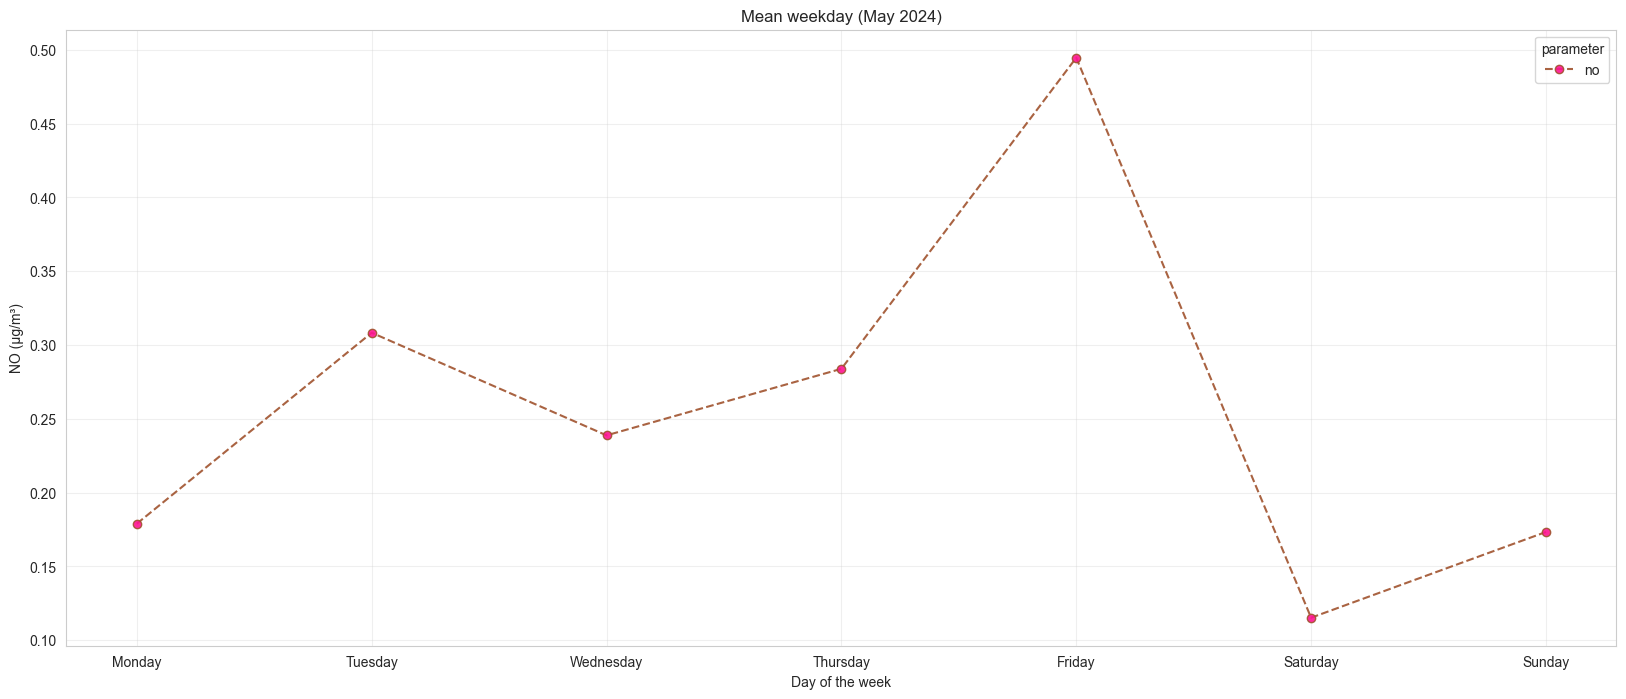

In [540]:
sns.set_style("whitegrid")
img_no.groupby([img_no["datetime"].dt.weekday,'parameter'])["value"].mean().unstack().plot(figsize=(20, 8),marker='o', mfc='deeppink', linestyle='--', color = 'sienna', alpha = 0.9)
plt.xticks([0,1,2,3,4,5,6],['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
plt.ylabel('NO (µg/m³)')
plt.xlabel('Day of the week')
plt.title('Mean weekday (May 2024)')
loc='best'
plt.grid(alpha=0.3)
# plt.savefig("C:/Users/HP/Documents/src_paper/WEEKMEAN_NO_MAY_.jpeg", dpi = 1200)
plt.show()

In [274]:
np.mean(img_pm25.value),np.std(img_pm25.value),np.median(img_pm25.value),np.var(img_pm25.value),np.max(img_pm25.value),np.min(img_pm25.value),np.sum(img_pm25.value)

(np.float64(23.560132757751635),
 17.44178653447089,
 np.float64(21.0133823),
 304.21591751405003,
 109.906021,
 0.101672239,
 np.float64(3604.700311936))

In [92]:
np.mean(img_co.value),np.std(img_co.value),np.median(img_co.value),np.var(img_co.value),np.max(img_co.value),np.min(img_co.value),np.sum(img_co.value)

(np.float64(0.2700755774163636),
 0.17790674815997193,
 np.float64(0.2110976275),
 0.031650811040855674,
 0.935190018,
 0.0261233307,
 np.float64(59.416627031599994))

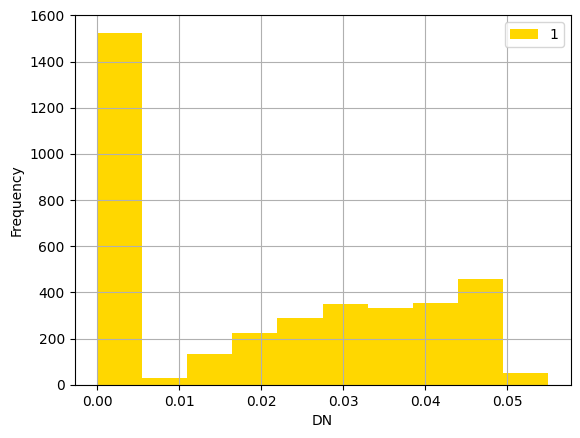

In [7]:
img = rio.open("C:/Users/HP/Downloads/merida_may24/zonal_stats/zone_stack_co.tif")
data = img.read(1)
show_hist(data, bins = 10, title='')
plt.show()

[np.float64(-0.8303530448263363), np.float64(-0.3773430276180103), np.float64(0.7690511801371792), np.float64(-0.3786531583530696), np.float64(0.04905191915375846), np.float64(0.3879034688153605), np.float64(0.1406055439074913), np.float64(-0.003135435894853873), np.float64(-0.6711910206379565), np.float64(-0.013791684022883778), np.float64(-0.4562699230806327), np.float64(-0.053931346342010945), np.float64(-0.008727414875011615), np.float64(0.02557038618098243), np.float64(-0.5969054047195153), np.float64(-0.27470641448654015), np.float64(0.5965410185649774), np.float64(1.0055241141732283), np.float64(0.16734767932796954), np.float64(0.02120901414000574), np.float64(-0.21488144115182725), np.float64(-0.7034547201679271), np.float64(-1.1114460027532354), np.float64(-0.26812688513647154), np.float64(-0.2184159755706787), np.float64(0.3236031896139244), np.float64(-0.31051288189349713), np.float64(-0.29529778282506913), np.float64(-0.18522717875819053), np.float64(-0.28024912243015077), 

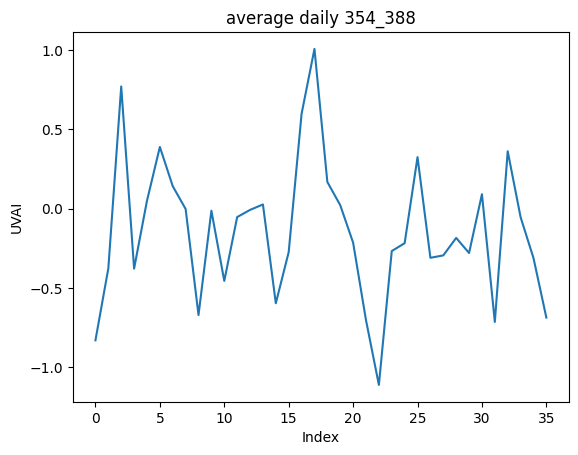

In [11]:
directory = "C:/Users/HP/Downloads/merida_may24/reproject_clip/54_88/"
shapefile_path = "C:/Users/HP/Downloads/merida_mx/merida.shp"

shapefile = gpd.read_file(shapefile_path)
geometries = [feature["geometry"] for feature in shapefile.__geo_interface__["features"]]

davg1 = []
# Get a list of all files in the directory
files = [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith(('.tif'))]

# Open and process the first 5 images
for file in files:
    with rio.open(file) as src:
        band1 = src.read(1)
        clipped_image, clipped_transform = mask(src, geometries, crop=True, filled=False)
        clipped_meta = src.meta.copy()
        avg = clipped_image.mean()
        # print(avg)
        davg1.append(avg)

print(davg1) 
plt.plot(davg1)
plt.title('average daily 354_388')
plt.xlabel('Index')
plt.ylabel('UVAI')
plt.grid(False)
plt.show()

[np.float64(-0.2576183980156173), np.float64(-0.3646062115045983), np.float64(-0.8853865030493571), np.float64(-0.33503091060290247), np.float64(0.7287463057223041), np.float64(0.06575735551970345), np.float64(0.4461571700929657), np.float64(-0.025901741399073672), np.float64(-0.32024304307886686), np.float64(-0.8390268549867349), np.float64(-0.5397239703896605), np.float64(-0.010652951888964085), np.float64(-0.06566954840517375), np.float64(-0.3276576833967798), np.float64(-0.4828692668798972), np.float64(-0.6254838279102636), np.float64(-0.03140532058021198), np.float64(0.8007837612307137), np.float64(1.1520609697957678), np.float64(0.16601492658776432), np.float64(-0.045265201593561274), np.float64(-0.7087311116826067), np.float64(-1.1056702358916128), np.float64(-0.23888572982594936), np.float64(-0.17432989676793417), np.float64(-0.812147956870562), np.float64(0.360065904487089), np.float64(-0.4944044602858079), np.float64(-0.6207607416965184), np.float64(-0.3914199952156313), np.f

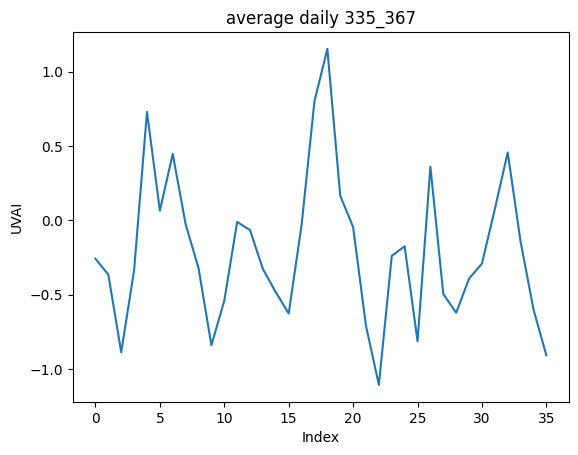

In [12]:
directory = "C:/Users/HP/Downloads/merida_may24/reproject_clip/35_67/"
shapefile_path = "C:/Users/HP/Downloads/merida_mx/merida.shp"

shapefile = gpd.read_file(shapefile_path)
geometries = [feature["geometry"] for feature in shapefile.__geo_interface__["features"]]


davg2 = []
# Get a list of all files in the directory
files = [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith(('.tif'))]

# Open and process the first 5 images
for file in files:
    with rio.open(file) as src:
        band1 = src.read(1)
        clipped_image, clipped_transform = mask(src, geometries, crop=True, filled=False)
        clipped_meta = src.meta.copy()
        avg = clipped_image.mean()
        # print(avg)
        davg2.append(avg)

print(davg2)
plt.plot(davg2)
plt.title('average daily 335_367')
plt.xlabel('Index')
plt.ylabel('UVAI')
plt.grid(False)
plt.show()

[np.float64(-0.8198446561396874), np.float64(-0.32755401213405844), np.float64(1.0411389651146412), np.float64(-0.2583100927157665), np.float64(0.1175177778516497), np.float64(0.5443176509827141), np.float64(-0.05017120181548578), np.float64(0.1742100644608832), np.float64(-0.06780901719271606), np.float64(-0.7518502147859082), np.float64(-0.46205219786844137), np.float64(0.06771758826003274), np.float64(0.04747589988443849), np.float64(-0.01661916190960142), np.float64(-0.5404412051786607), np.float64(0.036184809934264005), np.float64(0.9674821347372052), np.float64(-0.31938770679021794), np.float64(1.447691909910187), np.float64(0.2482438424333411), np.float64(0.11712451429899817), np.float64(-0.6352707397895352), np.float64(-1.124984931091339), np.float64(-0.13684055762954905), np.float64(-0.16980944077173868), np.float64(0.4865344863340079), np.float64(-0.29581581748329794), np.float64(-0.3987479231476244), np.float64(-0.7590801900327497), np.float64(-0.28138560633505544), np.float

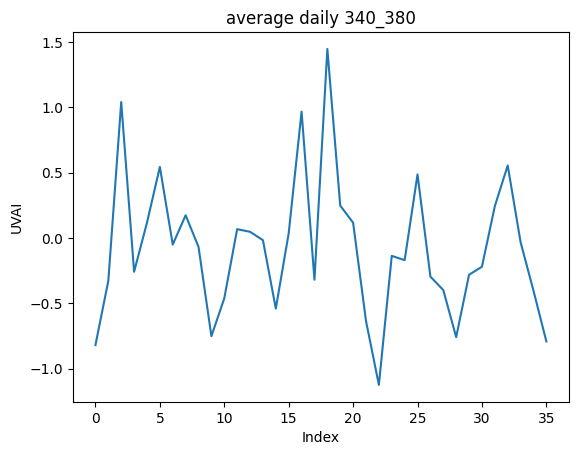

In [13]:
directory = "C:/Users/HP/Downloads/merida_may24/reproject_clip/40_80/"
shapefile_path = "C:/Users/HP/Downloads/merida_mx/merida.shp"

shapefile = gpd.read_file(shapefile_path)
geometries = [feature["geometry"] for feature in shapefile.__geo_interface__["features"]]


davg3 = []
# Get a list of all files in the directory
files = [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith(('.tif'))]

# Open and process the first 5 images
for file in files:
    with rio.open(file) as src:
        band1 = src.read(1)
        clipped_image, clipped_transform = mask(src, geometries, crop=True, filled=False)
        clipped_meta = src.meta.copy()
        avg = clipped_image.mean()
        # print(avg)
        davg3.append(avg)

print(davg3)
plt.plot(davg3)
plt.title('average daily 340_380')
plt.xlabel('Index')
plt.ylabel('UVAI')
plt.grid(False)
plt.show()

In [14]:
vg1 = np.array(davg1)
vg2 = np.array(davg2)
vg3 = np.array(davg3)

Polynomial degree 4:
  Coefficients: [-2.00072109 -1.29483694  1.48576104  1.59111304  0.0181176 ]
  Equation:         4         3         2
-2.001 x - 1.295 x + 1.486 x + 1.591 x + 0.01812
  R²: 0.637203
  Adjusted R²: 0.590391
  RMSE: 0.3491


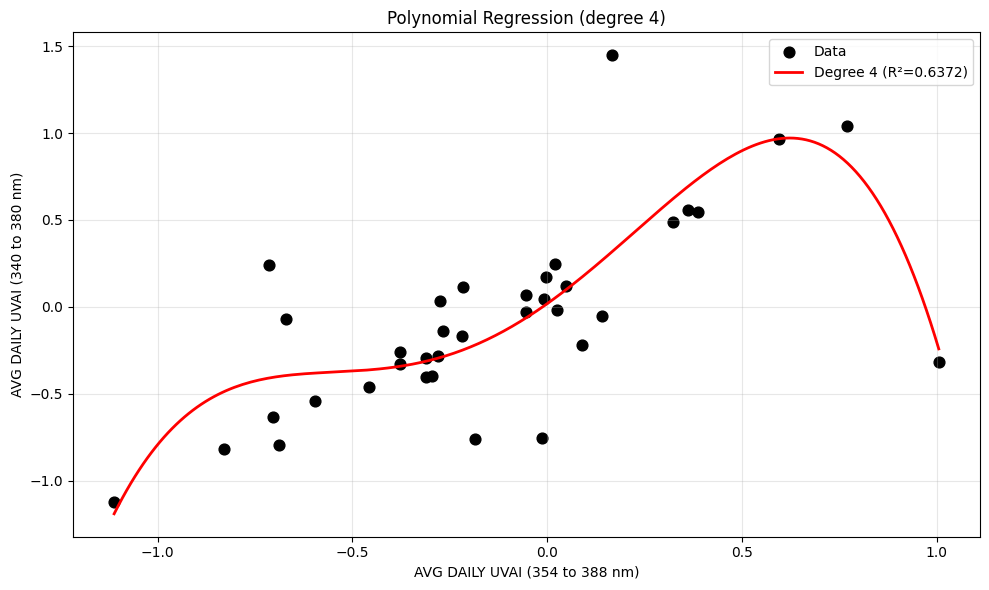

In [113]:
# -----------------------------
# 1. Data
# -----------------------------
x0 = vg1
y0 = vg3
x = x0
y = y0

# -----------------------------
# 2. Fit Polynomial of Chosen Degree
# -----------------------------
degree = 4 # Change this to test different polynomial degrees
coeffs = np.polyfit(x, y, degree)  # Fit polynomial
poly_fn = np.poly1d(coeffs)        # Create polynomial function

# -----------------------------
# 3. Predictions & RMSE
# -----------------------------
y_pred = poly_fn(x)
ss_res = np.sum((y - y_pred) ** 2)  # Residual sum of squares
n = len(x)
p = degree + 1  # Number of parameters
rmse = np.sqrt(ss_res / (n - p))    # RMSE with degrees of freedom correction

# -----------------------------
# 4. R² and Adjusted R²
# -----------------------------
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - ss_res / ss_tot
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p)

# -----------------------------
# 5. Output Results
# -----------------------------
print(f"Polynomial degree {degree}:")
print(f"  Coefficients: {coeffs}")
print(f"  Equation: {poly_fn}")
print(f"  R²: {r2:.6f}")
print(f"  Adjusted R²: {adj_r2:.6f}")
print(f"  RMSE: {rmse:.4f}")

# -----------------------------
# 6. Plot
# -----------------------------
x_smooth = np.linspace(x.min(), x.max(), 200)
plt.figure(figsize=(10, 6))
plt.scatter(x, y, color='k', s=60, label='Data')
plt.plot(x_smooth, poly_fn(x_smooth), 'r-', lw=2,
         label=f'Degree {degree} (R²={r2:.4f})')
plt.xlabel('AVG DAILY UVAI (354 to 388 nm)')
plt.ylabel('AVG DAILY UVAI (340 to 380 nm)')
plt.title(f'Polynomial Regression (degree {degree})')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
# plt.savefig("C:/Users/HP/Documents/src_paper/88_80_POLYFIT_regress.jpeg", dpi = 1200)
plt.show()

In [114]:
im25 = img_pm25.groupby([img_pm25["datetime"].dt.date,'parameter'])["value"].mean()
im25

datetime    parameter
2024-05-04  pm25         17.005247
2024-05-05  pm25         14.768262
2024-05-06  pm25         14.977708
2024-05-07  pm25         15.677073
2024-05-08  pm25         18.644530
2024-05-14  pm25         41.705499
2024-05-15  pm25         28.110194
2024-05-16  pm25         22.608988
2024-05-17  pm25         33.933973
2024-05-21  pm25         13.498540
Name: value, dtype: float64

In [115]:
i25 = im25.values
i25

array([17.00524662, 14.768262  , 14.97770832, 15.67707343, 18.64452972,
       41.70549896, 28.11019429, 22.60898843, 33.93397292, 13.4985402 ])

In [145]:
vg1

array([-0.83035304, -0.37734303,  0.76905118, -0.37865316,  0.04905192,
        0.38790347,  0.14060554, -0.00313544, -0.67119102, -0.01379168,
       -0.45626992, -0.05393135, -0.00872741,  0.02557039, -0.5969054 ,
       -0.27470641,  0.59654102,  1.00552411,  0.16734768,  0.02120901,
       -0.21488144, -0.70345472, -1.111446  , -0.26812689, -0.21841598,
        0.32360319, -0.31051288, -0.29529778, -0.18522718, -0.28024912,
        0.08993373, -0.71456912,  0.36069547, -0.05440825, -0.31173215,
       -0.68732708])

In [155]:
window_size = 27

In [156]:
weights = np.ones(window_size)/window_size
moving_avg = np.convolve(vg1, weights, mode = 'valid')

In [157]:
print(moving_avg)

[-0.11131253 -0.09149567 -0.08438027 -0.12324324 -0.10588817 -0.13417043
 -0.13517813 -0.14240087 -0.15383037 -0.15442801]


Polynomial degree 5:
  Coefficients: [ 7.07533251e-07 -9.61105843e-05  5.06242214e-03 -1.28969119e-01
  1.58384040e+00 -7.60189617e+00]
  Equation:            5             4            3         2
7.075e-07 x - 9.611e-05 x + 0.005062 x - 0.129 x + 1.584 x - 7.602
  R²: 0.704729
  Adjusted R²: 0.335639
  RMSE: 0.0201


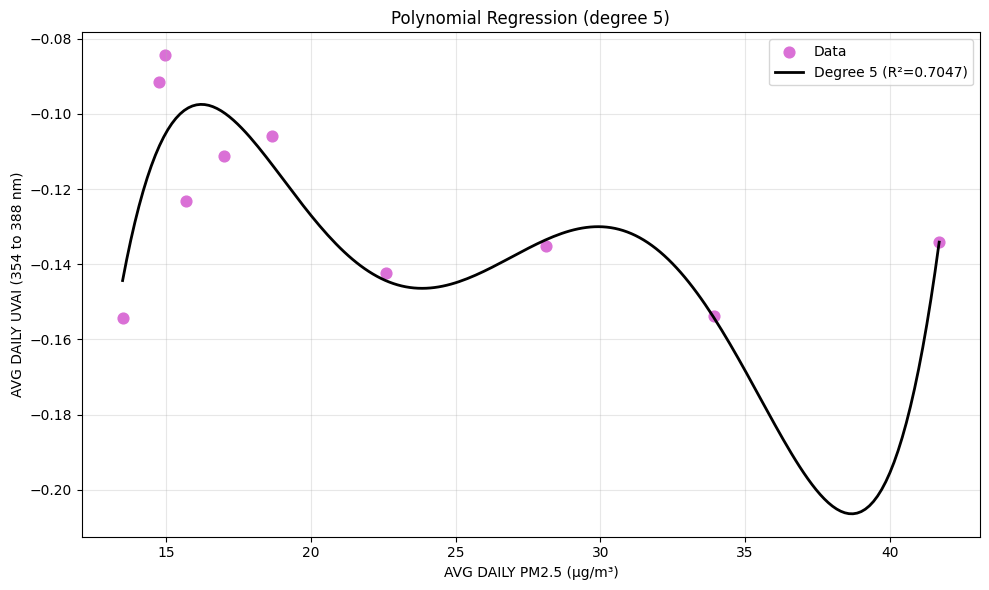

In [163]:
# -----------------------------
# 1. Data
# -----------------------------
# x0 = vg1[0:10]
y0 = moving_avg
x0 = i25
y = y0
x = x0

# -----------------------------
# 2. Fit Polynomial of Chosen Degree
# -----------------------------
degree = 5 # Change this to test different polynomial degrees
coeffs = np.polyfit(x, y, degree)  # Fit polynomial
poly_fn = np.poly1d(coeffs)        # Create polynomial function

# -----------------------------
# 3. Predictions & RMSE
# -----------------------------
y_pred = poly_fn(x)
ss_res = np.sum((y - y_pred) ** 2)  # Residual sum of squares
n = len(x)
p = degree + 1  # Number of parameters
rmse = np.sqrt(ss_res / (n - p))    # RMSE with degrees of freedom correction

# -----------------------------
# 4. R² and Adjusted R²
# -----------------------------
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - ss_res / ss_tot
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p)

# -----------------------------
# 5. Output Results
# -----------------------------
print(f"Polynomial degree {degree}:")
print(f"  Coefficients: {coeffs}")
print(f"  Equation: {poly_fn}")
print(f"  R²: {r2:.6f}")
print(f"  Adjusted R²: {adj_r2:.6f}")
print(f"  RMSE: {rmse:.4f}")

# -----------------------------
# 6. Plot
# -----------------------------
x_smooth = np.linspace(x.min(), x.max(), 200)
plt.figure(figsize=(10, 6))
plt.scatter(x, y, color='orchid', s=60, label='Data')
plt.plot(x_smooth, poly_fn(x_smooth), 'k-', lw=2,
         label=f'Degree {degree} (R²={r2:.4f})')
plt.xlabel('AVG DAILY PM2.5 (µg/m³)')
plt.ylabel('AVG DAILY UVAI (354 to 388 nm)')
plt.title(f'Polynomial Regression (degree {degree})')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
# plt.savefig("C:/Users/HP/Documents/src_paper/88_PM25_POLYFIT_regress.jpeg", dpi = 1200)
plt.show()

#### Comparing means

In [5]:
# Sample means

mean1 = 0.06
mean2 = 0.04

# Sample SD

sd1 = 0.008
sd2 = 0.003

# Sample sizes

n1 = 10
n2 = 10

# Null hypothesis: The mean difference is zero
# Alt hypothesis: The mean difference is not zero

null_mean = 0

# Calculate the pooled standard deviation

pooled_std_dev = np.sqrt(((n1-1)*sd1**2+(n2-1)*sd2**2)/(n1+n2-2))

# Calculate the standard error difference

se = pooled_std_dev*np.sqrt((1/n1) + (1/n2))

# Calculate the t-statistics

t_statistic = (mean1 - mean2 - null_mean)/se

# Degrees of freedom
df = n1+ n2 -2

# Calculate the critical values at a given alpha level (two tailed test)

alpha = 0.05

crit_val_left = t.ppf(alpha/2, df=df)
crit_val_right = t.ppf(1-alpha/2, df=df)

# Calculate the p-value

p_value = 2*(1 - t.cdf(abs(t_statistic), df=df))

# Print the results

print("Mean difference:", mean1 - mean2)
print("Standard error:", se)
print("T-Statistic:", t_statistic)
print("P-Value:", p_value)
print("Critical Values:", crit_val_left, crit_val_right)

# Make a decision based on p-value and critical values

if p_value < alpha:
    print("Reject the null hypothesis. There is evidence of a significant difference between the two samples.")

else:

    print("Fail to reject the null hypothesis. There is no evidence of a significant difference between the two samples.")

Mean difference: 0.019999999999999997
Standard error: 0.002701851217221259
T-Statistic: 7.402332101976052
P-Value: 7.271632889160884e-07
Critical Values: -2.10092204024096 2.10092204024096
Reject the null hypothesis. There is evidence of a significant difference between the two samples.


## References: 

##### 1. CONABIO (2011) ‘División política estatal 1:250000. 2010’. Ciudad de Mexico: Comisión Nacional para el Conocimiento y Uso de la Biodiversidad. 
##### 2. Copernicus browser (No date). Available at: https://browser.dataspace.copernicus.eu/?zoom=9&lat=20.79463&lng=-89.08264&themeId=DEFAULT-THEME&visualizationUrl=U2FsdGVkX188TC4Bxd5YAkpVrRgf3t1dTCWRymCb2ro5dDyQBU4GgnDcIr3p1dU1Ru1gmNNcWnr%2FILAJcPOr7lqWX%2BiZnlpVZGrk1z5b0EA4K9cm20yW6p7PLZ%2BvL1En&datasetId=S2_L2A_CDAS&demSource3D=%22MAPZEN%22&cloudCoverage=30&dateMode=SINGLE (Accessed: 20 May 2026). 
##### 3. Dietrich (2015) Numpy.polyfit: How to get 1-sigma uncertainty around the estimated curve?, Stack Overflow. Available at: https://stackoverflow.com/a/28528966 (Accessed: 26 May 2026). 
##### 4.Inegi (no date) Publicaciones y Mapas, Instituto Nacional de Estadística y Geográfica (INEGI). Available at: https://inegi.org.mx/app/biblioteca/ficha.html?upc=794551132494 (Accessed: 11 June 2026). 
##### 5. Phillips, J. (2018) Nonlinear regression with python - what’s a simple method to fit this data better?, Stack Overflow. Available at: https://stackoverflow.com/a/51975675 (Accessed: 26 May 2026). 
##### 6. Looti, M (2025). Learning Pandas: Data Aggregation and Visualization with Groupby and Plotting. PSYCHOLOGICAL STATISTICS. Retrieved from https://statistics.arabpsychology.com/pandas-use-groupby-and-plot-with-examples/
##### 7. Statistics 365. 365 Data Science. Retrieved from https://statisticscalculators.com/linear-regression-calculator/